# 08. Data-Driven Spatiotemporal Clustering (Grid Search & STFT)

This notebook implements cluster-based permutation testing (Maris & Oostenveld, 2007) using a **Short-Time Fourier Transform (STFT)** with a Hanning window and dB baseline correction.

**Spatiotemporal Grid Resolution:** The STFT is computed with a 500 ms Hanning window segments and 20 ms sliding steps. The cluster-based permutation test is run directly on this windowed grid to prevent double-smoothing and dilution of transient differences.

To identify the optimal spatiotemporal coordinates for EEGNet, we perform a **grid search** over:
- **ROI Modes:** `'none'` (whole-scalp), `'broad'` (anterior/posterior split), and `'narrow'` (paper's exact ROIs)
- **Cluster-Forming Thresholds (`p_uncorrected`):** `[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001]`
- **Cluster-Survival Thresholds (`p_corrected`):** `[0.001, 0.005, 0.01, 0.05, 0.10, 0.15, 0.25, 0.50]`
- **Bands:** Theta and Alpha
- **Baseline Correction:** Trial-level dB correction

## Spatiotemporal Clustering Pipeline

```mermaid
flowchart LR
    subgraph Preprocessing [Preprocessing]
        direction TB
        A[Epochs per task: C vs IP or IM vs IP] --> B[Scipy STFT: Hanning window, 500ms segment length, 20ms steps]
        B --> C[dB Baseline Correction: 10 * log10 power / baseline_power]
        C --> D[Crop to Active Window: 0.0 to 1.5s]
        D --> E[Average across frequencies: Theta or Alpha]
        E --> G[Compute Subject Difference Maps: IP - C or IP - IM]
    end
    
    subgraph Analysis [Clustering Analysis]
        direction TB
        H[Paired t-test at every channel-time point] --> I[Threshold at uncorrected p_uncorrected]
        I --> J[Group adjacent points into clusters using Delaunay spatial and temporal adjacency]
        J --> K[Permutation testing: 10000 random label shuffles]
        K --> L[Filter clusters with cluster-level p_corrected]
        L --> M[Save cluster coordinates to cluster_definitions.json]
    end

    Preprocessing --> Analysis

    style Preprocessing stroke-dasharray: 5 5
    style Analysis fill:none,stroke:none
```


In [6]:
import sys
import importlib
import importlib.util
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
import json
import pickle
from dataclasses import dataclass
from scipy.signal import stft
from scipy.stats import t, ttest_1samp

# Add src to path
IN_COLAB = "google.colab" in sys.modules
NOTEBOOK_DIR = Path.cwd()

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive", force_remount=True)
    preferred_src = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    candidates = [
        preferred_src,
        preferred_src / "src",
        Path("/content/drive/MyDrive/TFG_Nils_2026/src"),
        Path("/content/drive/MyDrive/TFG_Nils_2026"),
    ]

    # Colab sometimes exposes Drive folders in a different place than expected
    # or does not follow Drive shortcuts. Do a bounded search before giving up.
    drive_root = Path("/content/drive")
    if drive_root.exists():
        try:
            candidates.extend(path.parent for path in drive_root.glob("*/*/*/br_analysis/__init__.py"))
            candidates.extend(path.parent for path in drive_root.glob("*/*/*/*/br_analysis/__init__.py"))
            candidates.extend(path.parent for path in drive_root.glob("*/*/*/*/*/br_analysis/__init__.py"))
        except OSError:
            pass

    SRC_DIR = next((p for p in candidates if (p / "br_analysis" / "__init__.py").exists()), preferred_src)
else:
    SRC_DIR = NOTEBOOK_DIR.parent

src_dir_str = str(SRC_DIR)
sys.path = [p for p in sys.path if p != src_dir_str]
sys.path.insert(0, src_dir_str)
importlib.invalidate_caches()

print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Using source directory: {SRC_DIR}")
print(f"br_analysis folder exists: {(SRC_DIR / 'br_analysis').exists()}")
print(f"br_analysis __init__ exists: {(SRC_DIR / 'br_analysis' / '__init__.py').exists()}")
br_analysis_spec = importlib.util.find_spec("br_analysis")
print(f"br_analysis import spec: {br_analysis_spec}")
if br_analysis_spec is None and (SRC_DIR / "br_analysis" / "__init__.py").exists():
    package_init = SRC_DIR / "br_analysis" / "__init__.py"
    br_analysis_spec = importlib.util.spec_from_file_location(
        "br_analysis",
        package_init,
        submodule_search_locations=[str(package_init.parent)],
    )
    br_analysis_module = importlib.util.module_from_spec(br_analysis_spec)
    sys.modules["br_analysis"] = br_analysis_module
    br_analysis_spec.loader.exec_module(br_analysis_module)
if IN_COLAB and not (SRC_DIR / "br_analysis" / "__init__.py").exists():
    print("Could not see br_analysis from Colab. Contents at expected parent:")
    expected_parent = Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if expected_parent.exists():
        print([p.name for p in expected_parent.iterdir()][:50])
    else:
        print(f"Missing expected parent: {expected_parent}")
        for parent in [Path("/content/drive/MyDrive"), Path("/content/drive")]:
            if parent.exists():
                print(f"Contents of {parent}:", [p.name for p in parent.iterdir()][:50])

from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

paths = detect_project_paths("clustering", in_colab=IN_COLAB)

print(f"Project directory: {paths.project_dir}")
print(f"Cache directory: {paths.cache_dir}")
print(f"Figures directory: {paths.figures_dir}")

Mounted at /content/drive
Notebook directory: /content
Using source directory: /content/drive/MyDrive/TFG_Nils_2026/03_Codi
br_analysis folder exists: True
br_analysis __init__ exists: True
br_analysis import spec: ModuleSpec(name='br_analysis', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7df8e6989100>, origin='/content/drive/MyDrive/TFG_Nils_2026/03_Codi/br_analysis/__init__.py', submodule_search_locations=['/content/drive/MyDrive/TFG_Nils_2026/03_Codi/br_analysis'])
Project directory: /content/drive/MyDrive/TFG_Nils_2026
Cache directory: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache
Figures directory: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures


In [7]:
@dataclass(frozen=True)
class TimeWindowGrid:
    starts: np.ndarray
    stops: np.ndarray
    centers: np.ndarray
    window_sec: float
    step_sec: float

    @classmethod
    def from_times(cls, times: np.ndarray, *, window_sec: float, step_sec: float) -> "TimeWindowGrid":
        time_step = float(np.median(np.diff(times)))
        sfreq_est = 1.0 / time_step
        win_samples = max(2, int(round(window_sec * sfreq_est)))
        step_samples = max(1, int(round(step_sec * sfreq_est)))
        starts = np.arange(0, len(times) - win_samples + 1, step_samples)
        stops = starts + win_samples
        centers = np.array([times[s:e].mean() for s, e in zip(starts, stops)], dtype=np.float32)
        return cls(starts=starts, stops=stops, centers=centers, window_sec=window_sec, step_sec=step_sec)


def load_task_dataset_cached(task_name, paths):
    """Load and cache the raw epochs dataset resampled to 128 Hz."""
    spec = RawEpochSpec(picks=None, bandpass=None, resample_sfreq=128.0)
    task = get_task_config(task_name, paths.analysis_root, analysis_window=(-0.75, 1.5))

    cache_path = paths.cache_dir / f"raw_epochs_dataset_{task_name}_sfreq128.joblib"
    if cache_path.exists():
        print(f"[{task_name.upper()}] Loading cached dataset from {cache_path}...")
        return joblib.load(cache_path)

    print(f"[{task_name.upper()}] Loading raw dataset from scratch (this may take a few minutes)...")
    dataset = load_raw_epoch_dataset(paths, task, spec, verbose=True)
    print(f"[{task_name.upper()}] Saving dataset to cache...")
    joblib.dump(dataset, cache_path, compress=3)
    return dataset

In [8]:
# Define spatial search space configurations (None, Broad, Narrow)
THETA_ROIS = {
    "none": None,  # Whole-Scalp
    "broad": [
        "Fp1",
        "Fp2",
        "AF7",
        "AF3",
        "AFz",
        "AF4",
        "AF8",
        "F7",
        "F5",
        "F3",
        "F1",
        "Fz",
        "F2",
        "F4",
        "F6",
        "F8",
        "FT7",
        "FC5",
        "FC3",
        "FC1",
        "FCz",
        "FC2",
        "FC4",
        "FC6",
        "FT8",
        "T7",
        "C5",
        "C3",
        "C1",
        "Cz",
        "C2",
        "C4",
        "C6",
        "T8",
    ],
    "narrow": ["Fz", "FCz", "Cz"],  # Paper's frontomedial ROI
}

ALPHA_ROIS = {
    "none": None,  # Whole-Scalp
    "broad": [
        "TP7",
        "CP5",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "CP6",
        "TP8",
        "P7",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO7",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2",
    ],
    "narrow": ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"],  # Paper's parieto-occipital ROI
}

In [9]:
def compute_stft_difference_maps(
    task_name,
    band_name,
    freqs_range,
    paths,
    roi_channels=None,
    baseline=(-0.74, -0.24),
    active_window=(0.25, 1.25),
):
    """
    Compute STFT dB power difference maps per subject, averaged over target frequencies
    directly on the 500 ms Hanning-windowed STFT grid to prevent double-smoothing.
    Supports optional baseline correction.
    """
    dataset = load_task_dataset_cached(task_name, paths)
    X_raw = dataset.X
    y = dataset.y
    subjects = dataset.subjects
    ch_names = list(dataset.channel_names)
    sfreq = dataset.sfreq
    info = dataset.info.copy()

    montage = mne.channels.make_standard_montage("standard_1005")
    info.set_montage(montage, match_case=False, on_missing="ignore")

    if roi_channels is not None:
        roi_indices = [ch_names.index(ch) for ch in roi_channels if ch in ch_names]
        ch_names_to_use = [ch_names[i] for i in roi_indices]
        info_to_use = mne.create_info(ch_names=ch_names_to_use, sfreq=sfreq, ch_types="eeg")
        info_to_use.set_montage(montage, match_case=False, on_missing="ignore")
    else:
        ch_names_to_use = ch_names
        info_to_use = info

    subject_ids = np.unique(subjects)
    n_subjects = len(subject_ids)
    tmin_crop, tmax_crop = active_window

    # Compute STFT parameters (Hanning window of 0.5s segment, 20ms steps, FFT padded to 1s to get 1Hz bins)
    nperseg = int(round(0.5 * sfreq))
    hop = int(round(0.02 * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    # Dummy calculation to get times grid
    x_dummy = X_raw[0:2]
    f, t_stft, _ = stft(
        x_dummy,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    times_stft = -0.75 + t_stft
    active_mask = (times_stft >= tmin_crop) & (times_stft <= tmax_crop)
    times_cropped = times_stft[active_mask]

    X_diff = np.zeros((n_subjects, len(times_cropped), len(ch_names_to_use)))

    for sub_idx, subj_id in enumerate(subject_ids):
        sub_mask = subjects == subj_id
        X_sub = X_raw[sub_mask]
        y_sub = y[sub_mask]

        X_cond0 = X_sub[y_sub == 0]
        X_cond1 = X_sub[y_sub == 1]

        if len(X_cond0) == 0 or len(X_cond1) == 0:
            continue

        _, _, z0 = stft(
            X_cond0,
            fs=sfreq,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft,
            boundary="zeros",
            padded=True,
            axis=-1,
        )
        power_cond0 = np.mean(np.abs(z0) ** 2, axis=0)

        _, _, z1 = stft(
            X_cond1,
            fs=sfreq,
            window="hann",
            nperseg=nperseg,
            noverlap=noverlap,
            nfft=nfft,
            boundary="zeros",
            padded=True,
            axis=-1,
        )
        power_cond1 = np.mean(np.abs(z1) ** 2, axis=0)

        if roi_channels is not None:
            picks_idx = [ch_names.index(ch) for ch in roi_channels if ch in ch_names]
            power_cond0 = power_cond0[picks_idx]
            power_cond1 = power_cond1[picks_idx]

        if baseline is not None:
            bmask = (times_stft >= baseline[0]) & (times_stft <= baseline[1])
            b0 = power_cond0[..., bmask].mean(axis=-1, keepdims=True)
            power_db0 = 10 * np.log10((power_cond0 + 1e-20) / (b0 + 1e-20))

            b1 = power_cond1[..., bmask].mean(axis=-1, keepdims=True)
            power_db1 = 10 * np.log10((power_cond1 + 1e-20) / (b1 + 1e-20))
        else:
            # Raw absolute dB power
            power_db0 = 10 * np.log10(power_cond0 + 1e-20)
            power_db1 = 10 * np.log10(power_cond1 + 1e-20)

        power_db0 = power_db0[..., active_mask]
        power_db1 = power_db1[..., active_mask]

        f_mask = (f >= freqs_range[0]) & (f <= freqs_range[1])
        band_power0 = np.mean(power_db0[:, f_mask, :], axis=1)
        band_power1 = np.mean(power_db1[:, f_mask, :], axis=1)

        diff = band_power1 - band_power0
        X_diff[sub_idx] = diff.T

    return X_diff, times_cropped, ch_names_to_use, info_to_use, info

In [10]:
def run_grid_search_multi_roi(
    task_name,
    band_name,
    freqs_range,
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001],
    p_corrected=[0.001, 0.005, 0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50],
    n_permutations=2000,
    baseline=(-0.74, -0.24),
):
    """
    Run grid search over multiple ROI modes, cluster-forming (p_uncorrected) and cluster-survival (p_corrected) thresholds.
    Performed directly on raw STFT time-frequency grid.
    """
    results = []
    diff_maps_cache = {}

    from scipy.stats import t as scipy_t
    from mne.channels import find_ch_adjacency

    for roi_mode in roi_modes:
        if band_name.lower().startswith("theta"):
            roi_channels = THETA_ROIS[roi_mode]
        elif band_name.lower().startswith("alpha"):
            roi_channels = ALPHA_ROIS[roi_mode]
        else:
            roi_channels = None

        X_diff, times_cropped, ch_names_to_use, info_to_use, full_info = compute_stft_difference_maps(
            task_name, band_name, freqs_range, paths, roi_channels, baseline=baseline
        )

        diff_maps_cache[roi_mode] = (X_diff, times_cropped, ch_names_to_use, info_to_use, full_info)

        adjacency, _ = find_ch_adjacency(info_to_use, ch_type="eeg")
        df = X_diff.shape[0] - 1

        print(f"\n==================================================================")
        base_str = "dB baseline" if baseline is not None else "No baseline"
        print(f"GRID SEARCH FOR: {task_name.upper()} - {band_name.upper()} ({roi_mode.upper()} ROI, {base_str})")
        print(f"==================================================================")

        for p_uncorr in p_uncorrected:
            t_crit = scipy_t.ppf(1 - p_uncorr / 2, df)
            print(f"\nRunning permutation test for p_uncorrected = {p_uncorr:.3f} (t_crit = {t_crit:.3f})...")

            F_obs, clusters, cluster_p_values, H0 = mne.stats.spatio_temporal_cluster_1samp_test(
                X_diff,
                threshold=t_crit,
                adjacency=adjacency,
                n_permutations=n_permutations,
                tail=0,
                n_jobs=-1,
                verbose=False,
            )

            for p_corr in p_corrected:
                sig_idxs = np.where(cluster_p_values < p_corr)[0]
                print(
                    f"  -> p_corrected = {p_corr:.3f}: Found {len(sig_idxs)} significant clusters (out of {len(clusters)} candidates)"
                )

                for rank, idx in enumerate(sig_idxs):
                    p_val = cluster_p_values[idx]
                    time_idxs, ch_idxs = clusters[idx]
                    unique_ch_idxs = np.unique(ch_idxs)
                    chs_in_cluster = [ch_names_to_use[i] for i in unique_ch_idxs]
                    tmin_val = float(times_cropped[time_idxs.min()])
                    tmax_val = float(times_cropped[time_idxs.max()])

                    results.append(
                        {
                            "roi_mode": roi_mode,
                            "p_uncorrected": p_uncorr,
                            "p_corrected": p_corr,
                            "cluster_idx": idx,
                            "p_value": p_val,
                            "tmin": tmin_val,
                            "tmax": tmax_val,
                            "channels": chs_in_cluster,
                            "mask": [time_idxs, ch_idxs],
                            "size_channels": len(chs_in_cluster),
                            "size_windows": len(np.unique(time_idxs)),
                        }
                    )
                    print(
                        f"     Cluster #{rank+1} (p={p_val:.4f}): Time {tmin_val:.3f}s to {tmax_val:.3f}s | Channels ({len(chs_in_cluster)}): {chs_in_cluster[:5]}..."
                    )

    return results, diff_maps_cache

In [11]:
CHANNEL_ORDER = [
    "Fp1",
    "Fp2",
    "AF7",
    "AF3",
    "AF4",
    "AF8",
    "F7",
    "F5",
    "F3",
    "F1",
    "Fz",
    "F2",
    "F4",
    "F6",
    "F8",
    "FT7",
    "FC5",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "FC6",
    "FT8",
    "T7",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "T8",
    "TP7",
    "CP5",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "CP6",
    "TP8",
    "P7",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO7",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]


def plot_grid_cluster(X_diff, times, ch_names_to_use, info, cluster, task_name, band_name, paths):
    """
    Plot t-value heatmap highlighting the single cluster from the grid and the scalp topomap.
    """
    t_vals, _ = ttest_1samp(X_diff, popmean=0.0, axis=0)
    t_vals = t_vals.T

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_to_use)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]
    t_vals_ordered = t_vals[ordered_idx, :]

    roi_mode = cluster.get("roi_mode", "none")

    # Heatmap
    # Linear function: y = m*x + n where x is len(present_order), m=0.14, n=2.5
    fig_height = len(present_order) * 0.14 + 2.5
    fig, ax = plt.subplots(figsize=(9, fig_height))
    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    # Format labels: every 5th center has a label, others are blank to prevent overlaps
    xticklabels = [f"{t:.2f}s" if idx % 5 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax,
        cmap="RdBu_r",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": f"t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})"},
    )

    # Original significance masking: outline significant cells, shade non-significant in black with alpha=0.1
    sig_mask = np.zeros((len(ch_names_to_use), len(times)), dtype=bool)
    time_mask, ch_mask = cluster["mask"]
    for t_i, ch_i in zip(time_mask, ch_mask):
        sig_mask[ch_i, t_i] = True
    sig_mask_ordered = sig_mask[ordered_idx, :]

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if sig_mask_ordered[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.5))
            else:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.1, linewidth=0))

    # LaTeX formatting for p_uncorrected and p_corrected and omit NONE ROI
    roi_label = f"{roi_mode.capitalize()} ROI, " if roi_mode.lower() in ["broad", "narrow"] else ""
    ax.set_title(
        f"Grid Cluster ({roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$): {task_name.upper()} - {band_name.capitalize()}"
    )
    ax.set_xlabel("Time Window Centers (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    heatmap_path = (
        paths.figures_dir
        / f"grid_heatmap_{task_name}_{band_name}_{roi_mode}_uncorr{cluster['p_uncorrected']}_corr{cluster['p_corrected']}.png"
    )
    plt.savefig(heatmap_path, dpi=180, bbox_inches="tight")
    plt.show()

    # Topomap
    topo_path = (
        paths.figures_dir
        / f"grid_topomap_{task_name}_{band_name}_{roi_mode}_uncorr{cluster['p_uncorrected']}_corr{cluster['p_corrected']}.png"
    )
    fig, ax = plt.subplots(figsize=(6, 5))

    active_times = list(set(time_mask))
    t_avg = np.mean(t_vals[:, active_times], axis=1)

    t_avg_full = np.zeros(len(info.ch_names))
    mask_full = np.zeros(len(info.ch_names), dtype=bool)
    for ch_idx, ch_name in enumerate(ch_names_to_use):
        full_idx = info.ch_names.index(ch_name)
        t_avg_full[full_idx] = t_avg[ch_idx]
        if ch_name in cluster["channels"]:
            mask_full[full_idx] = True

    t_max = max(abs(t_avg_full.min()), abs(t_avg_full.max()))
    if t_max == 0:
        t_max = 1.0

    im, _ = mne.viz.plot_topomap(
        t_avg_full,
        info,
        axes=ax,
        mask=mask_full,
        mask_params=dict(marker="o", markerfacecolor="red", markersize=6, markeredgecolor="k"),
        cmap="RdBu_r",
        vlim=(-t_max, t_max),
        show=False,
    )
    cbar = fig.colorbar(im, ax=ax, orientation="vertical", shrink=0.7)
    cbar.set_label(f"Mean t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})")
    ax.set_title(
        f"Grid Topomap ({roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$): {task_name.upper()} - {band_name.capitalize()}"
    )
    plt.tight_layout()
    plt.savefig(topo_path, dpi=180, bbox_inches="tight")
    plt.show()

In [12]:
def plot_all_significant_unique_clusters(results, diff_maps_cache, task_name, band_name, paths):
    """
    Plot all unique significant clusters found across different ROI modes and thresholds.
    """
    seen_masks = []
    unique_count = 0

    for c in results:
        roi_mode = c["roi_mode"]
        mask_key = (roi_mode, c["p_uncorrected"], c["cluster_idx"])
        if mask_key in seen_masks:
            continue
        seen_masks.append(mask_key)
        unique_count += 1

        X_diff, times, chs, _, full_info = diff_maps_cache[roi_mode]

        print(
            f"\n---> Plotting Unique Cluster #{unique_count} (ROI: {roi_mode}, p_uncorr={c['p_uncorrected']}, survived p_corr={c['p_corrected']})"
        )
        plot_grid_cluster(X_diff, times, chs, full_info, c, task_name, band_name, paths)

    if unique_count == 0:
        print(f"No significant clusters were found to plot for {task_name.upper()} - {band_name.upper()}.")

## 1. C vs IP Grid Search & Visualizations

In this section, we sweep across the space configurations (`none`, `broad`, `narrow`) and thresholds to find significant spatiotemporal clusters for Congruent vs Incongruent Pure.

In [16]:
# C vs IP
# Theta
c_theta_res, c_theta_cache = run_grid_search_multi_roi(
    task_name="c_vs_ip",
    band_name="theta",
    freqs_range=(4, 7),
    paths=paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001],
    n_permutations=10000,
)

# Alpha
c_alpha_res, c_alpha_cache = run_grid_search_multi_roi(
    task_name="c_vs_ip",
    band_name="alpha",
    freqs_range=(8, 12),
    paths=paths,
    roi_modes=["none"],
    p_uncorrected=[0.20, 0.10, 0.05, 0.01, 0.005, 0.001, 0.0001],
    n_permutations=10000,
)

[C_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_c_vs_ip_sfreq128.joblib...



GRID SEARCH FOR: C_VS_IP - THETA (NONE ROI, dB baseline)

Running permutation test for p_uncorrected = 0.200 (t_crit = 1.319)...
  -> p_corrected = 0.001: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.005: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.010: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.050: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.100: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.150: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.200: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.250: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.300: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.350: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.400: Found 0 significant clusters (out of 9 candidates)
  -> p_corrected = 0.50


Plotting C vs IP Theta significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


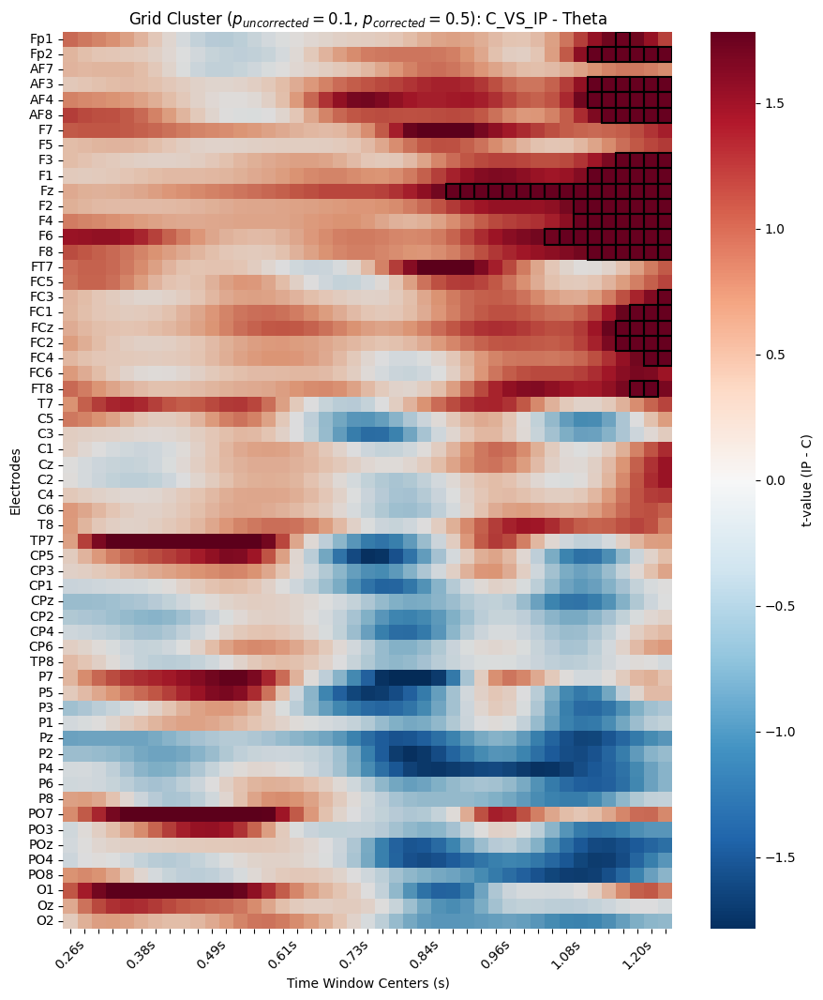

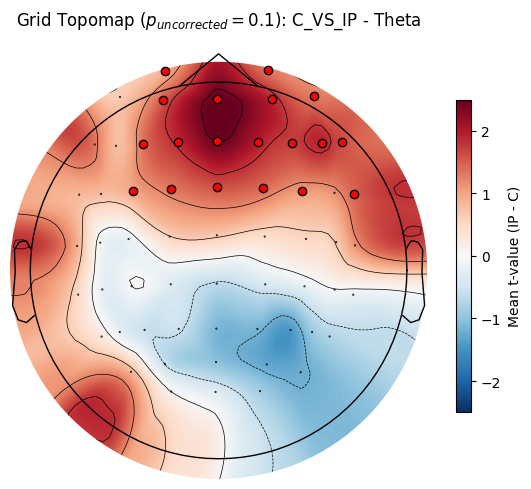


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.05, survived p_corr=0.4)


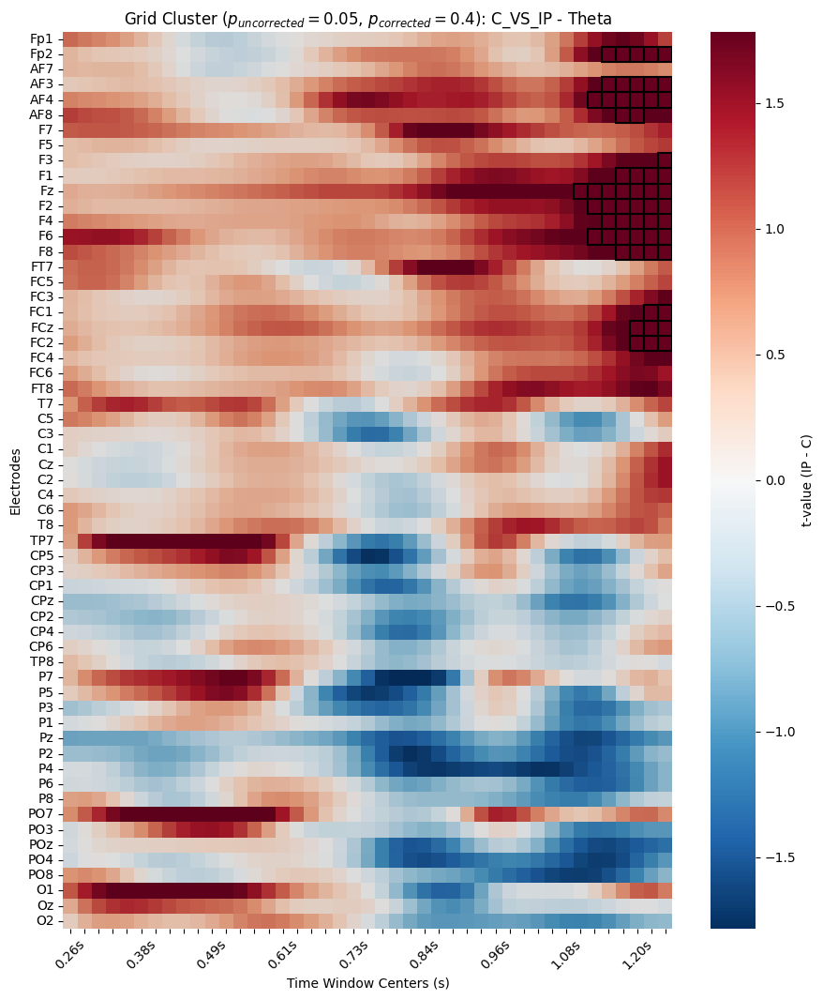

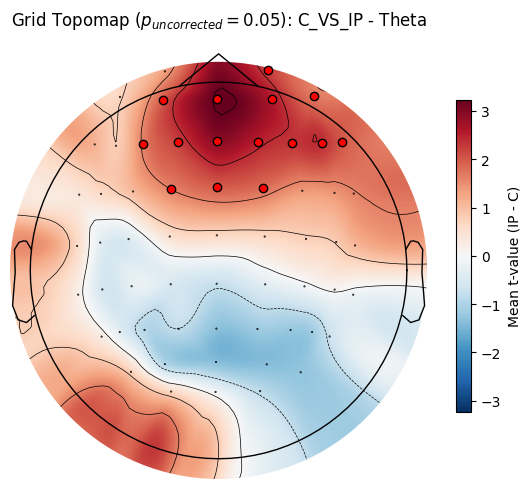


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.01, survived p_corr=0.25)


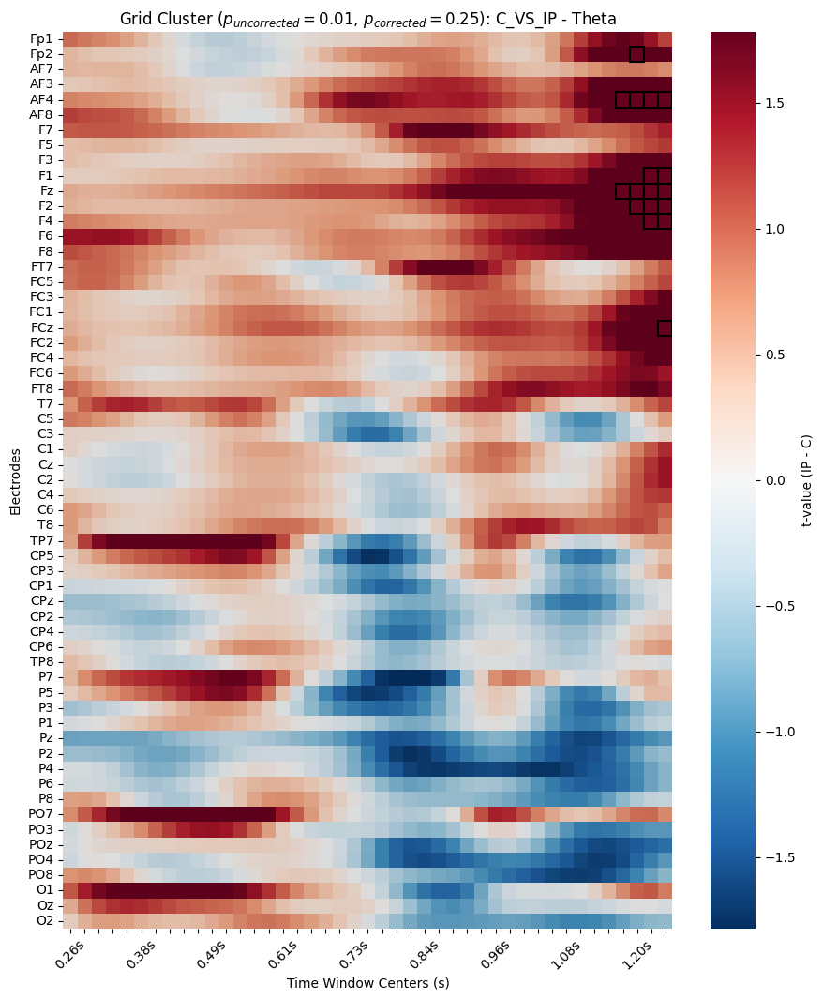

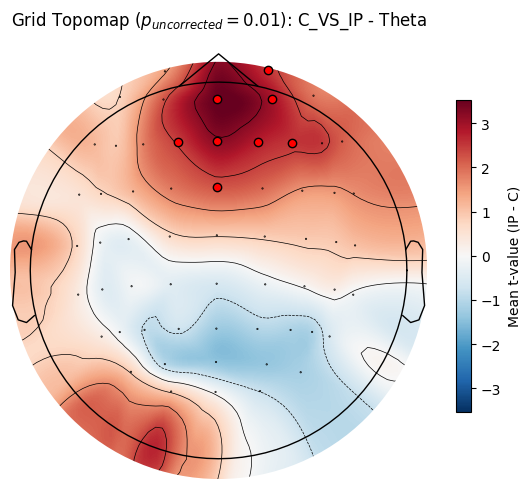


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.005, survived p_corr=0.2)


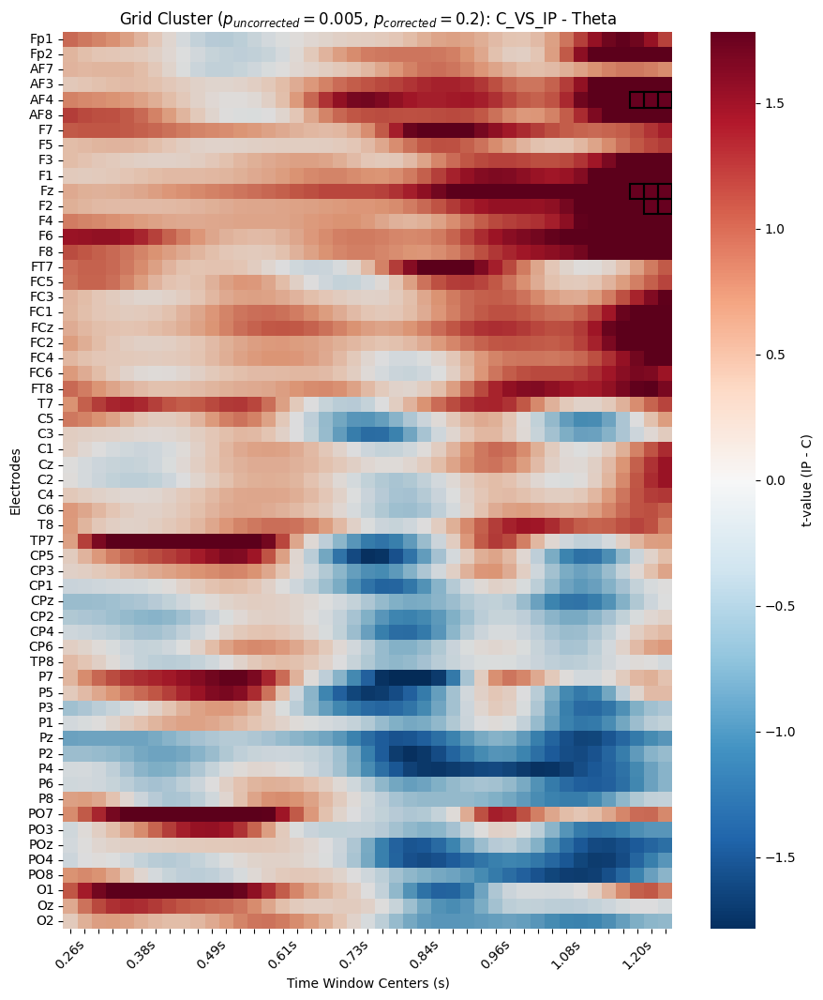

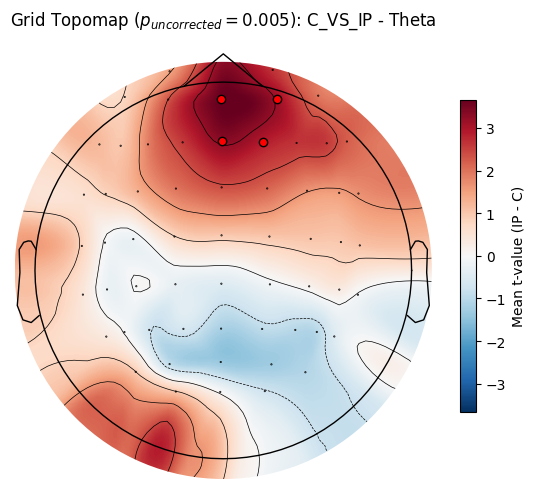


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.001, survived p_corr=0.15)


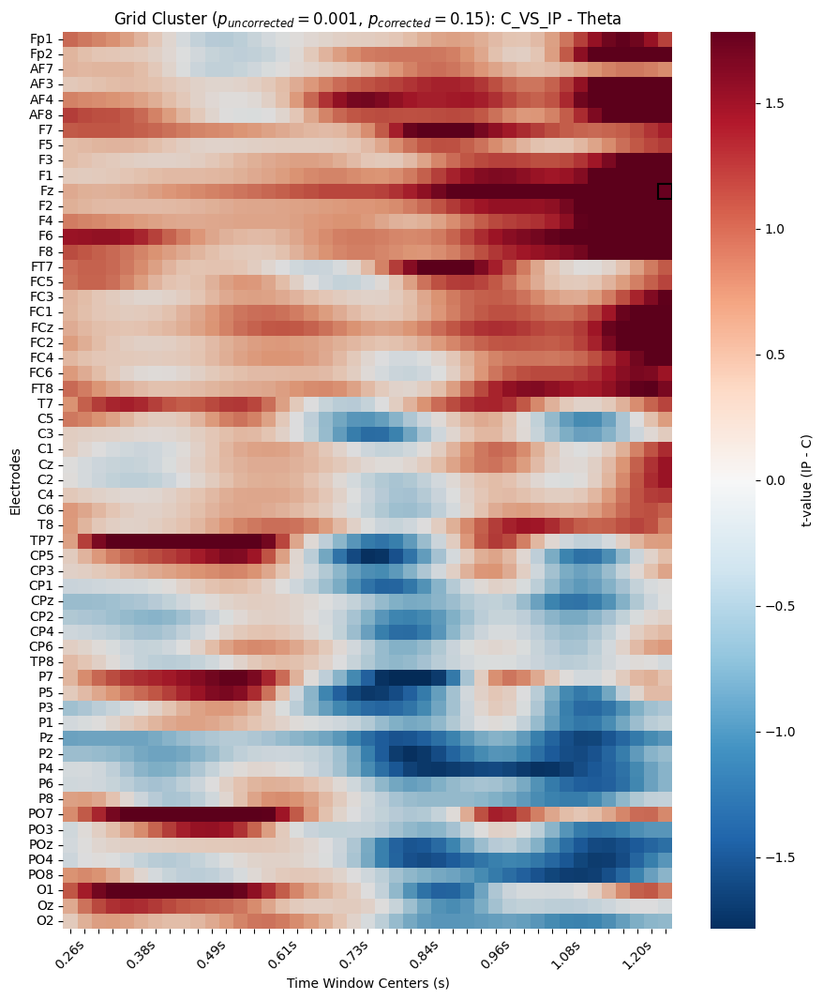

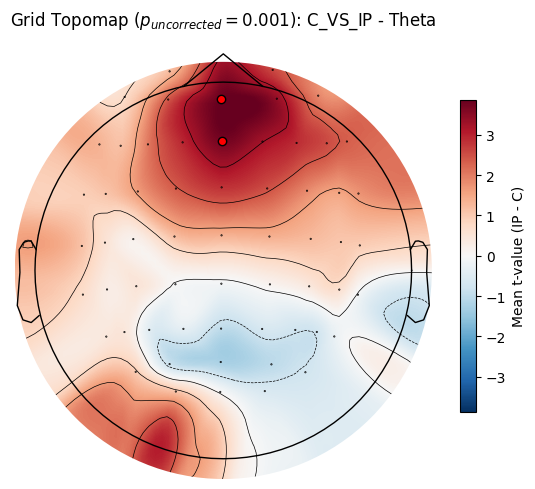


---> Plotting Unique Cluster #6 (ROI: broad, p_uncorr=0.2, survived p_corr=0.4)


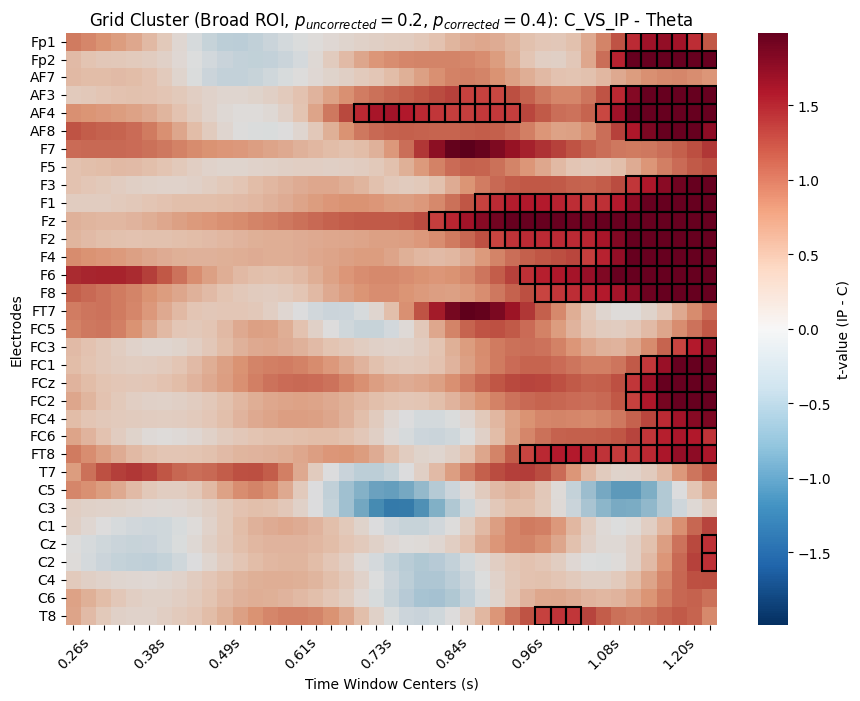

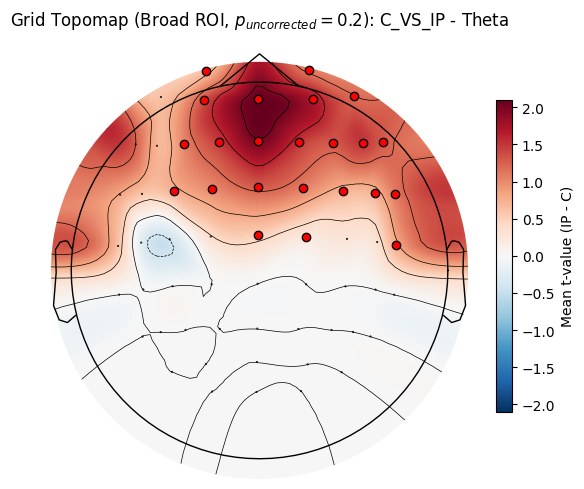


---> Plotting Unique Cluster #7 (ROI: broad, p_uncorr=0.1, survived p_corr=0.35)


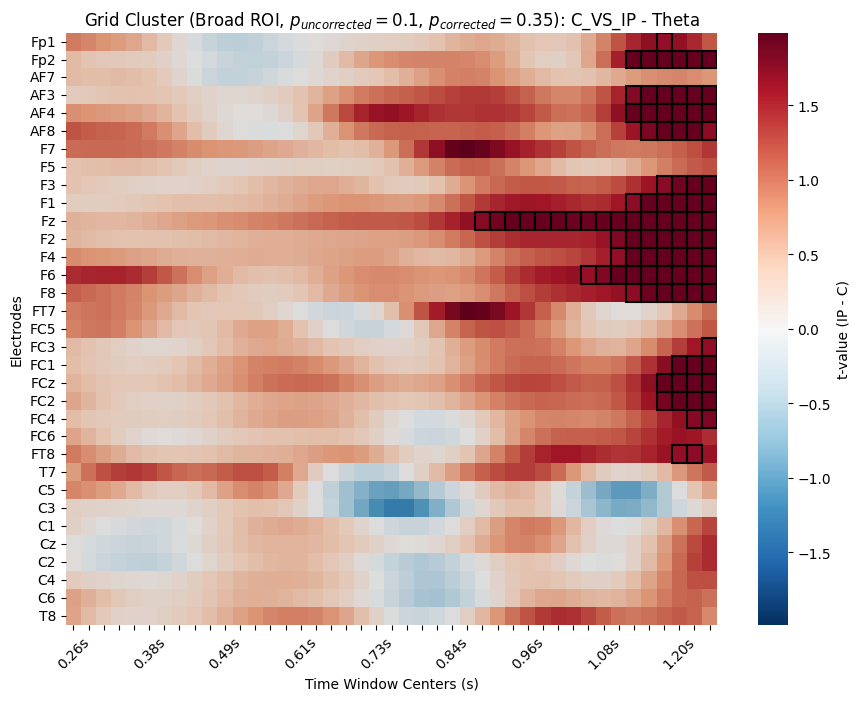

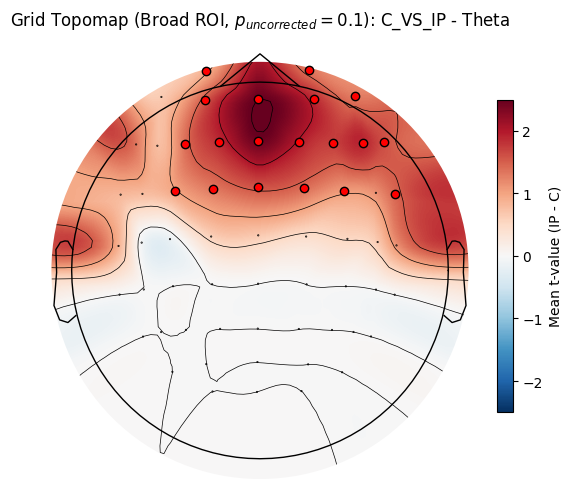


---> Plotting Unique Cluster #8 (ROI: broad, p_uncorr=0.05, survived p_corr=0.25)


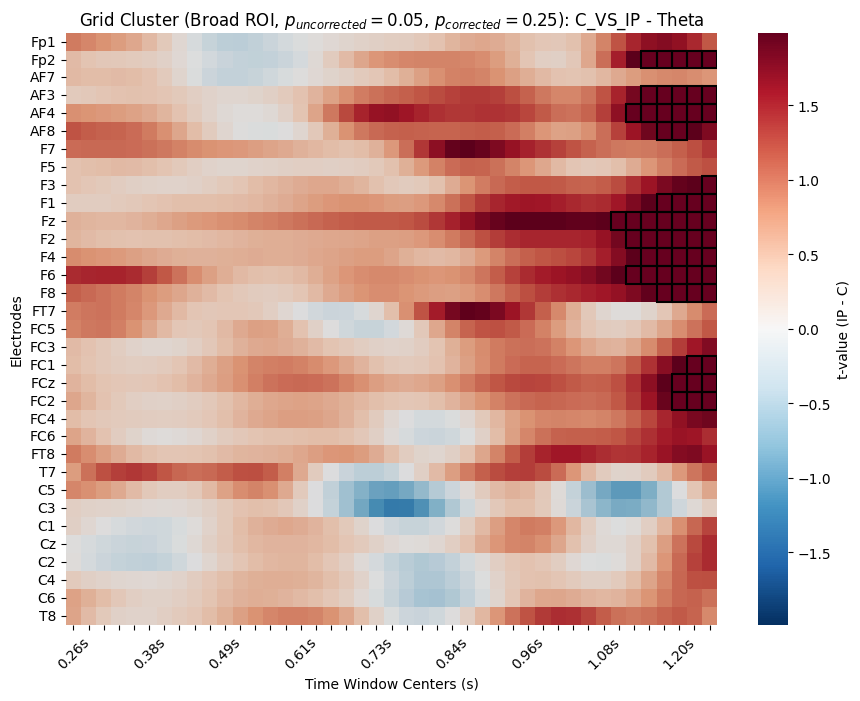

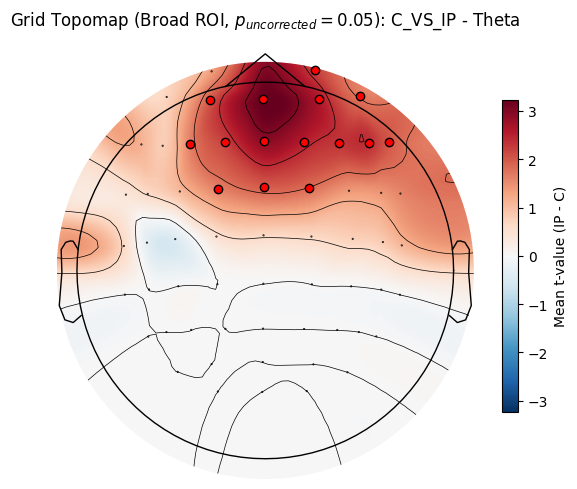


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.01, survived p_corr=0.15)


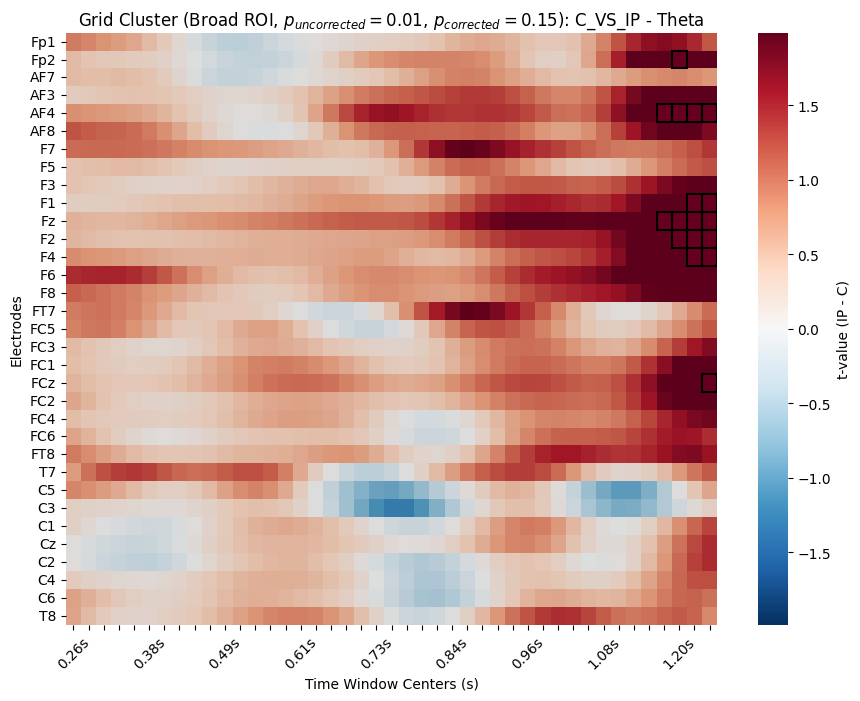

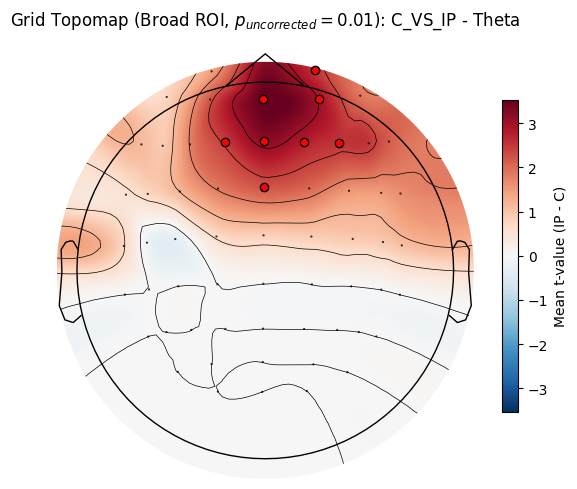


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.005, survived p_corr=0.15)


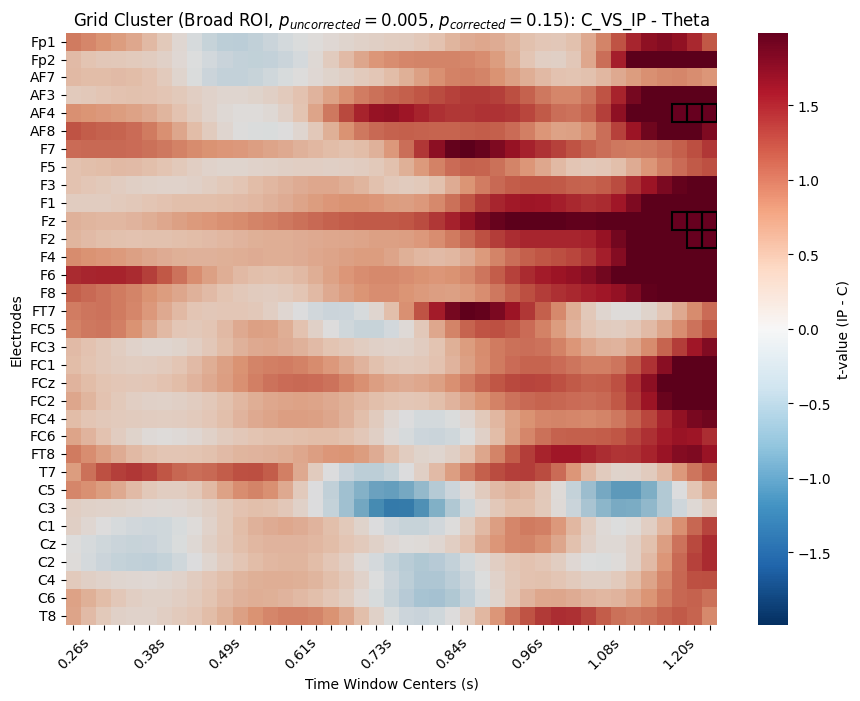

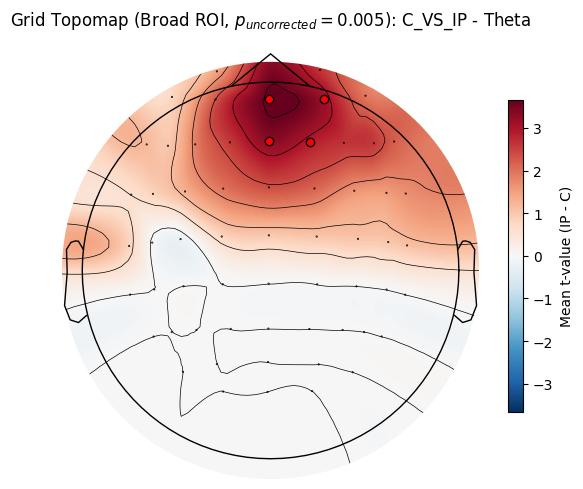


---> Plotting Unique Cluster #11 (ROI: broad, p_uncorr=0.001, survived p_corr=0.1)


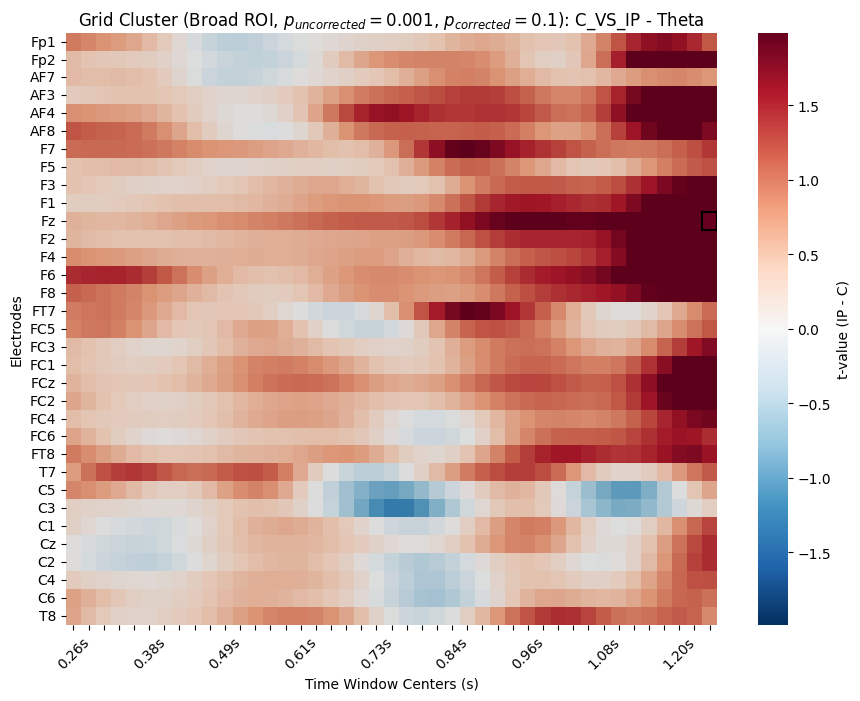

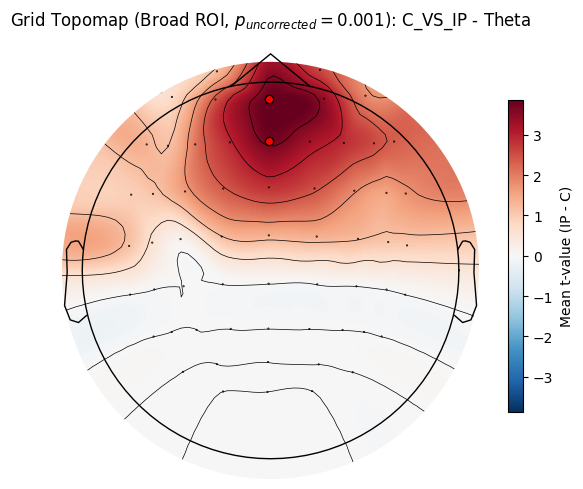


---> Plotting Unique Cluster #12 (ROI: narrow, p_uncorr=0.2, survived p_corr=0.25)


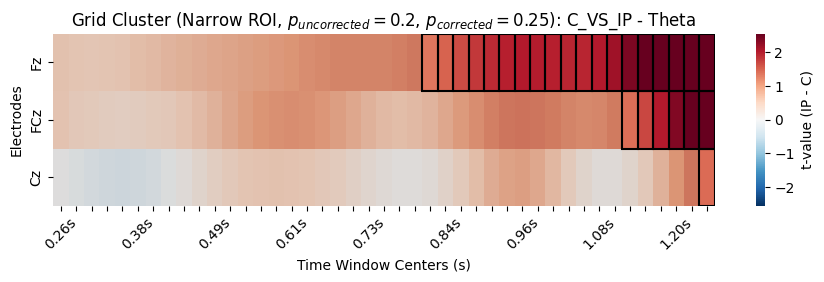

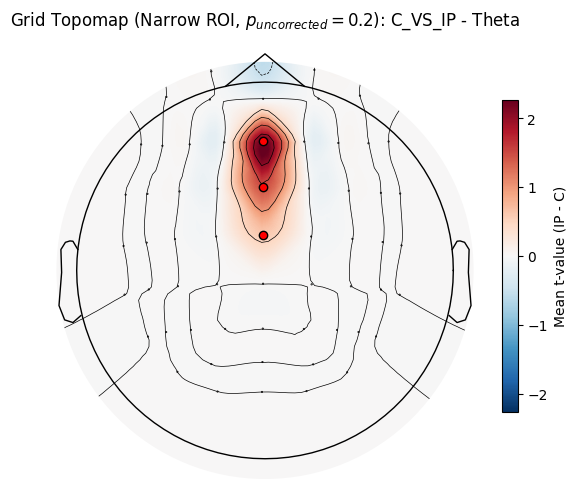


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.2)


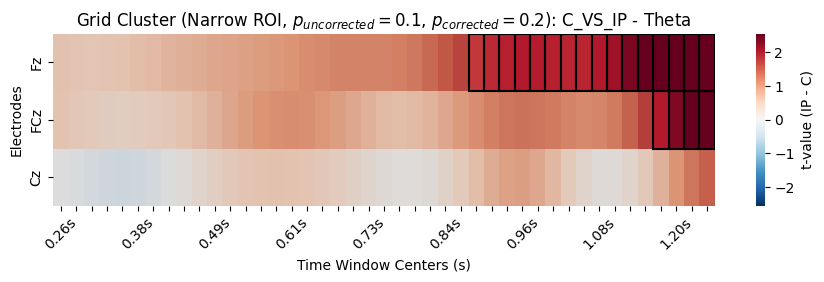

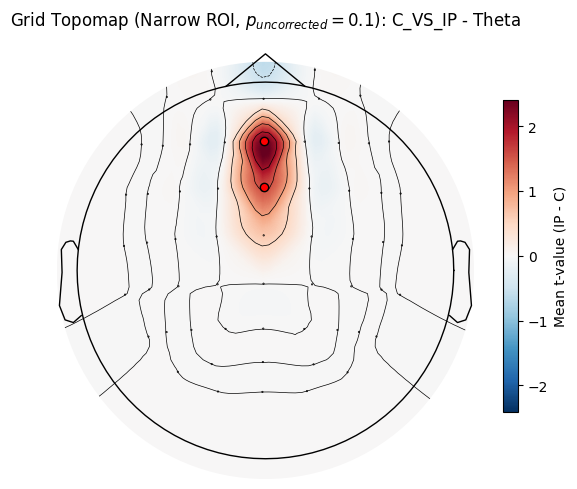


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.2)


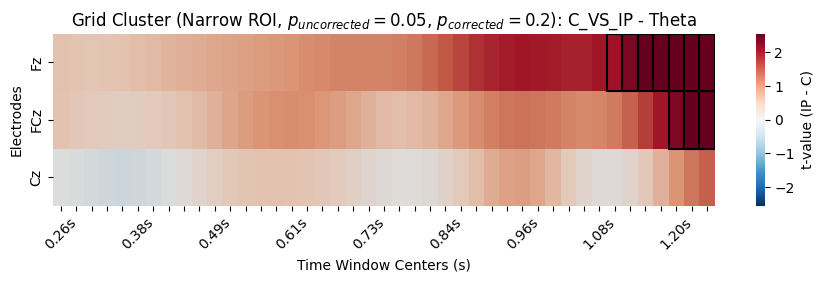

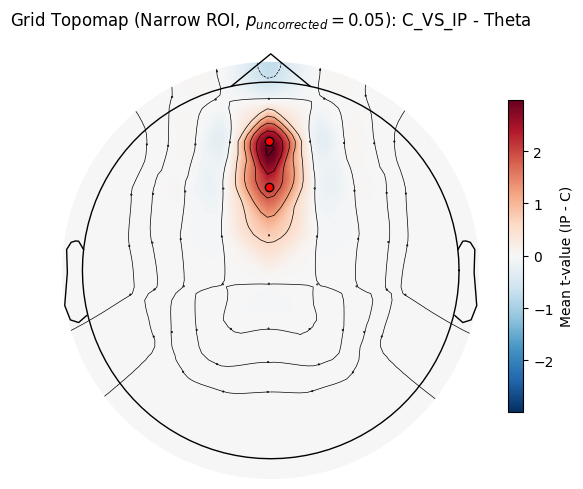


---> Plotting Unique Cluster #15 (ROI: narrow, p_uncorr=0.01, survived p_corr=0.1)


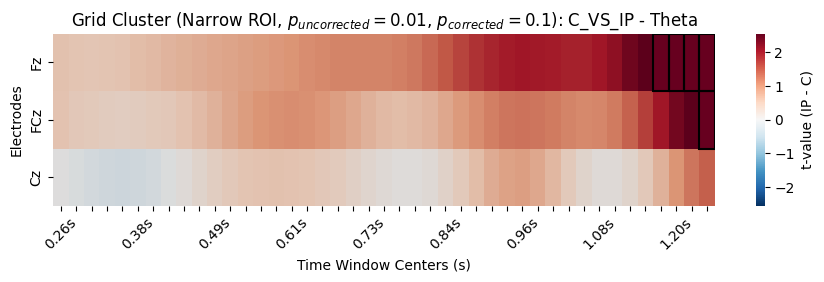

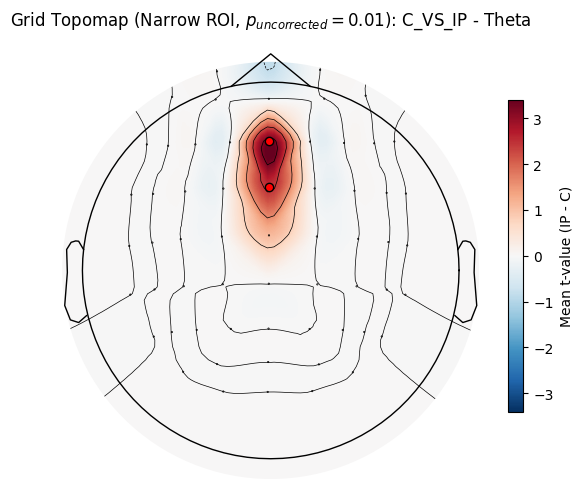


---> Plotting Unique Cluster #16 (ROI: narrow, p_uncorr=0.005, survived p_corr=0.05)


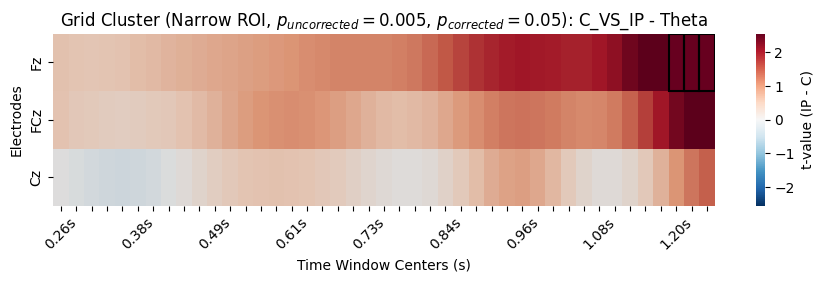

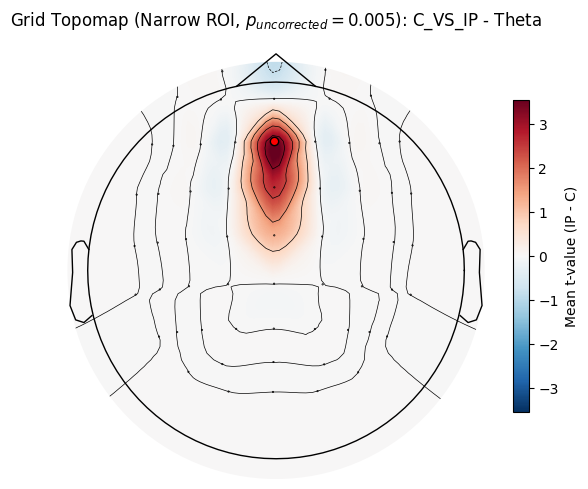


---> Plotting Unique Cluster #17 (ROI: narrow, p_uncorr=0.001, survived p_corr=0.05)


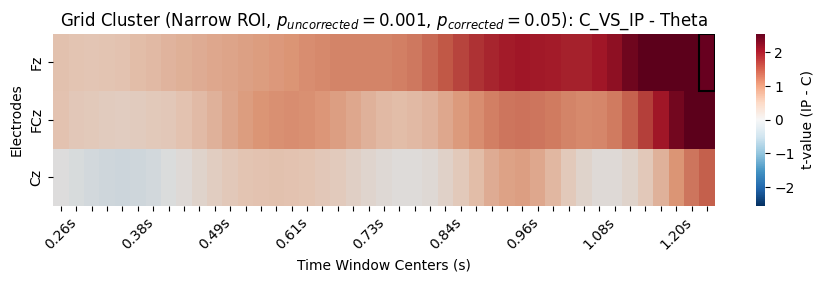

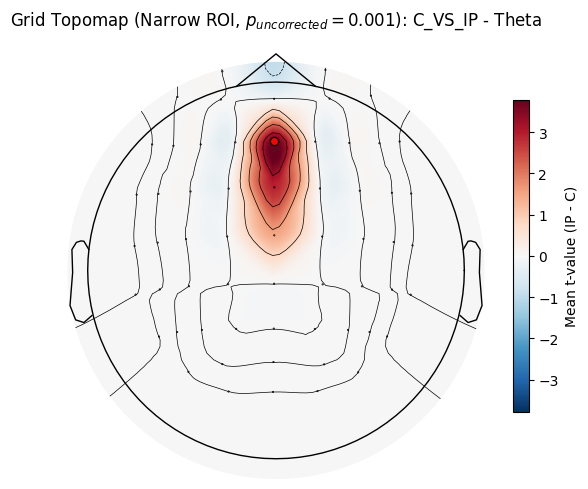


Plotting C vs IP Alpha significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.2, survived p_corr=0.005)


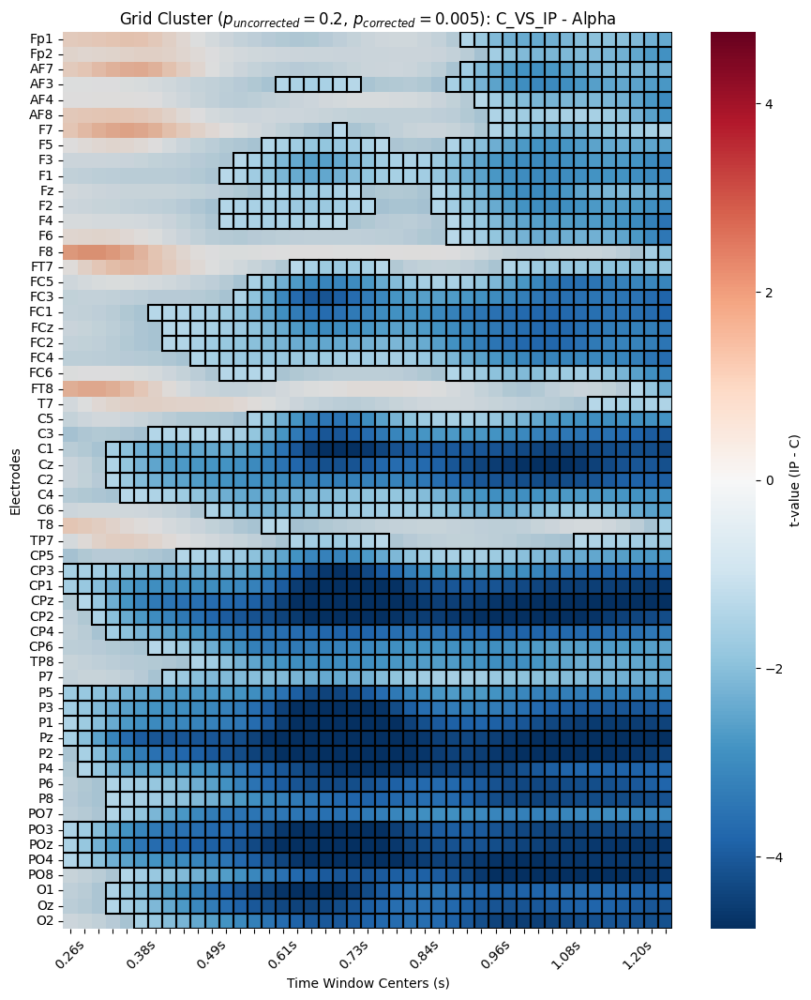

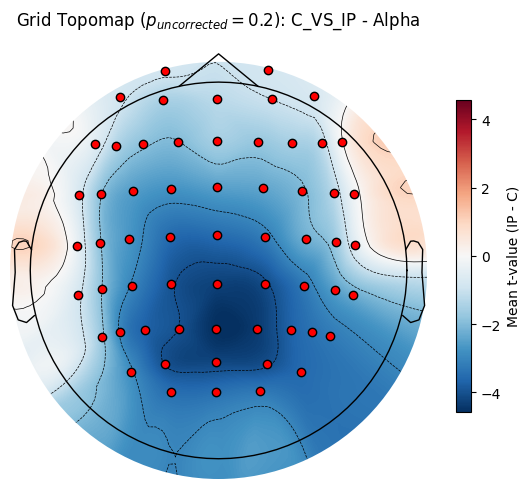


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.1, survived p_corr=0.005)


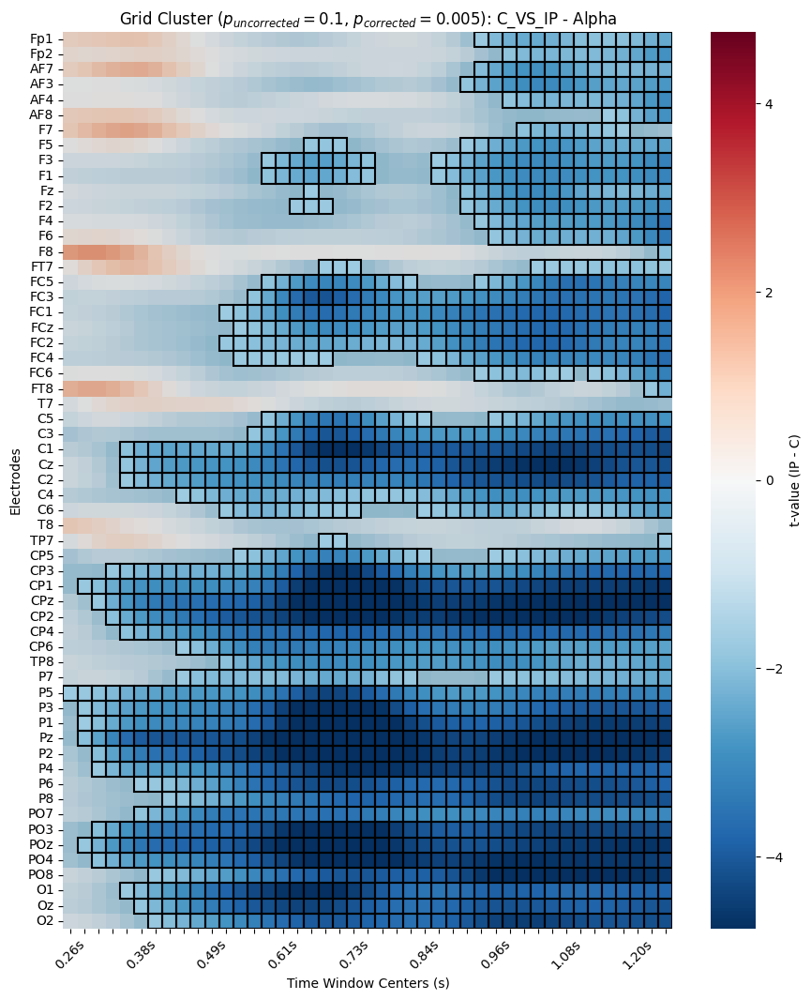

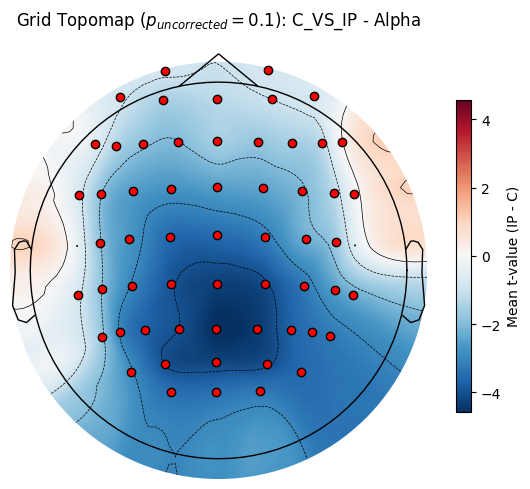


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.05, survived p_corr=0.001)


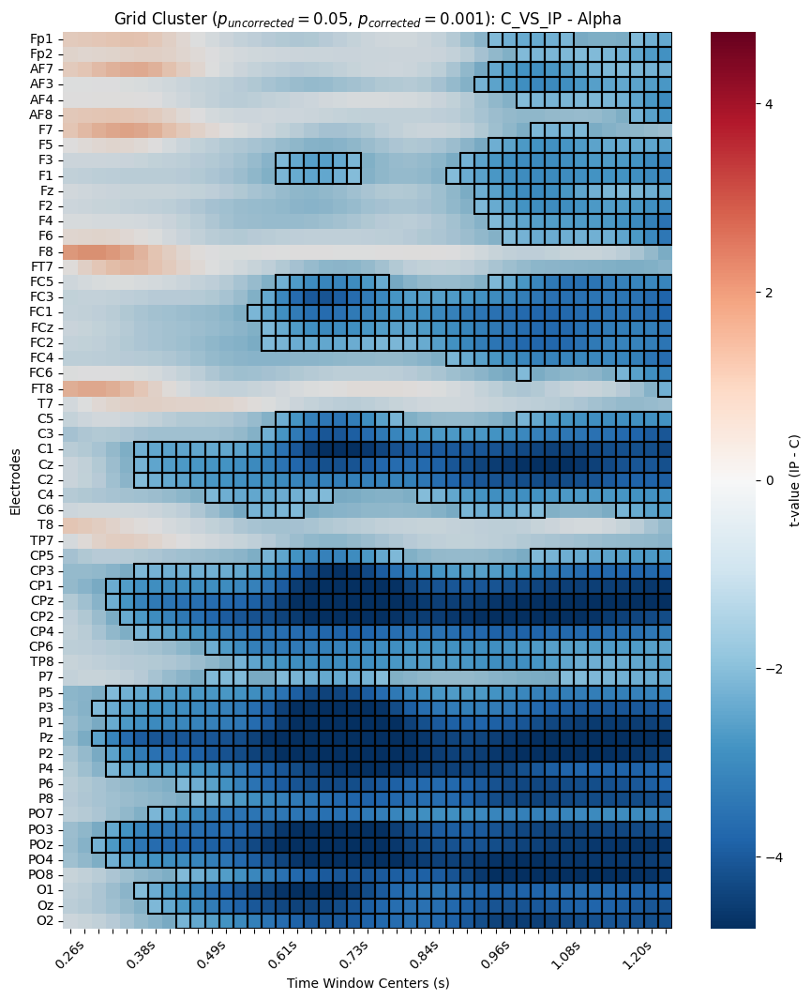

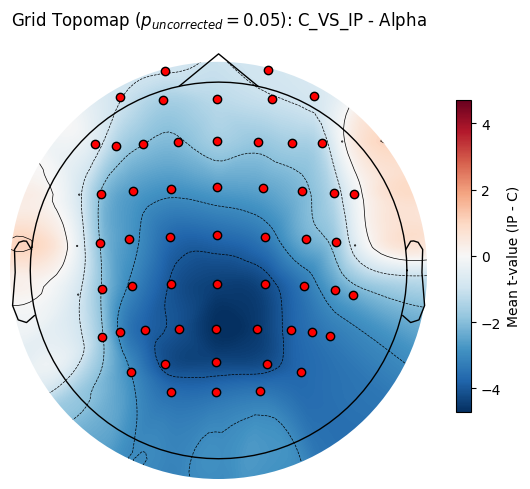


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.01, survived p_corr=0.001)


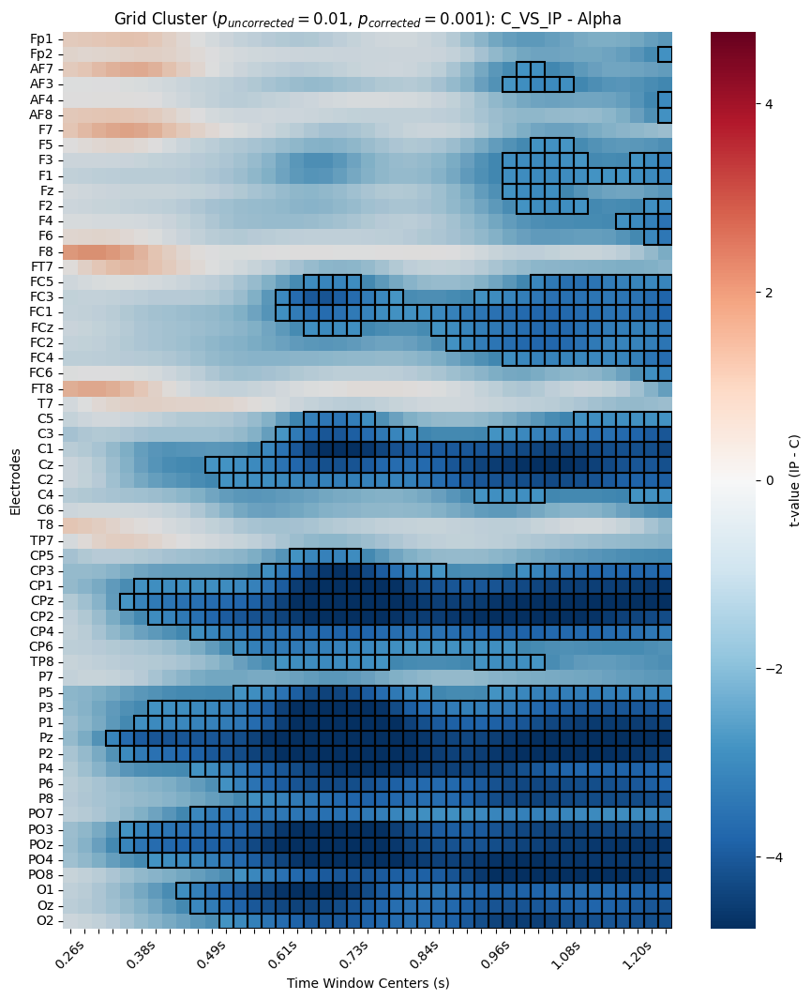

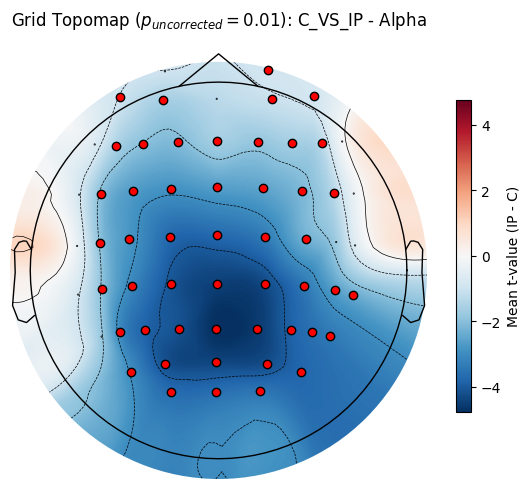


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.005, survived p_corr=0.001)


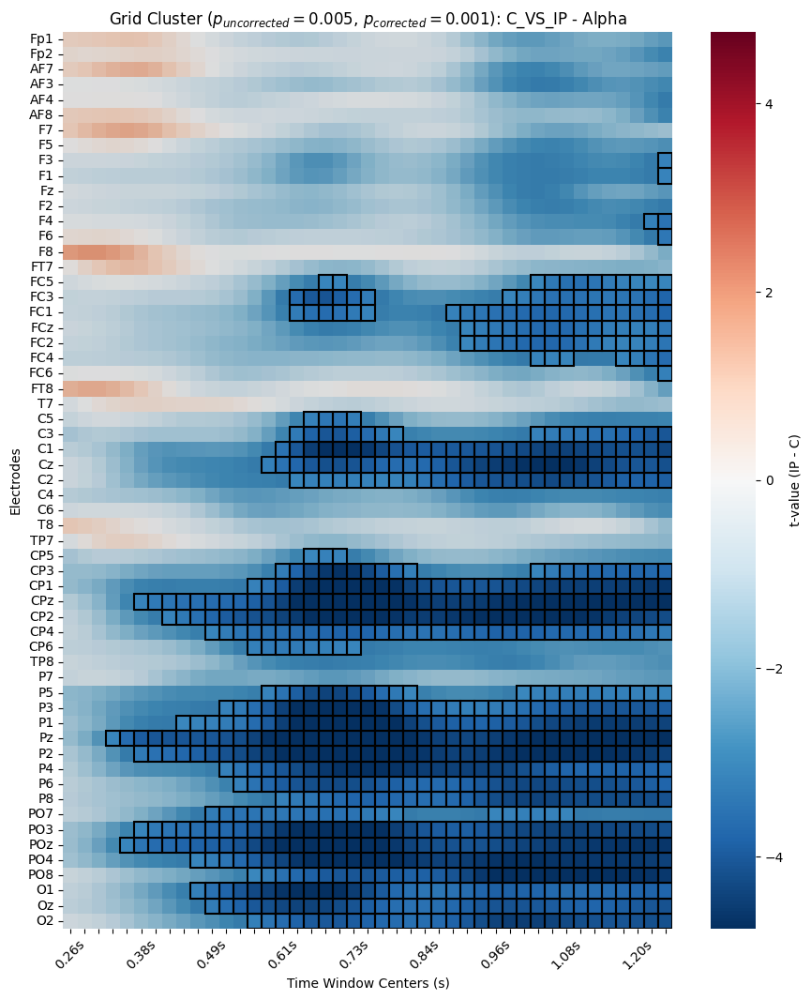

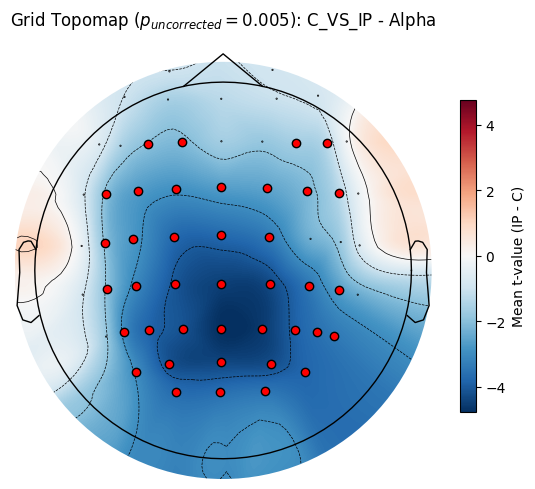


---> Plotting Unique Cluster #6 (ROI: none, p_uncorr=0.001, survived p_corr=0.001)


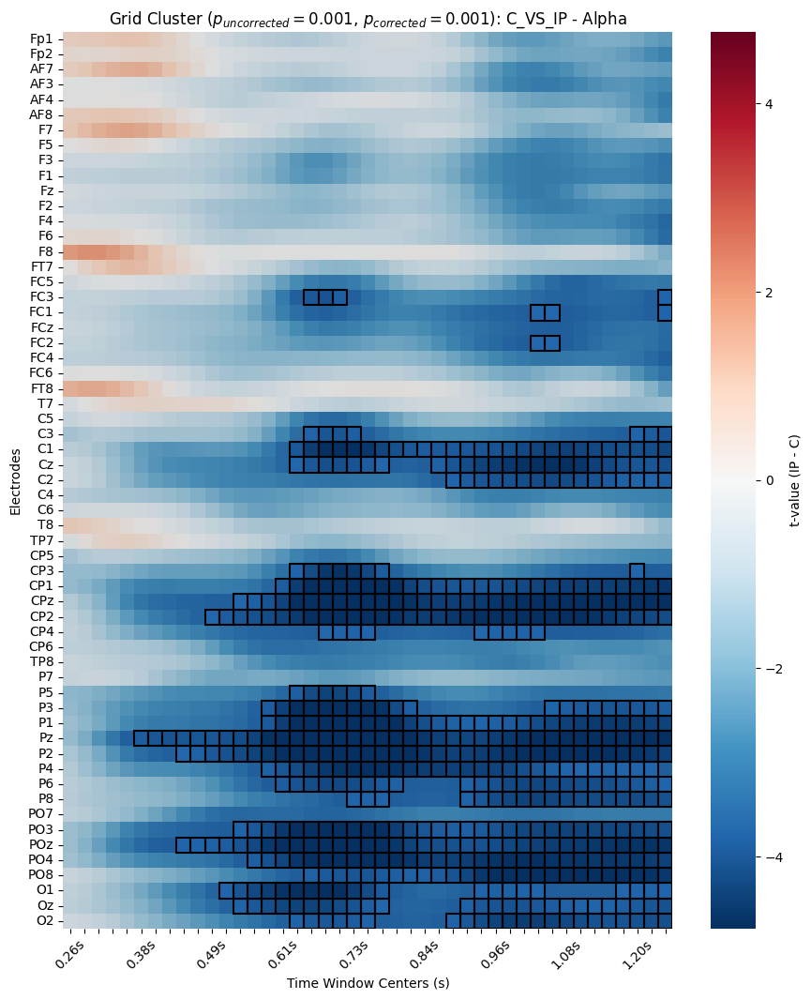

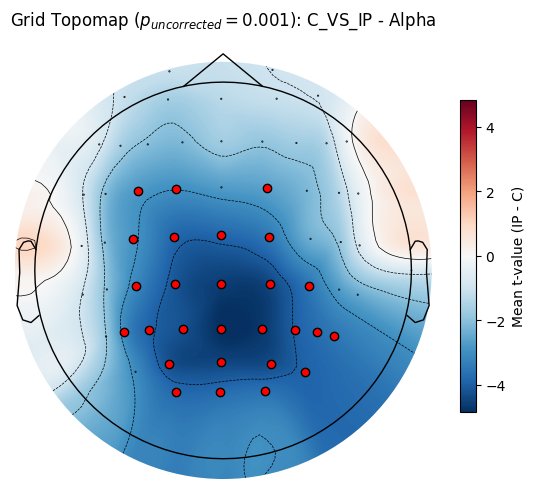


---> Plotting Unique Cluster #7 (ROI: none, p_uncorr=0.0001, survived p_corr=0.001)


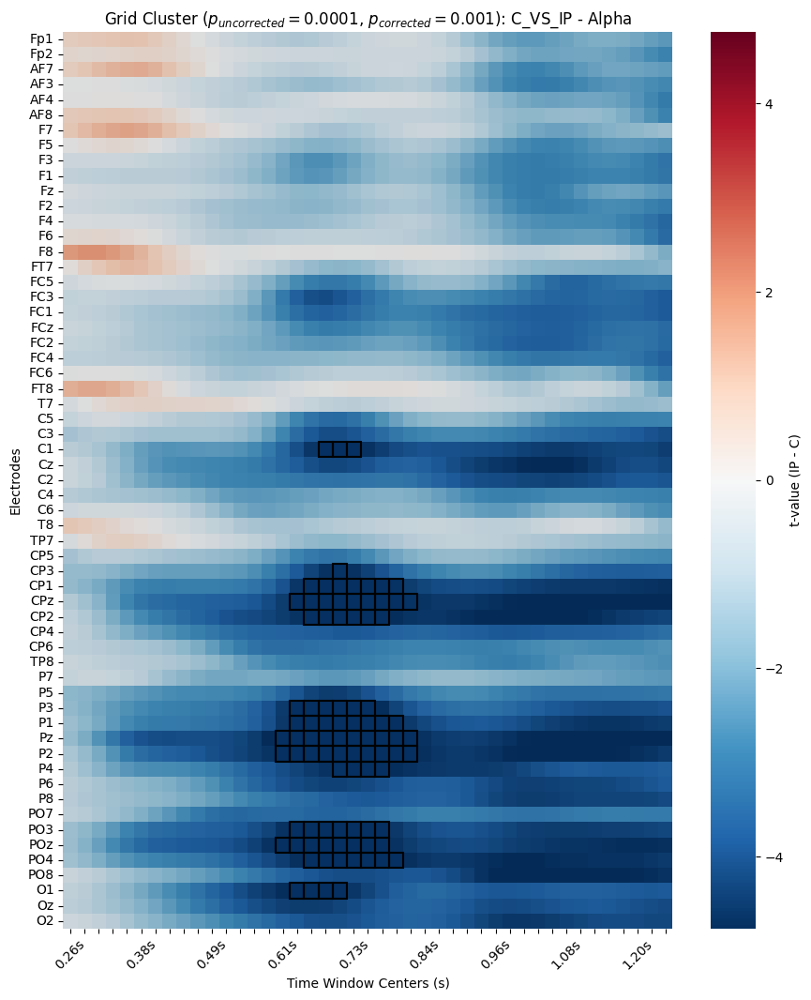

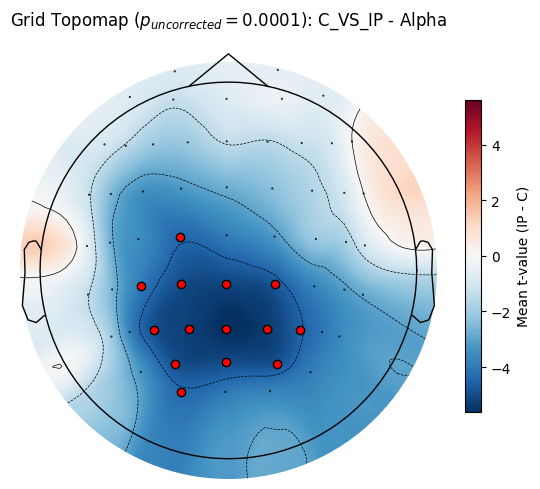


---> Plotting Unique Cluster #8 (ROI: none, p_uncorr=0.0001, survived p_corr=0.005)


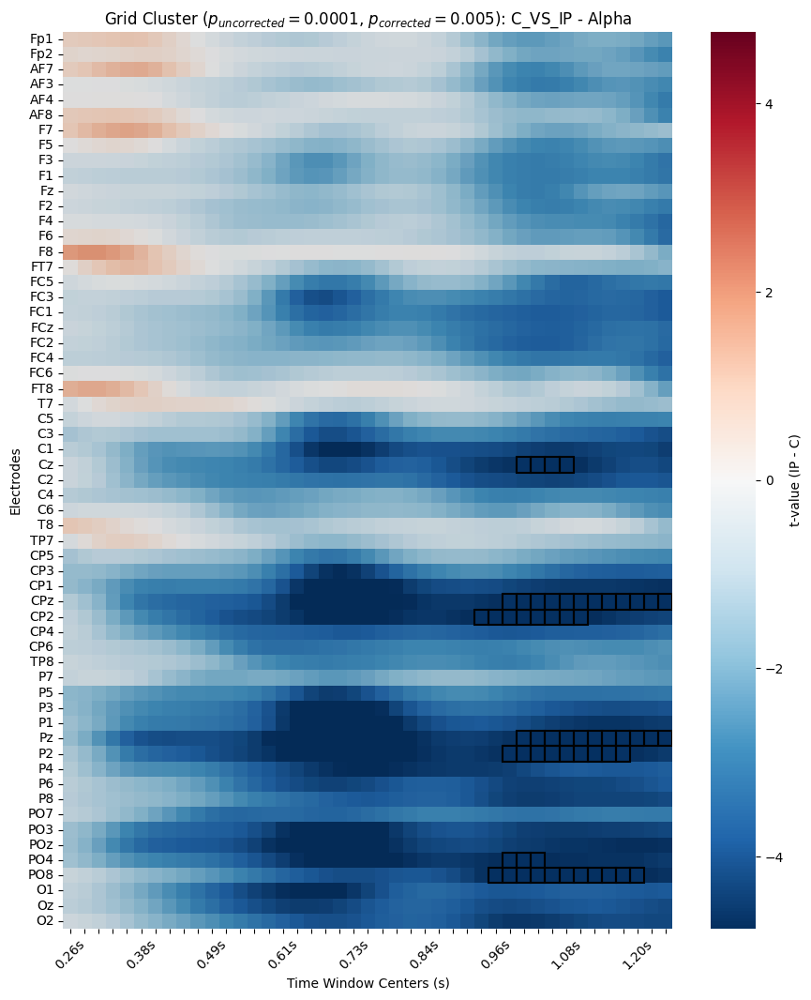

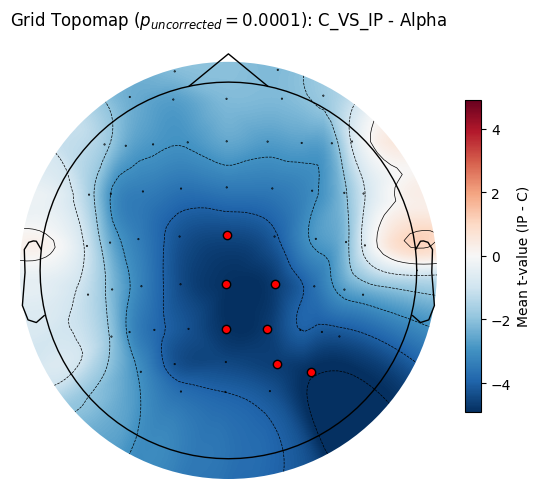

In [17]:
print("\nPlotting C vs IP Theta significant clusters:")
plot_all_significant_unique_clusters(c_theta_res, c_theta_cache, "c_vs_ip", "theta", paths)

print("\nPlotting C vs IP Alpha significant clusters:")
plot_all_significant_unique_clusters(c_alpha_res, c_alpha_cache, "c_vs_ip", "alpha", paths)

## 2. IM vs IP Grid Search & Visualizations (Exploration across Bands & Baselines)

Due to the subtle proactive control nature of IM vs IP, the differences are smaller and often diluted. Here we expand the search to:
- **Bands**: Theta (5-7 Hz) and Alpha (8-12 Hz)
- **Baseline configurations**: Standard dB trial-level baseline vs. No baseline (which highlights sustained block-wide proactive control offsets)
- **ROI Modes**: none, broad, narrow

In [18]:
print("1. Running IM vs IP Theta Grid Search...")
im_theta_res, im_theta_cache = run_grid_search_multi_roi(
    "im_vs_ip",
    "theta",
    (5.0, 7.0),
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.50, 0.25, 0.20, 0.10, 0.05, 0.01, 0.005, 0.001],
    n_permutations=10000,
)

print("2. Running IM vs IP Alpha Grid Search...")
im_alpha_res, im_alpha_cache = run_grid_search_multi_roi(
    "im_vs_ip",
    "alpha",
    (8.0, 12.0),
    paths,
    roi_modes=["none", "broad", "narrow"],
    p_uncorrected=[0.50, 0.25, 0.20, 0.10, 0.05, 0.01, 0.005, 0.001],
    n_permutations=10000,
)

1. Running IM vs IP Theta Grid Search...
[IM_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_im_vs_ip_sfreq128.joblib...

GRID SEARCH FOR: IM_VS_IP - THETA (NONE ROI, dB baseline)

Running permutation test for p_uncorrected = 0.500 (t_crit = 0.683)...
  -> p_corrected = 0.001: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.005: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.010: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.050: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.100: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.150: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.200: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.250: Found 0 significant clusters (out of 7 candidates)
  -> p_corrected = 0.300: Found 0 significant clusters (out o


Plotting IM vs IP Theta significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


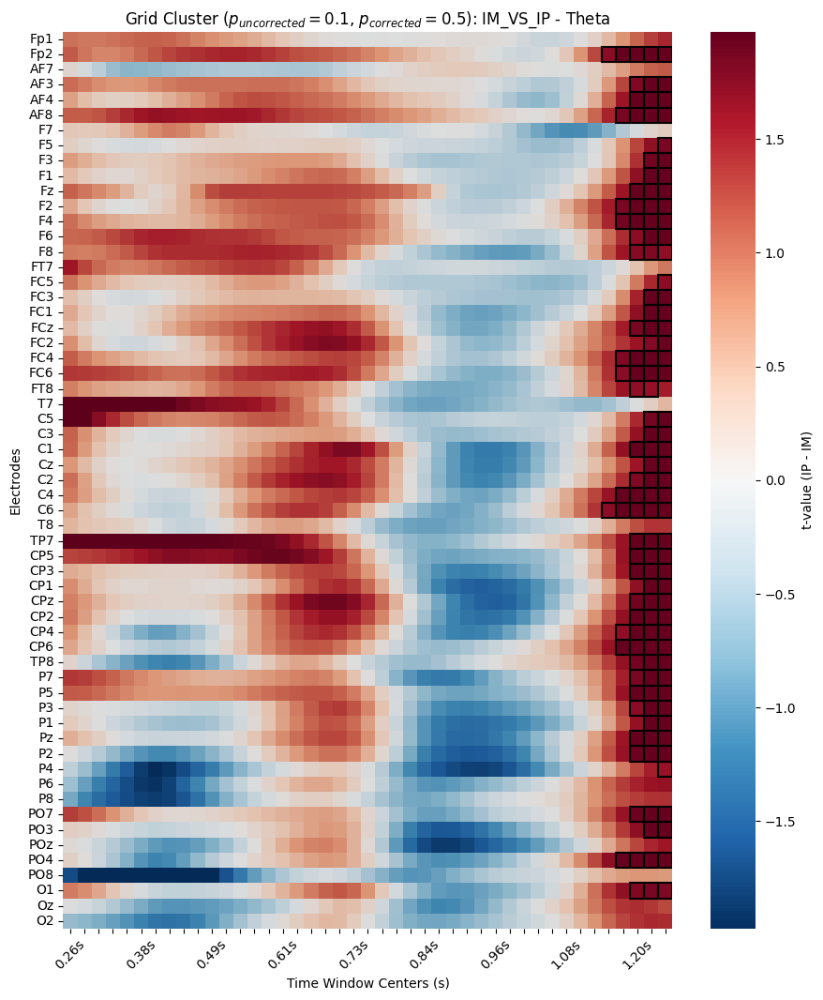

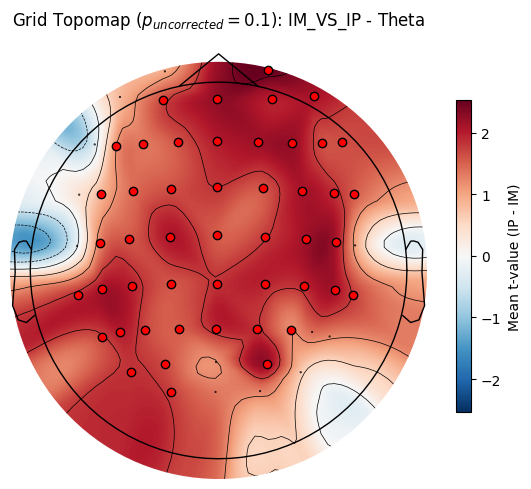


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.05, survived p_corr=0.3)


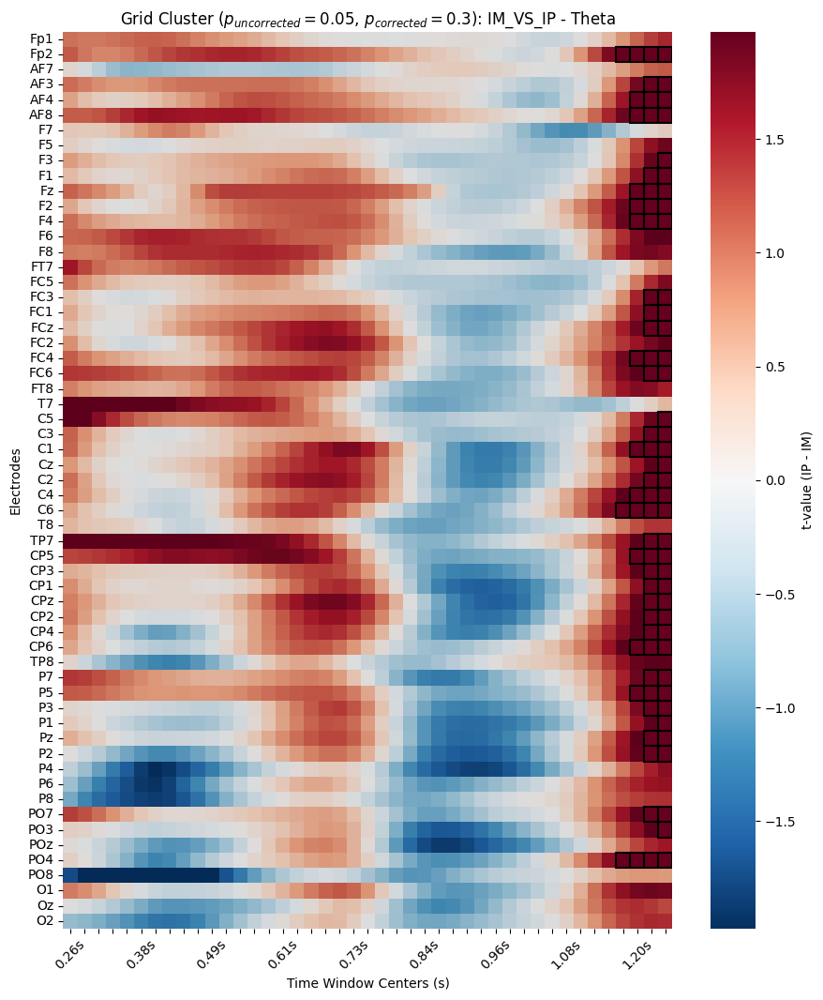

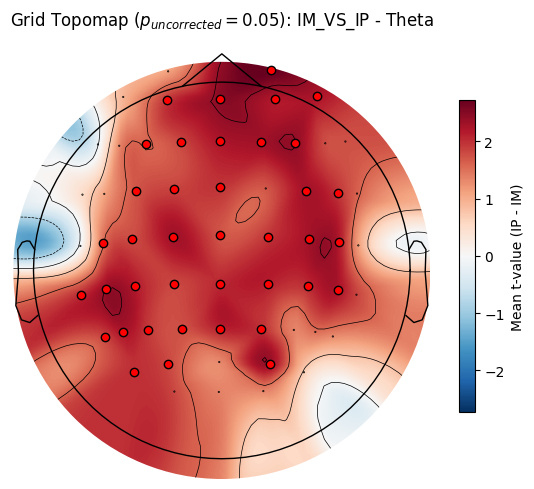


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.01, survived p_corr=0.5)


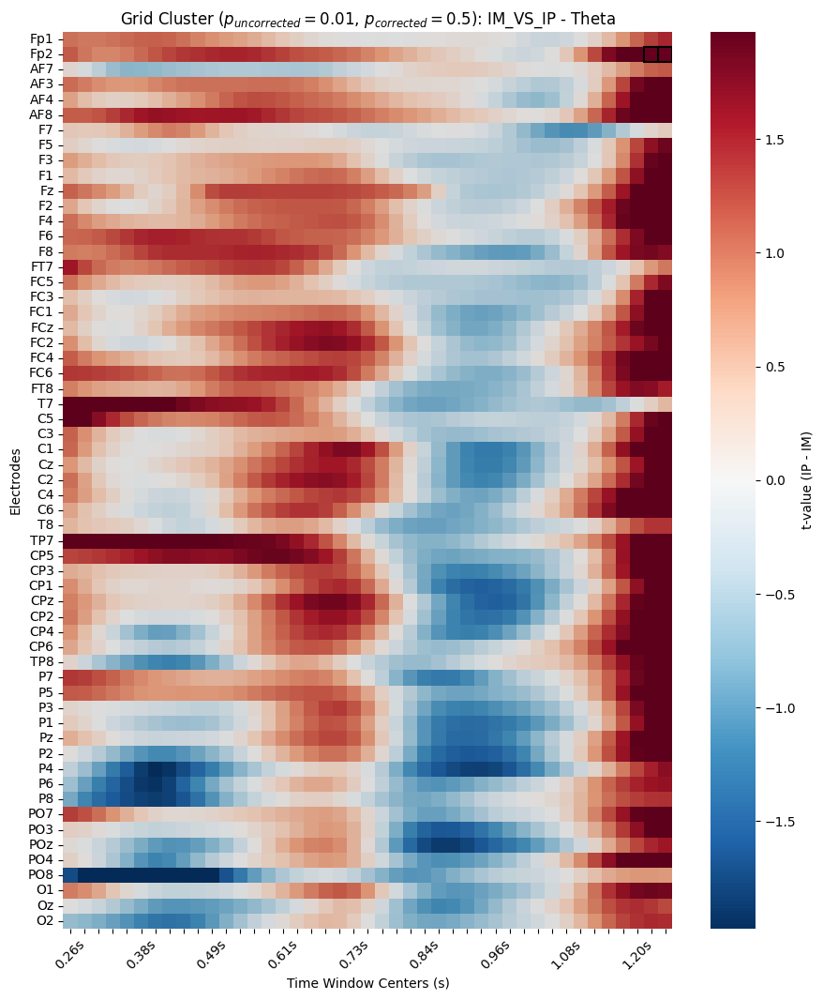

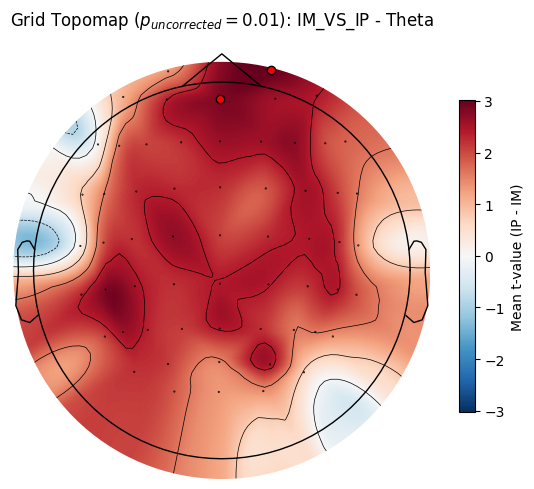


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.005, survived p_corr=0.5)


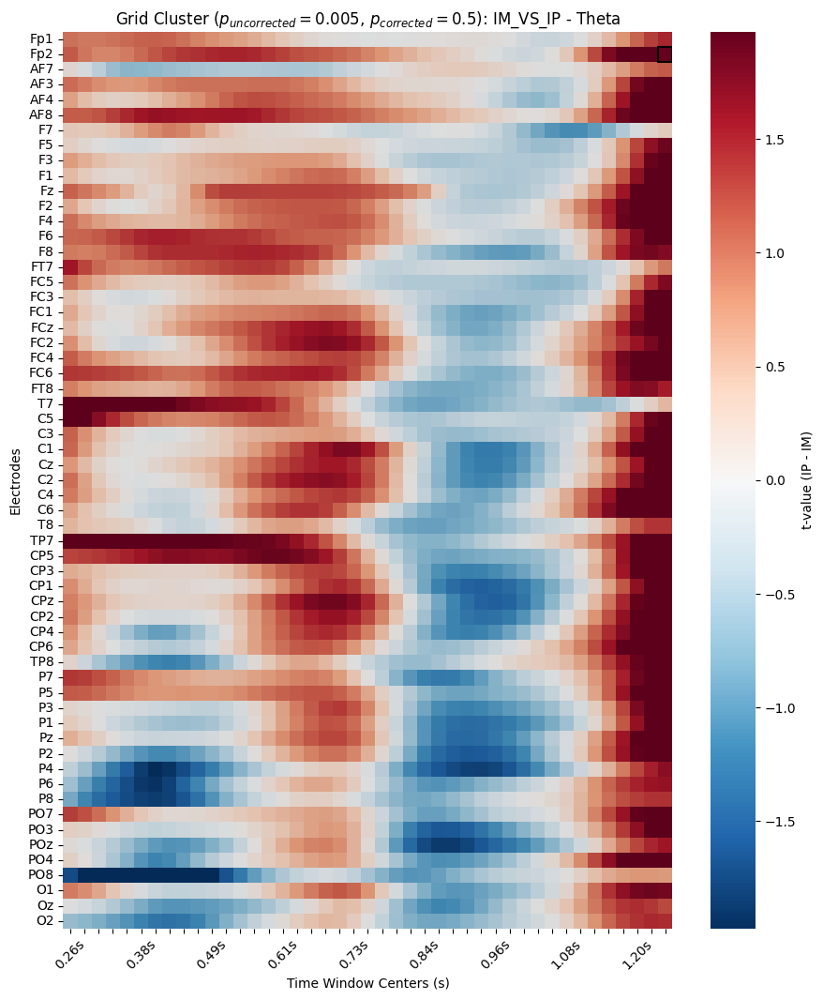

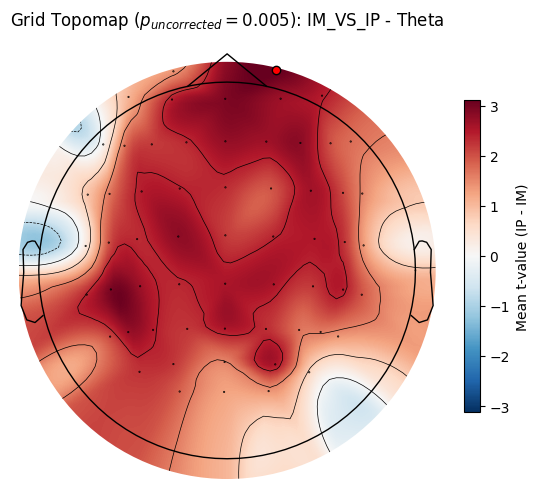


---> Plotting Unique Cluster #5 (ROI: broad, p_uncorr=0.1, survived p_corr=0.4)


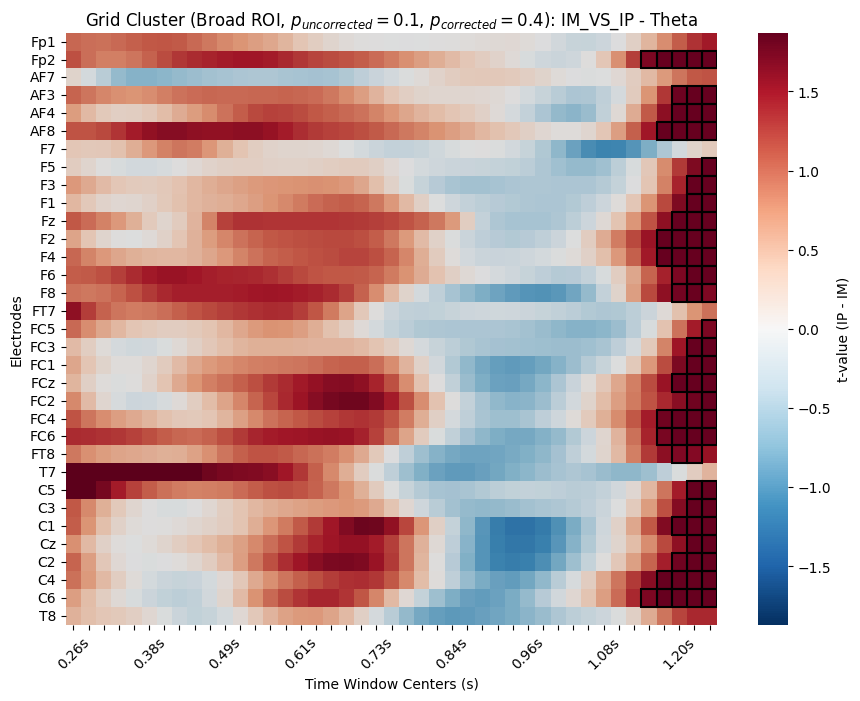

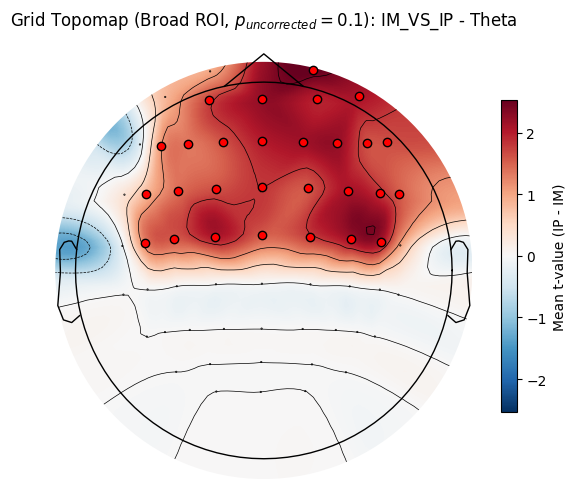


---> Plotting Unique Cluster #6 (ROI: broad, p_uncorr=0.05, survived p_corr=0.3)


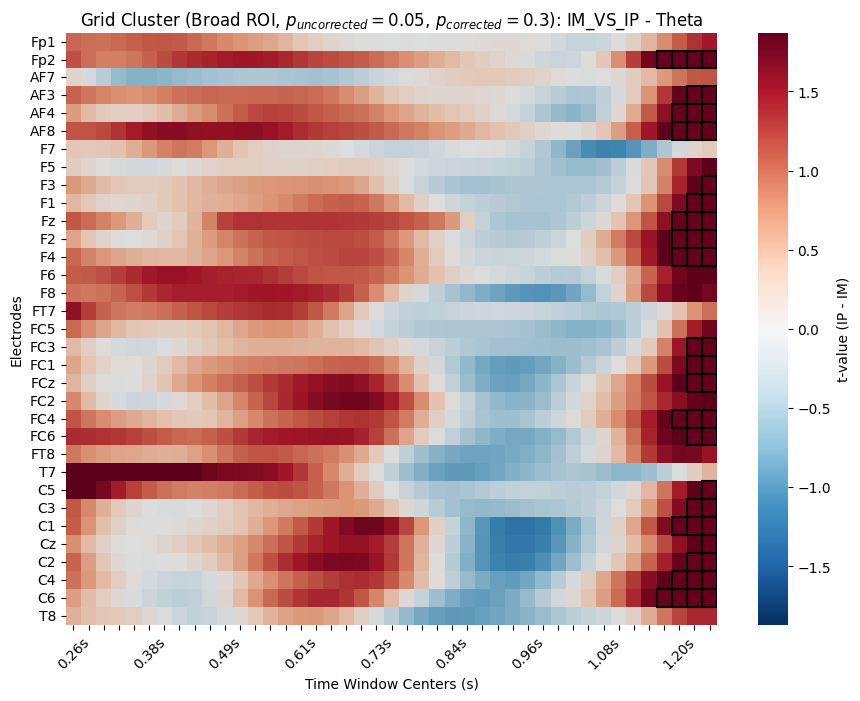

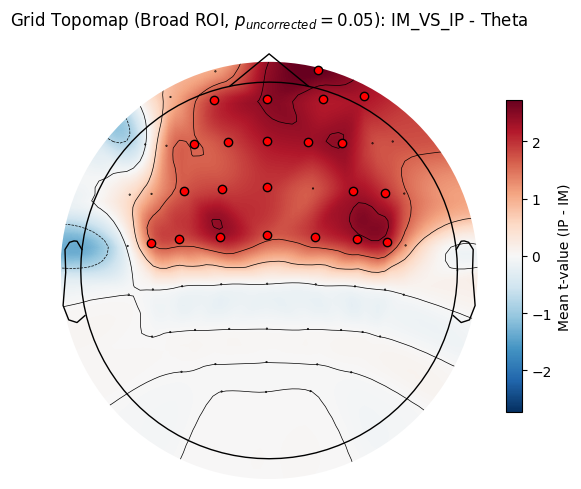


---> Plotting Unique Cluster #7 (ROI: broad, p_uncorr=0.01, survived p_corr=0.4)


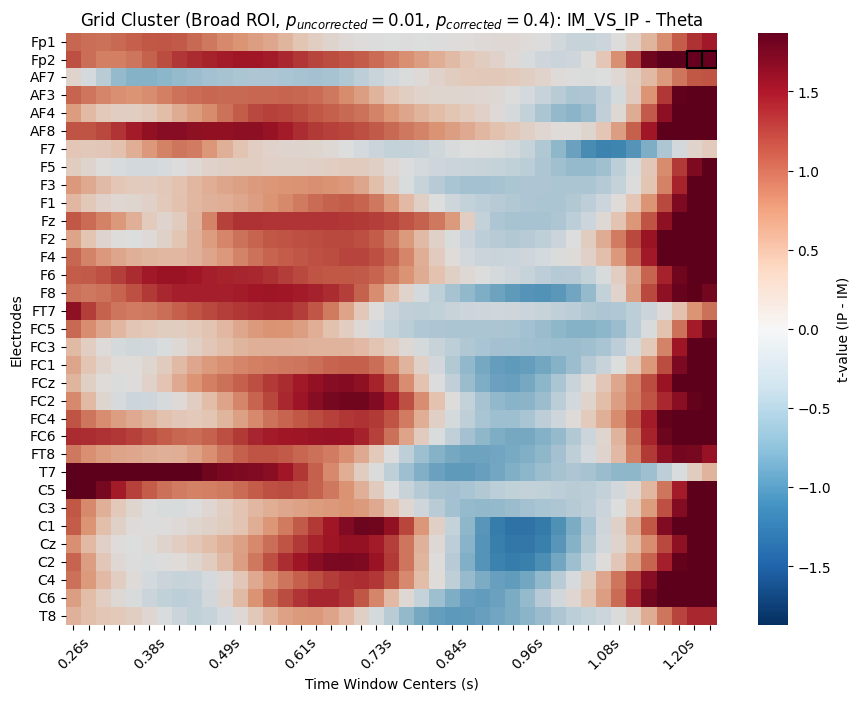

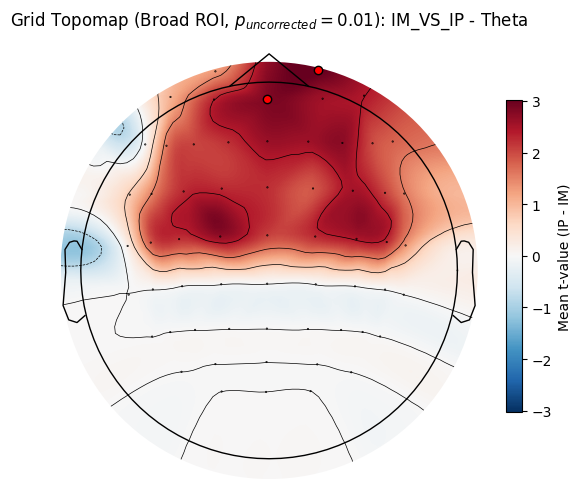


---> Plotting Unique Cluster #8 (ROI: broad, p_uncorr=0.01, survived p_corr=0.5)


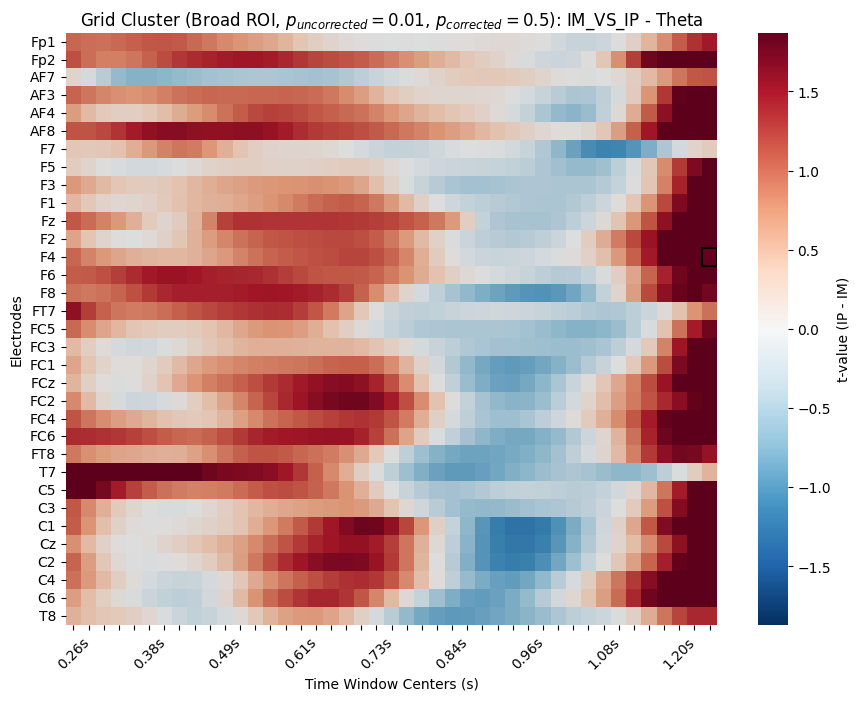

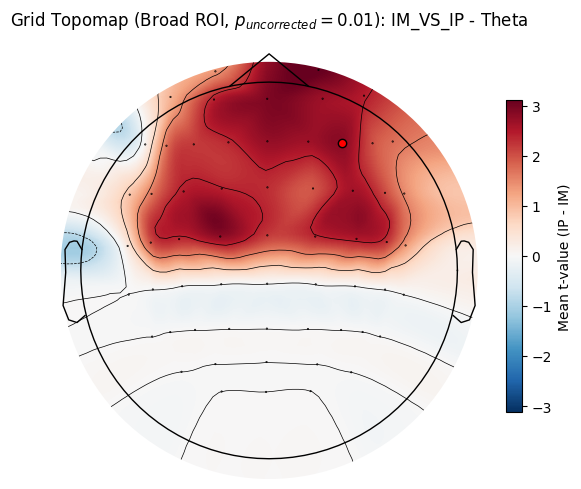


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.01, survived p_corr=0.5)


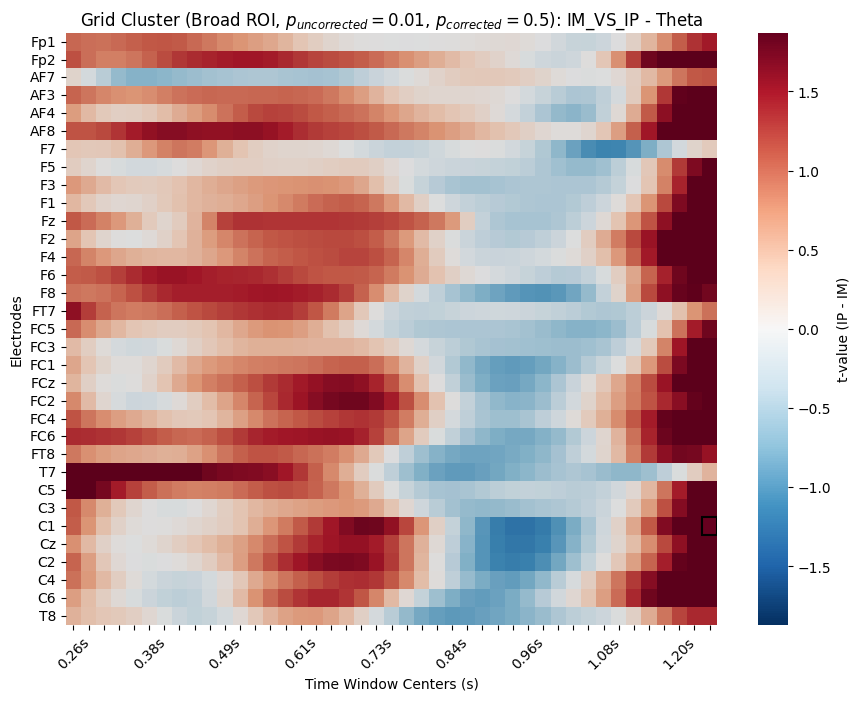

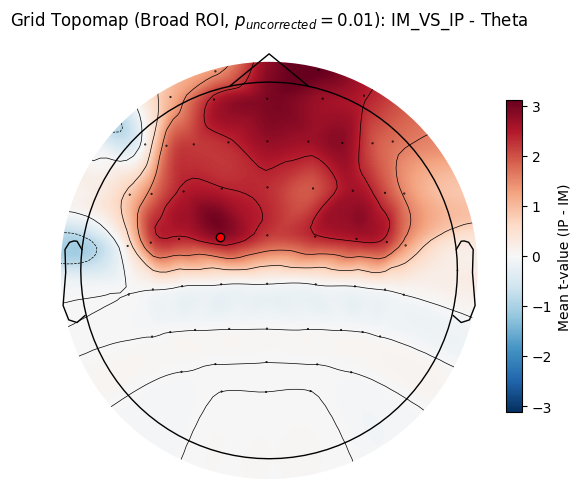


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.005, survived p_corr=0.3)


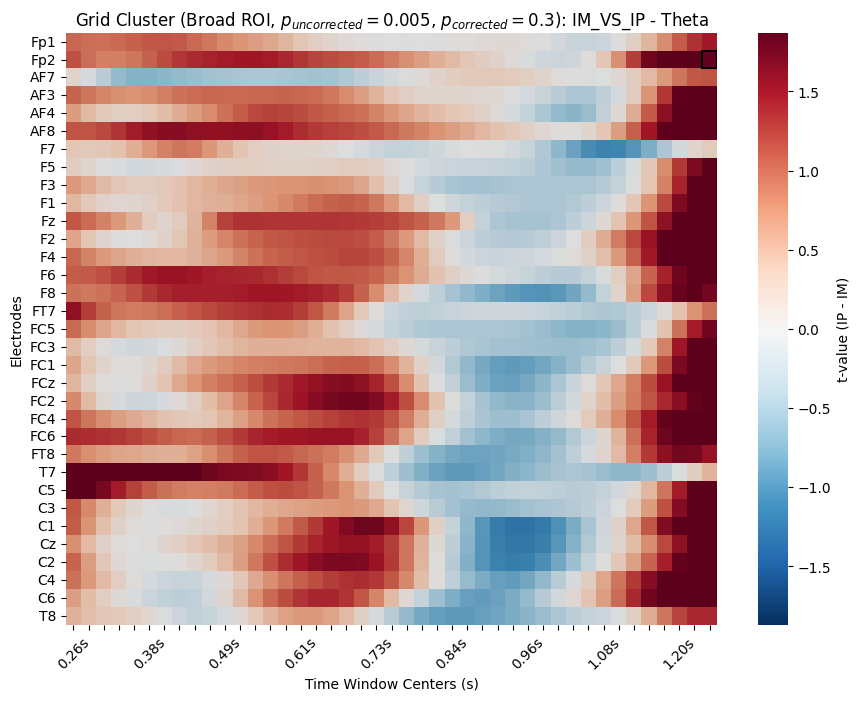

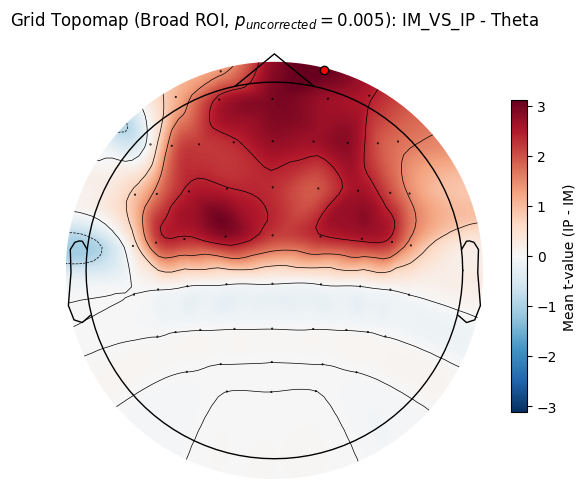


---> Plotting Unique Cluster #11 (ROI: narrow, p_uncorr=0.5, survived p_corr=0.5)


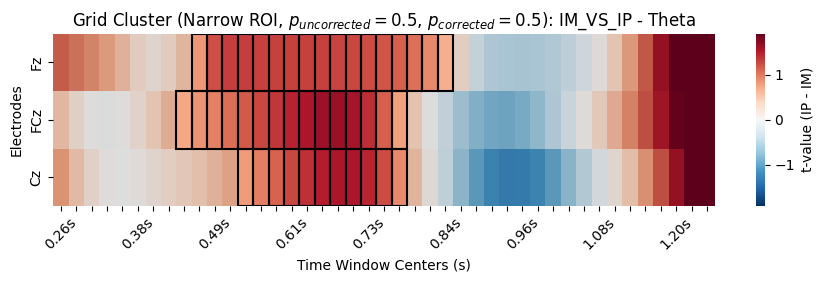

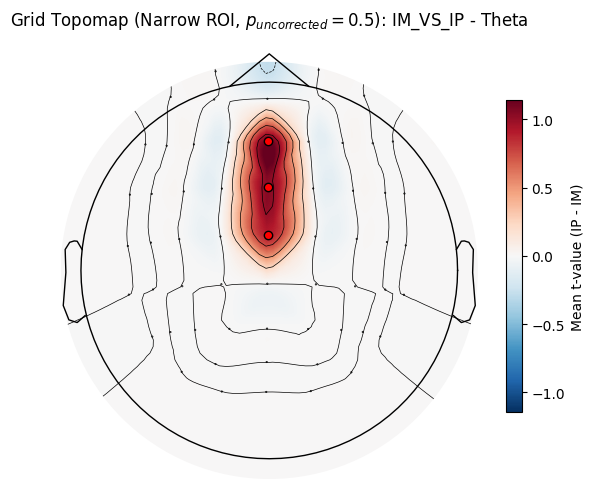


---> Plotting Unique Cluster #12 (ROI: narrow, p_uncorr=0.25, survived p_corr=0.5)


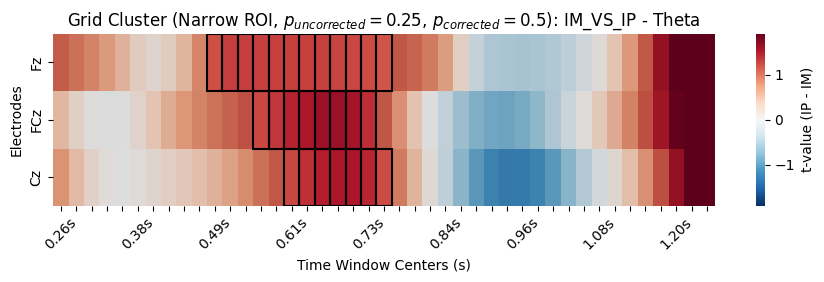

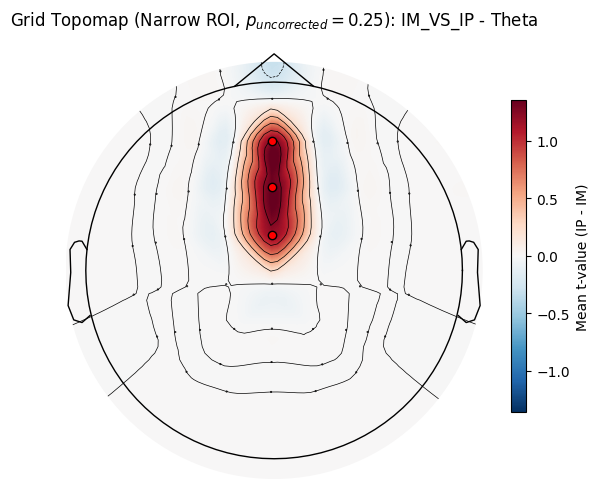


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.4)


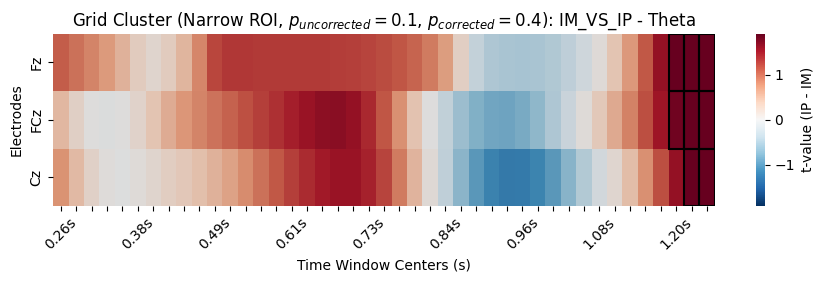

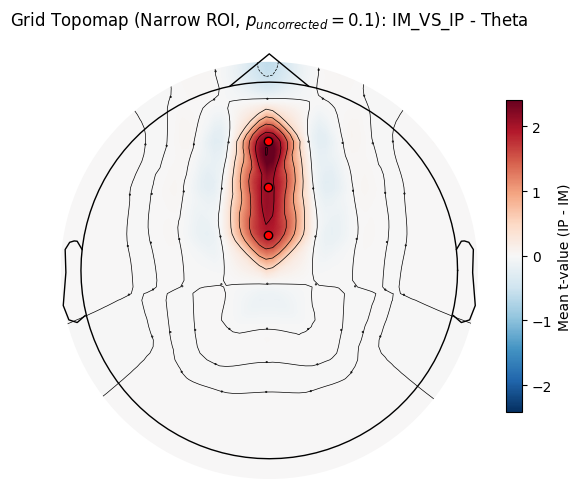


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.25)


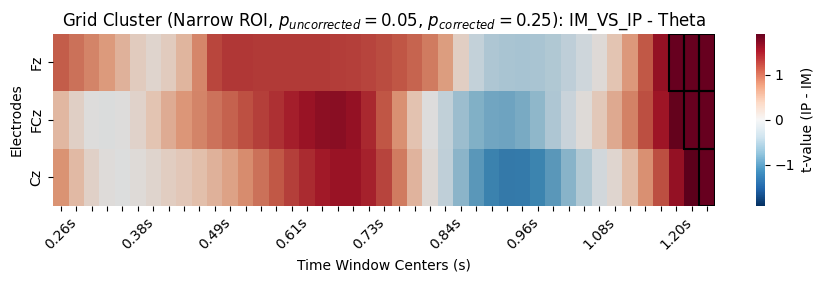

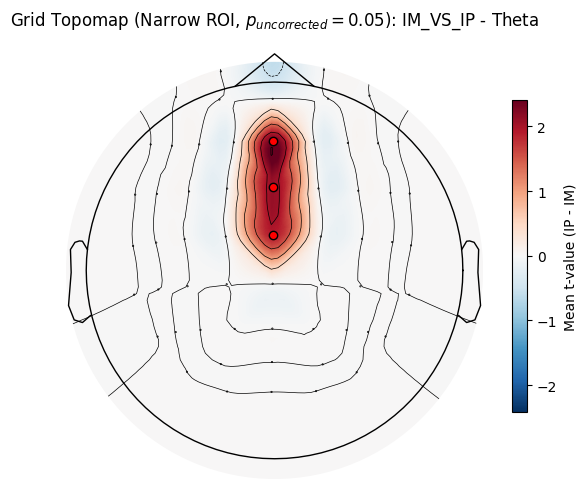


Plotting IM vs IP Alpha significant clusters:

---> Plotting Unique Cluster #1 (ROI: none, p_uncorr=0.25, survived p_corr=0.5)


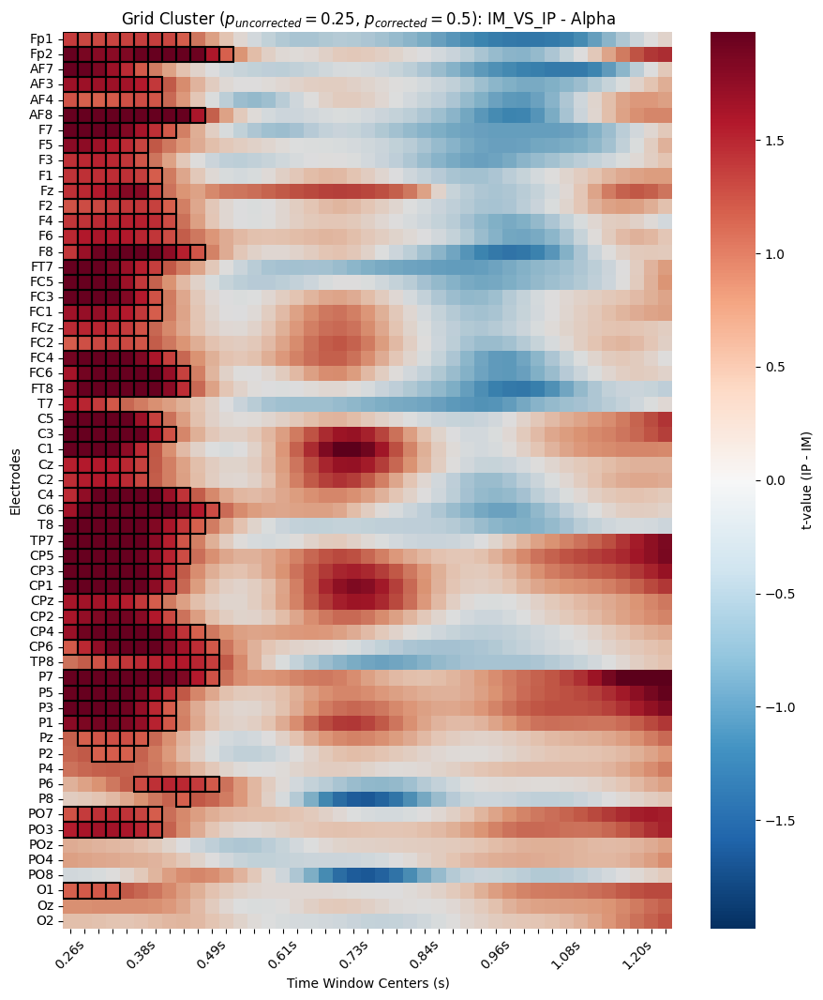

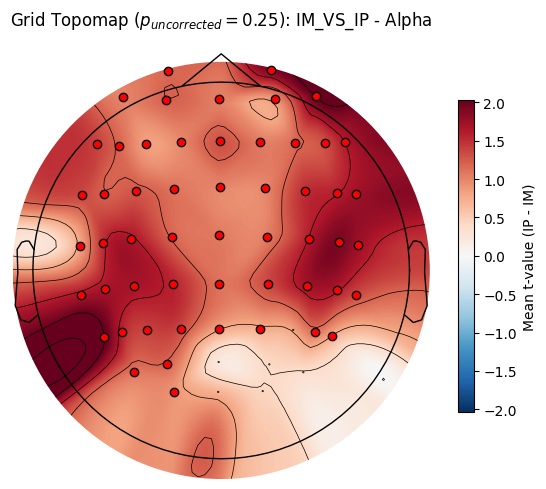


---> Plotting Unique Cluster #2 (ROI: none, p_uncorr=0.2, survived p_corr=0.5)


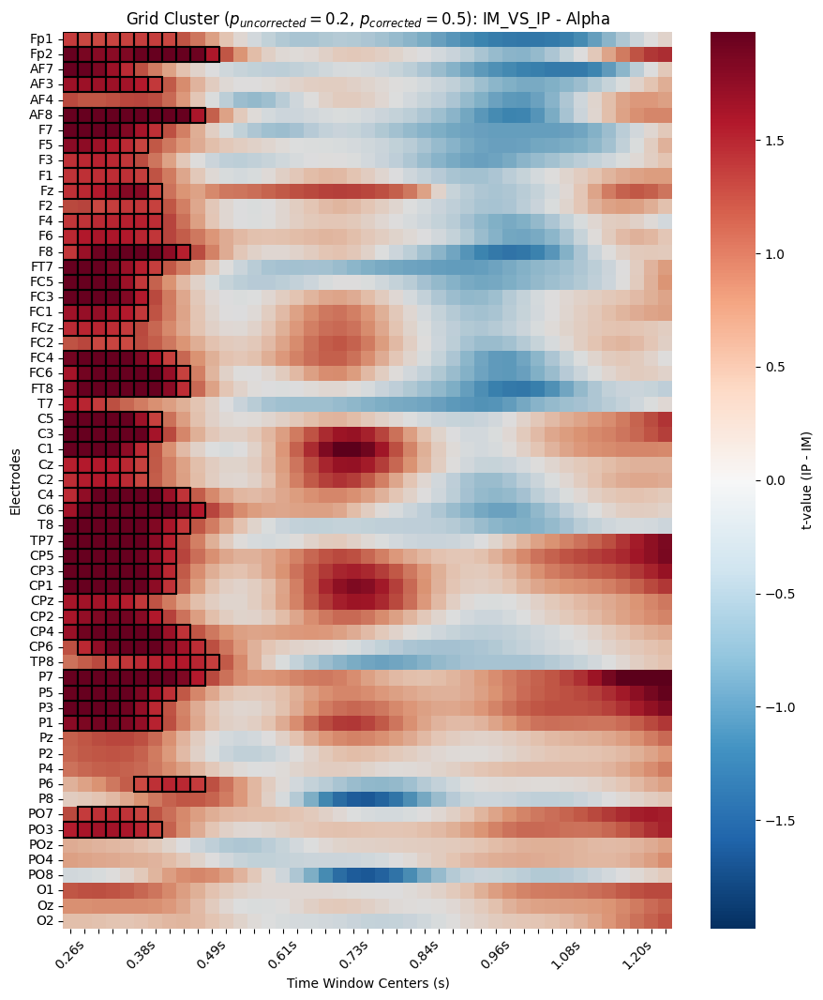

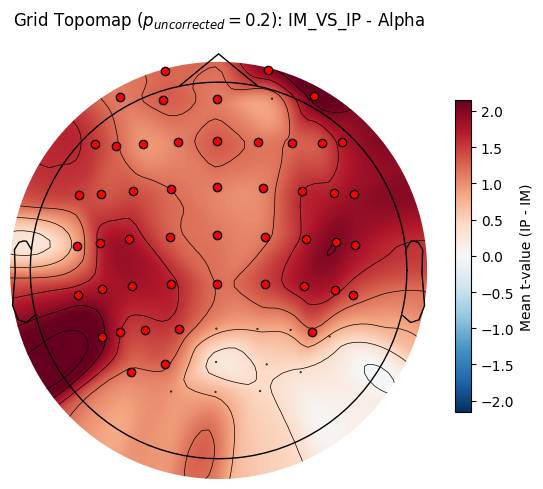


---> Plotting Unique Cluster #3 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


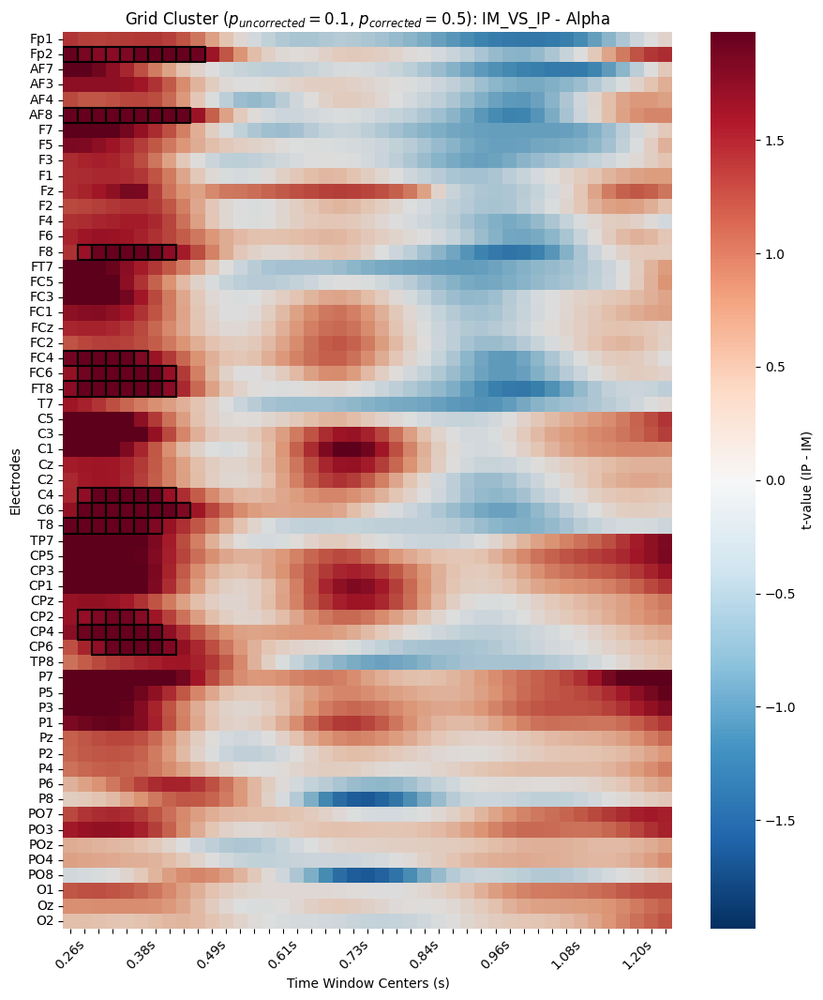

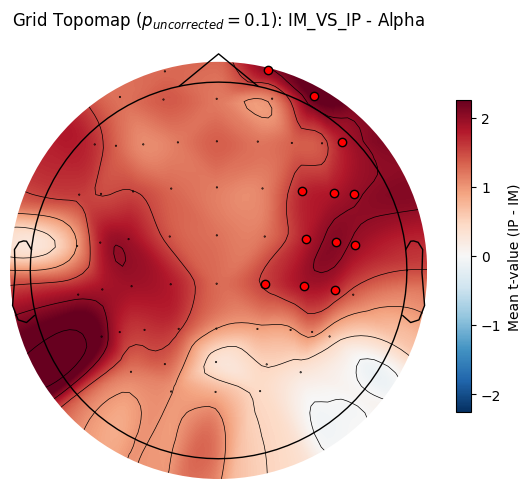


---> Plotting Unique Cluster #4 (ROI: none, p_uncorr=0.1, survived p_corr=0.5)


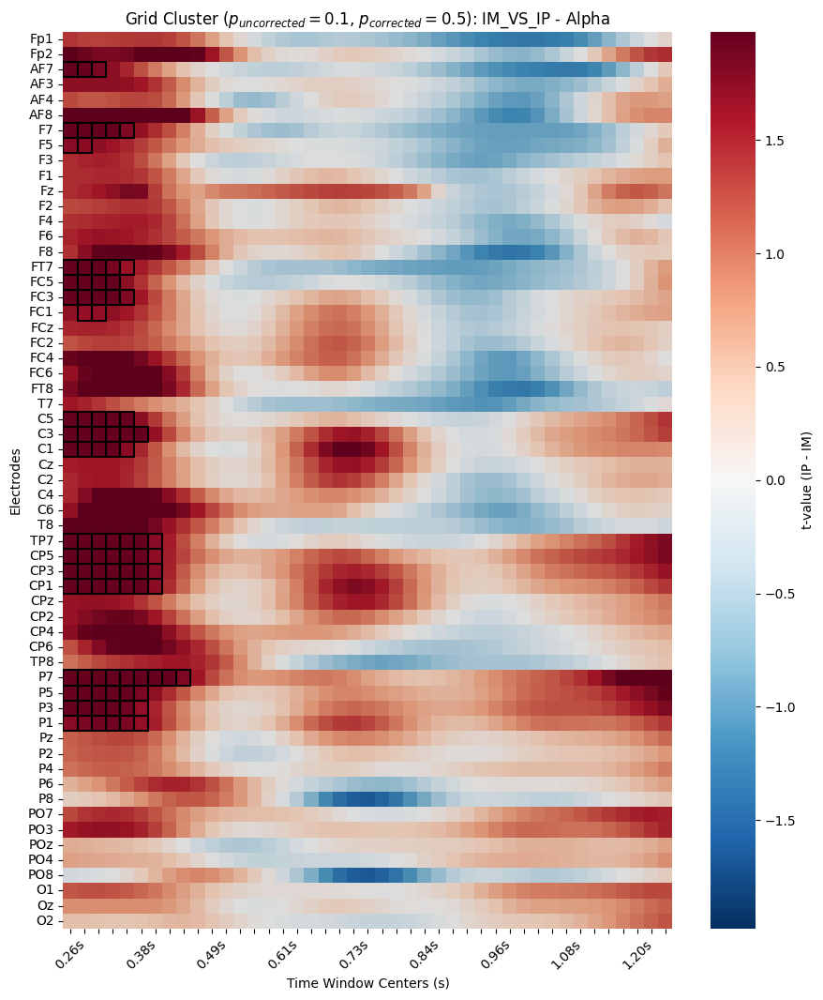

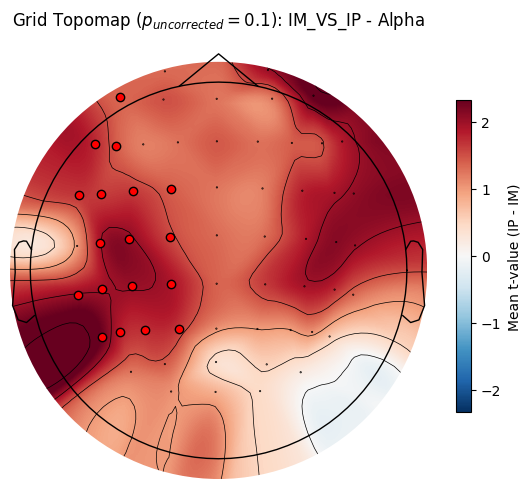


---> Plotting Unique Cluster #5 (ROI: none, p_uncorr=0.05, survived p_corr=0.35)


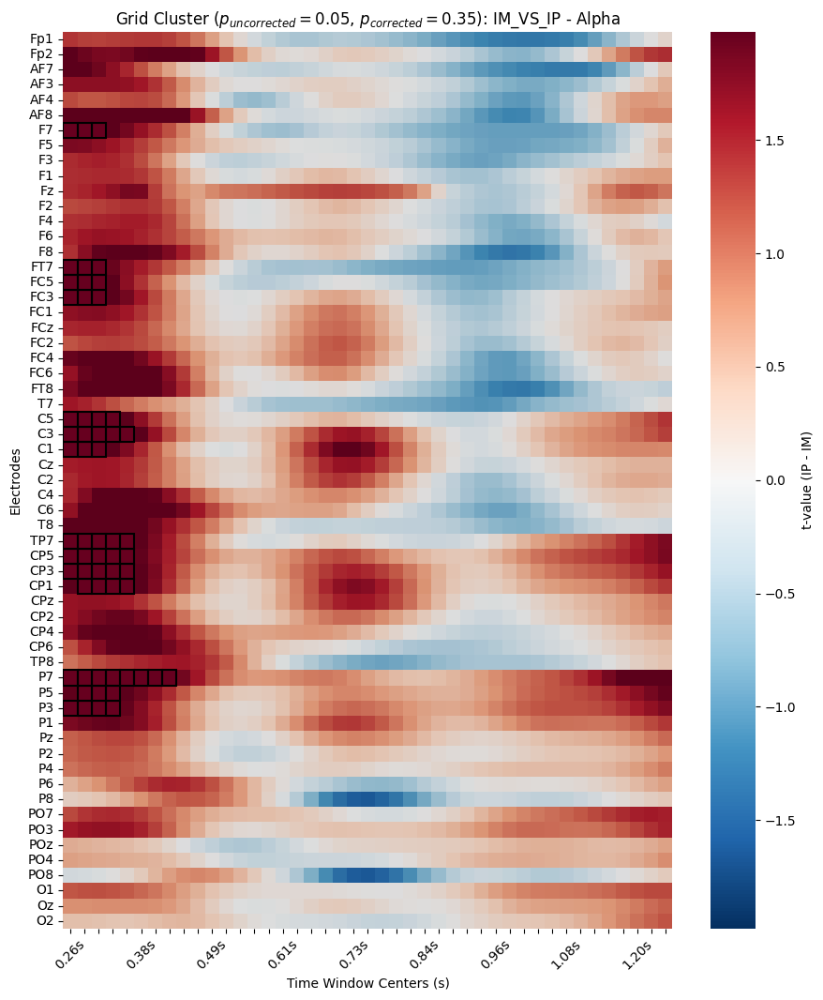

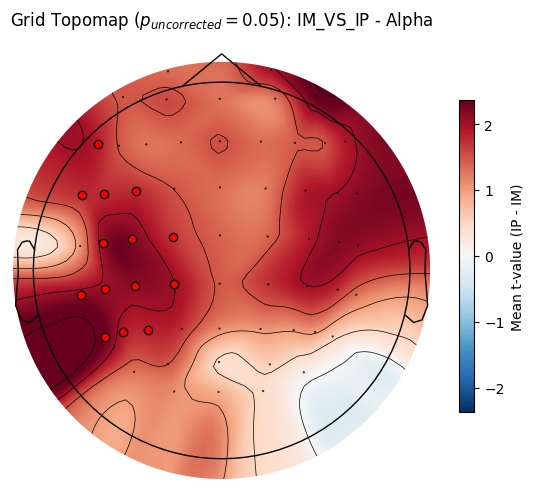


---> Plotting Unique Cluster #6 (ROI: none, p_uncorr=0.05, survived p_corr=0.5)


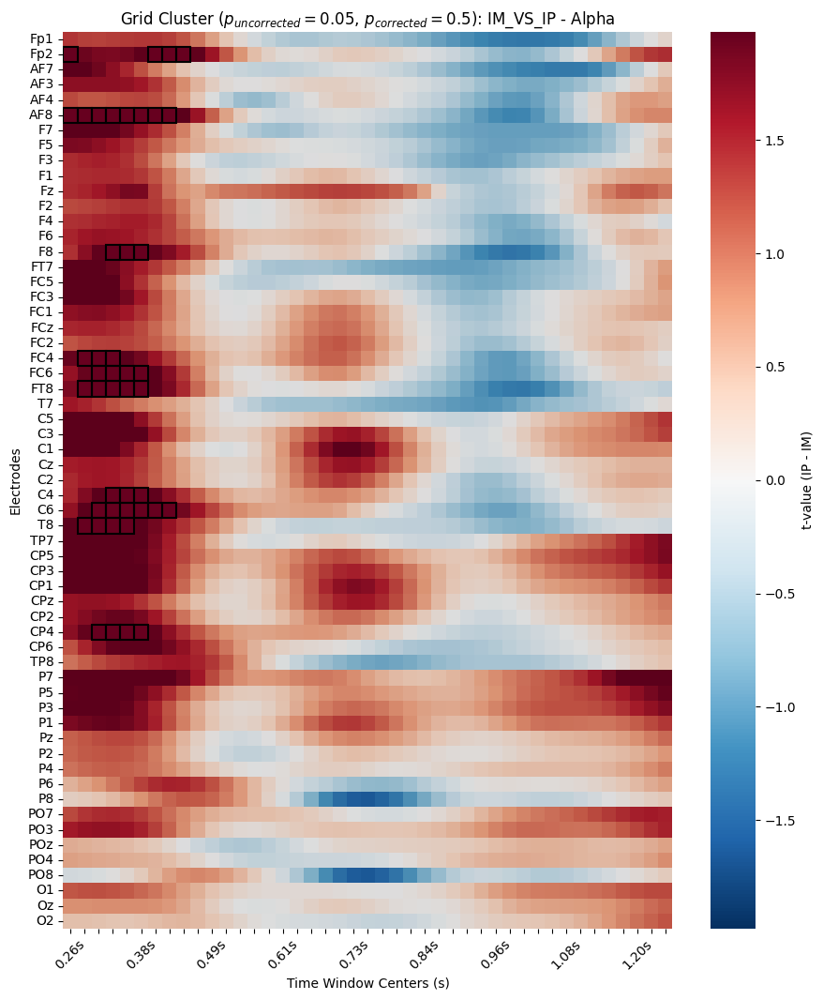

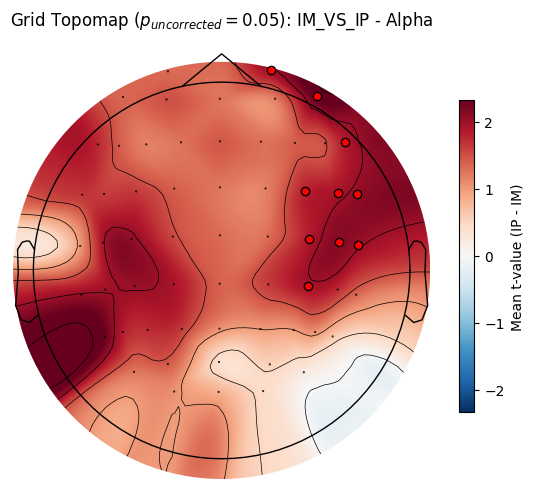


---> Plotting Unique Cluster #7 (ROI: none, p_uncorr=0.01, survived p_corr=0.5)


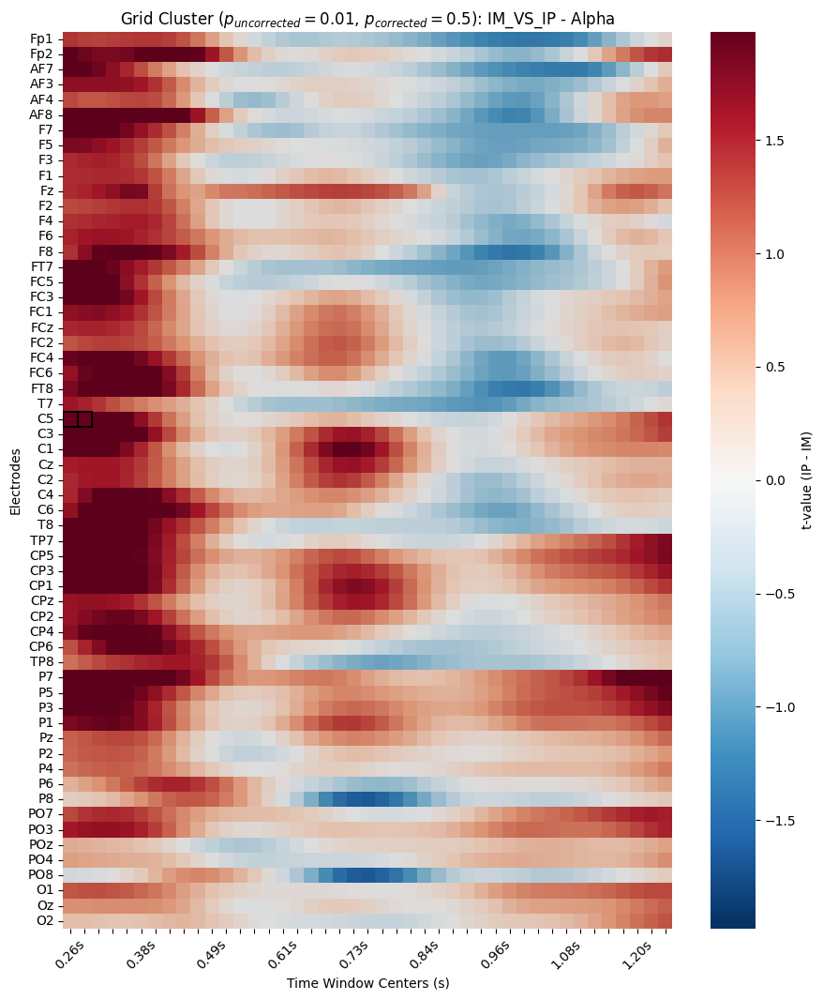

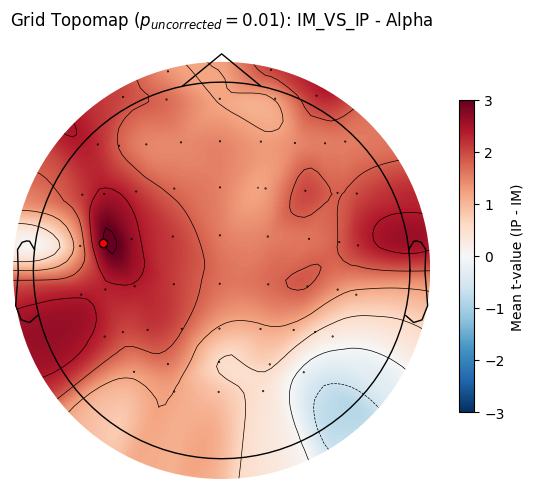


---> Plotting Unique Cluster #8 (ROI: none, p_uncorr=0.005, survived p_corr=0.35)


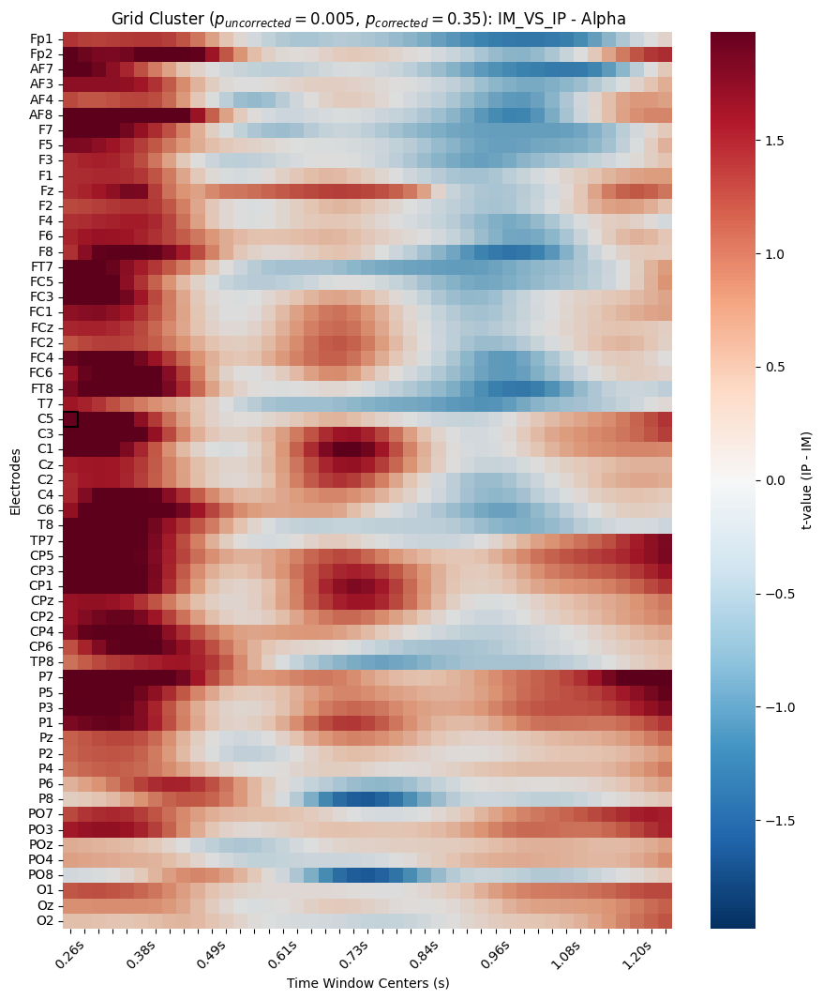

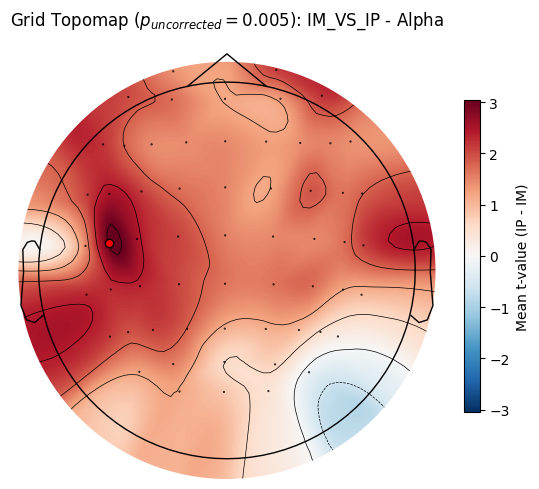


---> Plotting Unique Cluster #9 (ROI: broad, p_uncorr=0.25, survived p_corr=0.5)


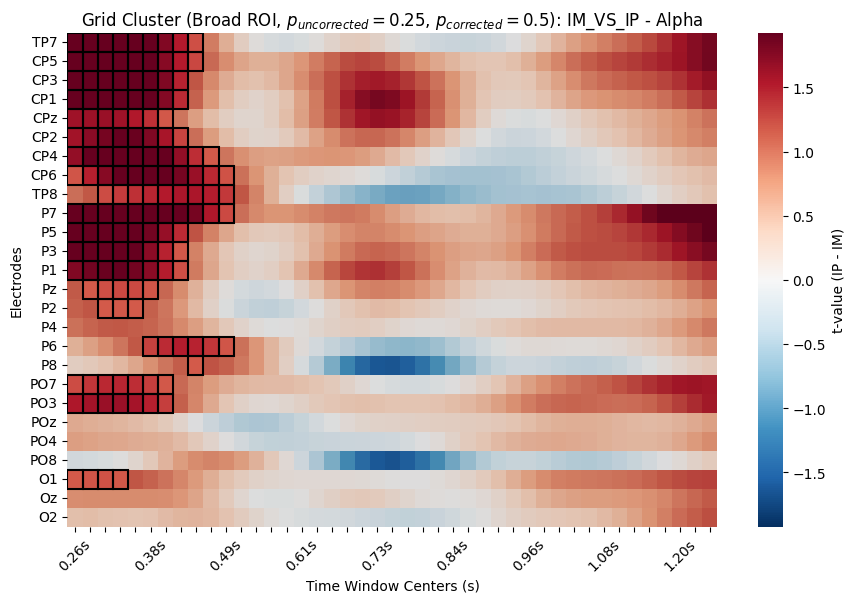

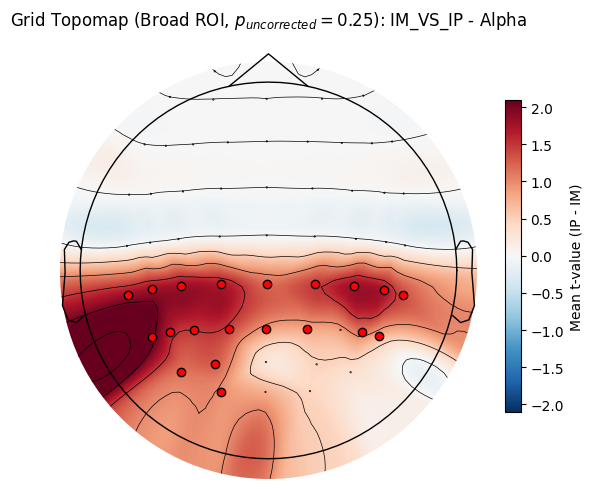


---> Plotting Unique Cluster #10 (ROI: broad, p_uncorr=0.2, survived p_corr=0.5)


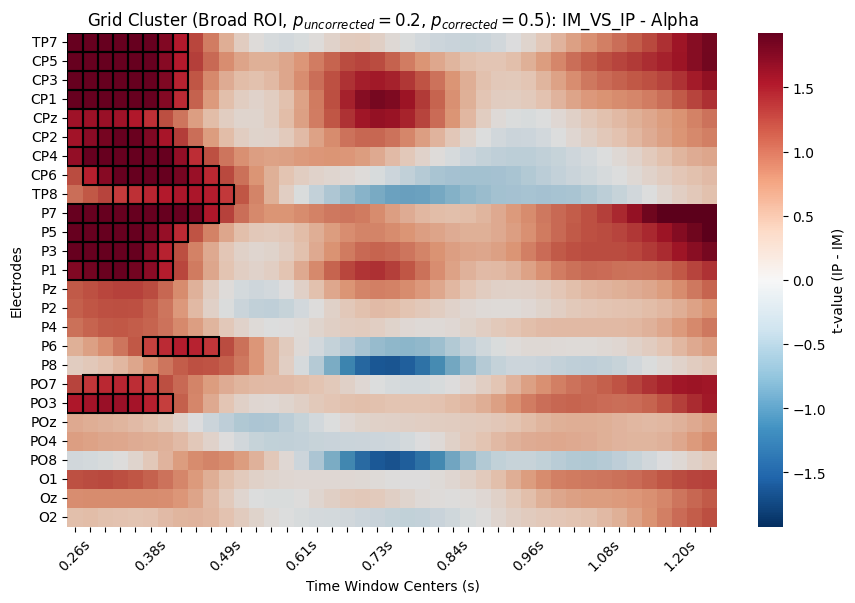

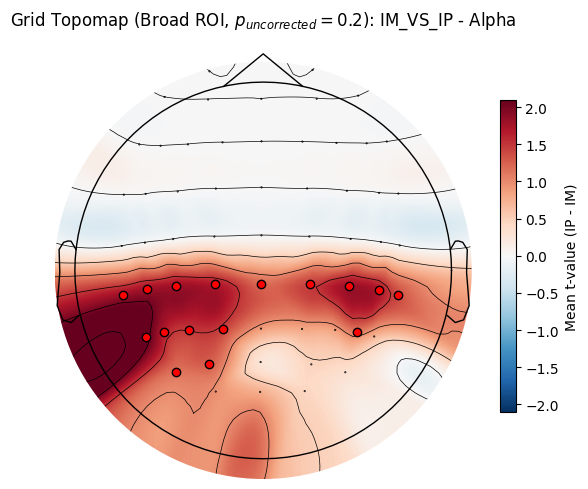


---> Plotting Unique Cluster #11 (ROI: broad, p_uncorr=0.1, survived p_corr=0.4)


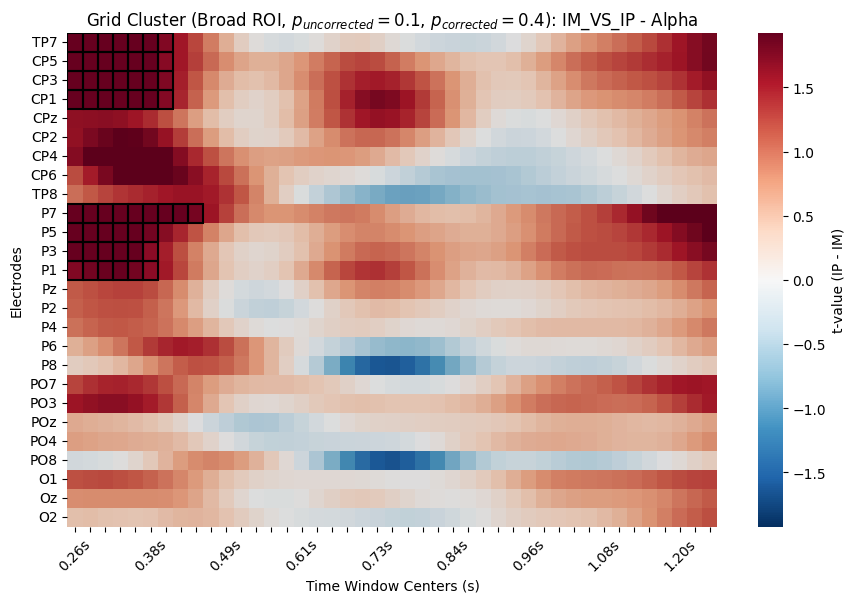

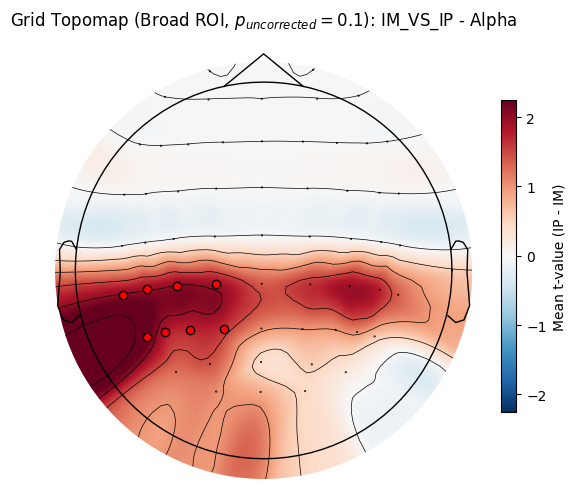


---> Plotting Unique Cluster #12 (ROI: broad, p_uncorr=0.05, survived p_corr=0.3)


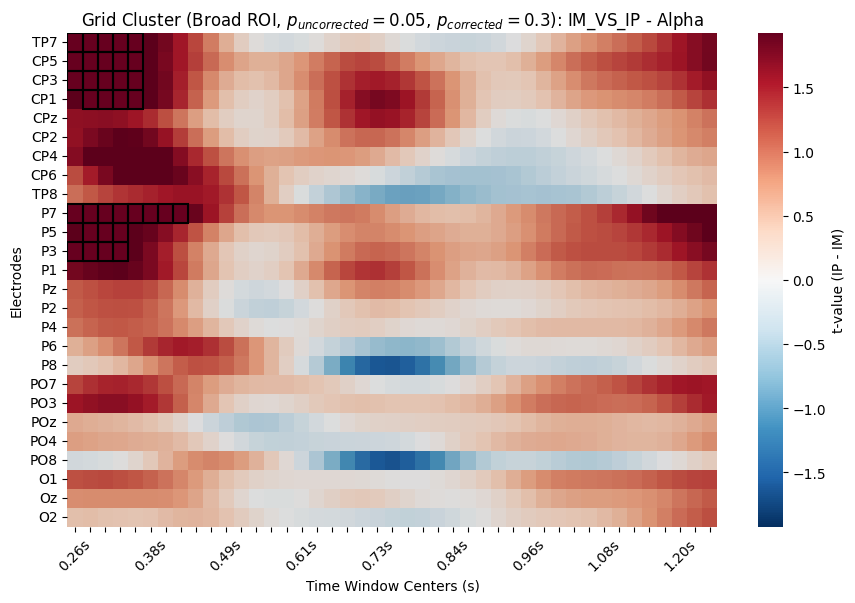

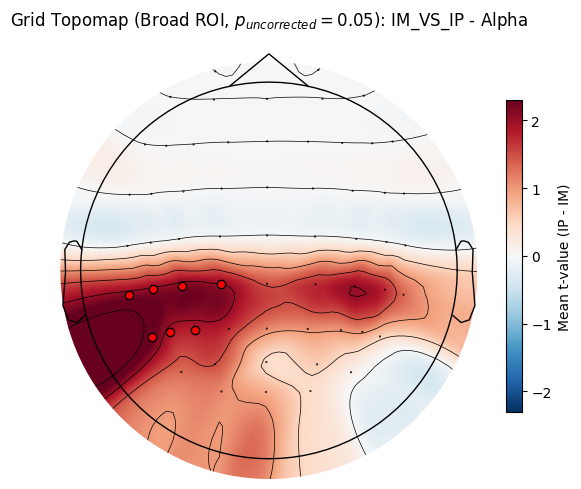


---> Plotting Unique Cluster #13 (ROI: narrow, p_uncorr=0.1, survived p_corr=0.5)


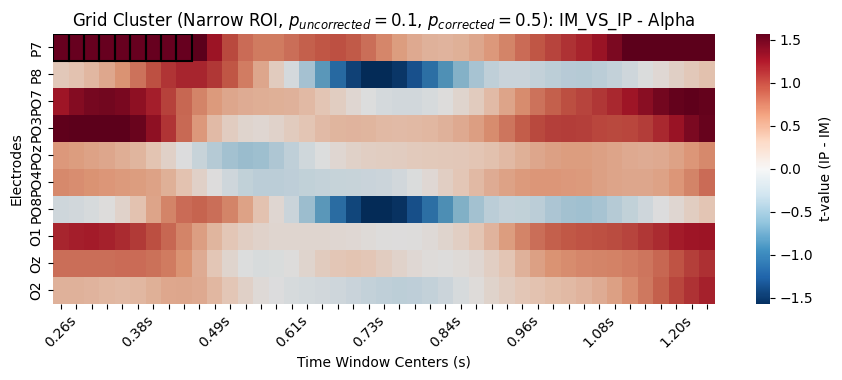

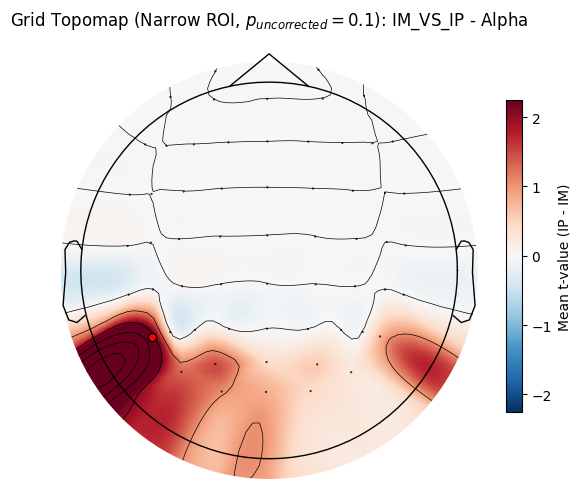


---> Plotting Unique Cluster #14 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.35)


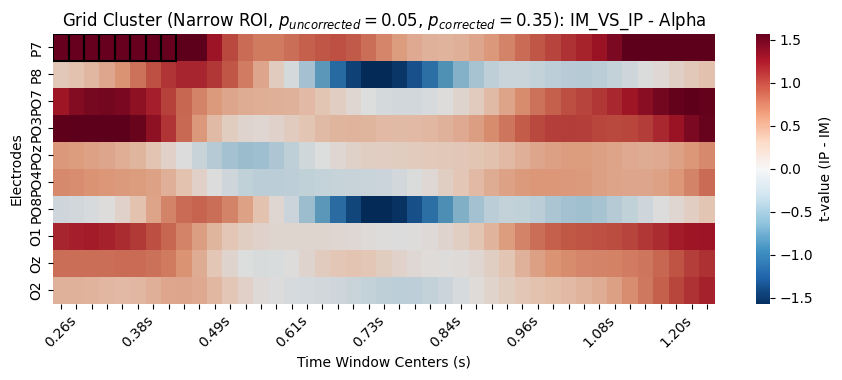

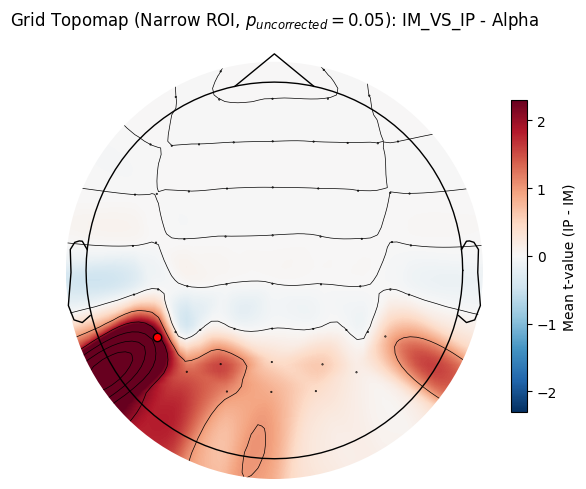


---> Plotting Unique Cluster #15 (ROI: narrow, p_uncorr=0.05, survived p_corr=0.5)


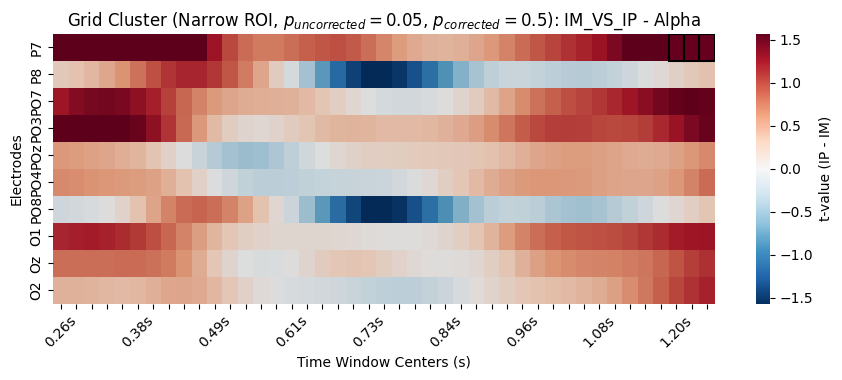

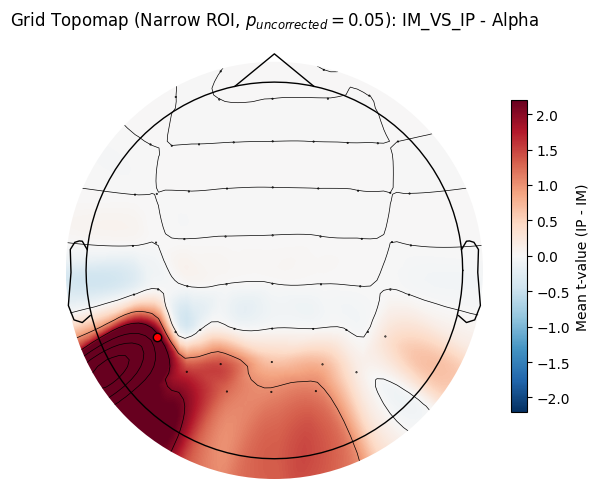

In [19]:
print("\nPlotting IM vs IP Theta significant clusters:")
plot_all_significant_unique_clusters(im_theta_res, im_theta_cache, "im_vs_ip", "theta", paths)

print("\nPlotting IM vs IP Alpha significant clusters:")
plot_all_significant_unique_clusters(im_alpha_res, im_alpha_cache, "im_vs_ip", "alpha", paths)

## 3. Export Chosen Clusters to JSON

Review the plotted clusters, make your selection, and specify them below to export to `cluster_definitions.json` for EEGNet.

Exported C_VS_IP - THETA (from ROI=narrow, p_uncorr=0.01, idx=0)
Exported C_VS_IP - ALPHA (from ROI=none, p_uncorr=0.001, idx=0)
Exported IM_VS_IP - THETA (from ROI=narrow, p_uncorr=0.05, idx=0)
Exported IM_VS_IP - ALPHA (from ROI=broad, p_uncorr=0.05, idx=0)

Saved chosen cluster definitions to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cluster_definitions.json
{
    "c_vs_ip": {
        "theta": {
            "channels": [
                "Fz",
                "FCz"
            ],
            "tmin": 1.171875,
            "tmax": 1.2421875
        },
        "alpha": {
            "channels": [
                "FC3",
                "FC1",
                "FC2",
                "C3",
                "C1",
                "Cz",
                "C2",
                "CP3",
                "CP1",
                "CPz",
                "CP2",
                "CP4",
                "P5",
                "P3",
                "P1",
                "Pz",
                "P2

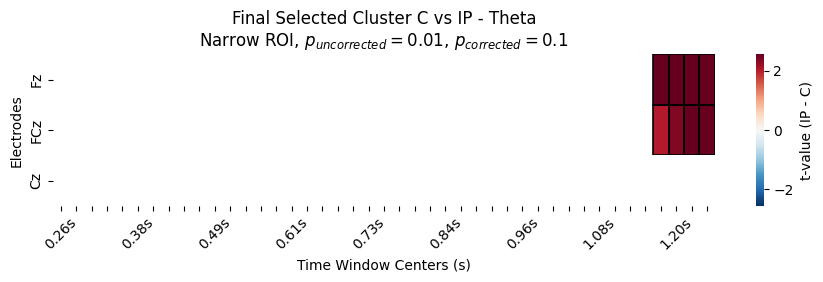

Final masked heatmap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_heatmap_c_vs_ip_theta_narrow.png


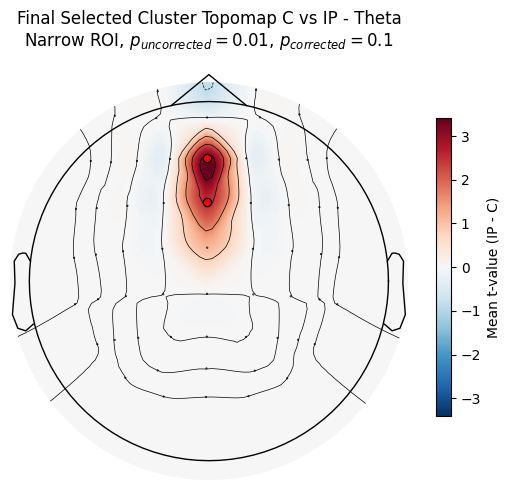

Final masked topomap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_topomap_c_vs_ip_theta_narrow.png


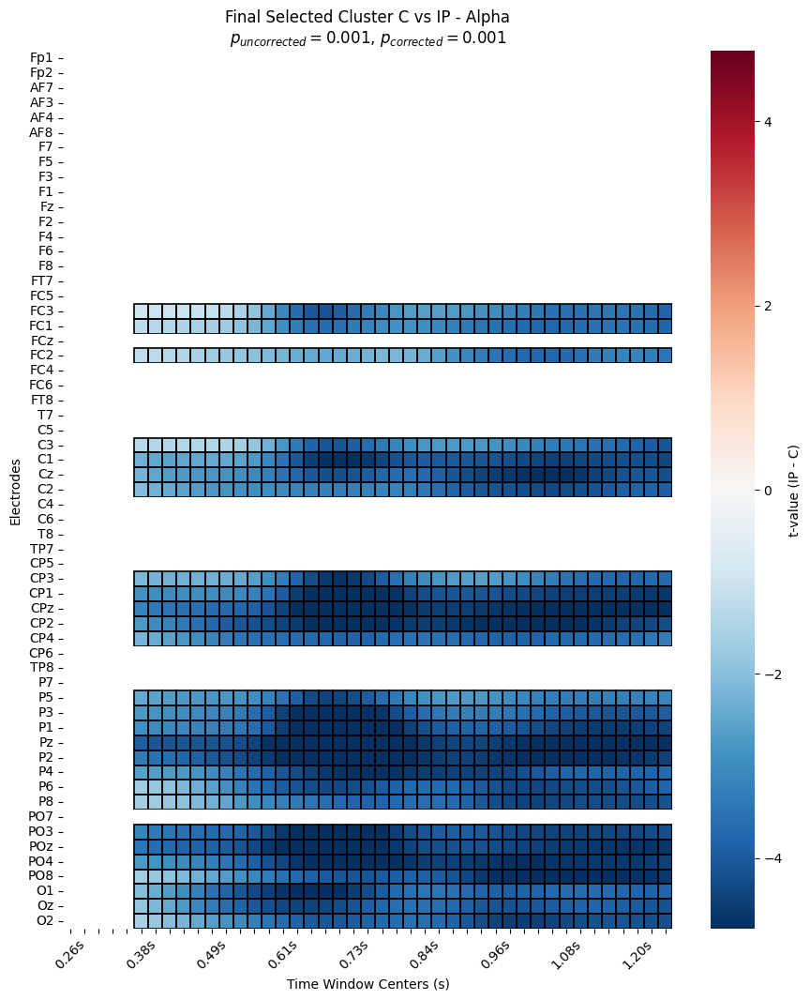

Final masked heatmap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_heatmap_c_vs_ip_alpha_none.png


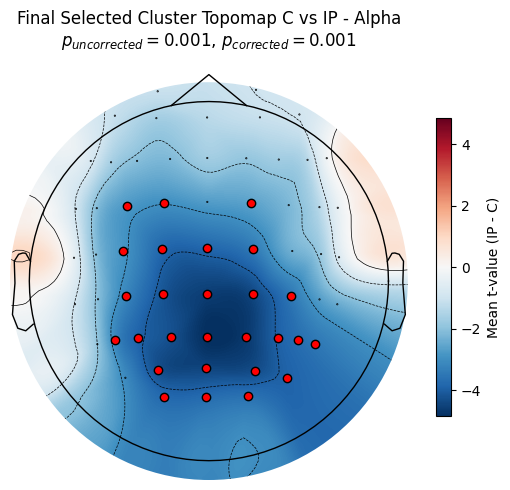

Final masked topomap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_topomap_c_vs_ip_alpha_none.png


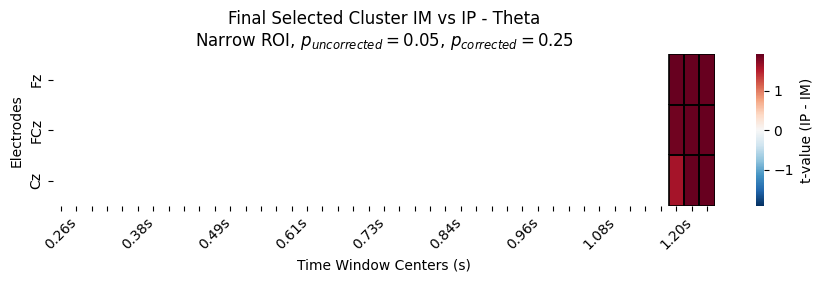

Final masked heatmap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_heatmap_im_vs_ip_theta_narrow.png


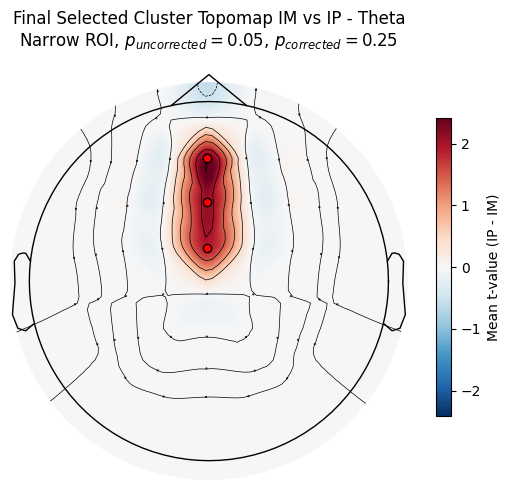

Final masked topomap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_topomap_im_vs_ip_theta_narrow.png


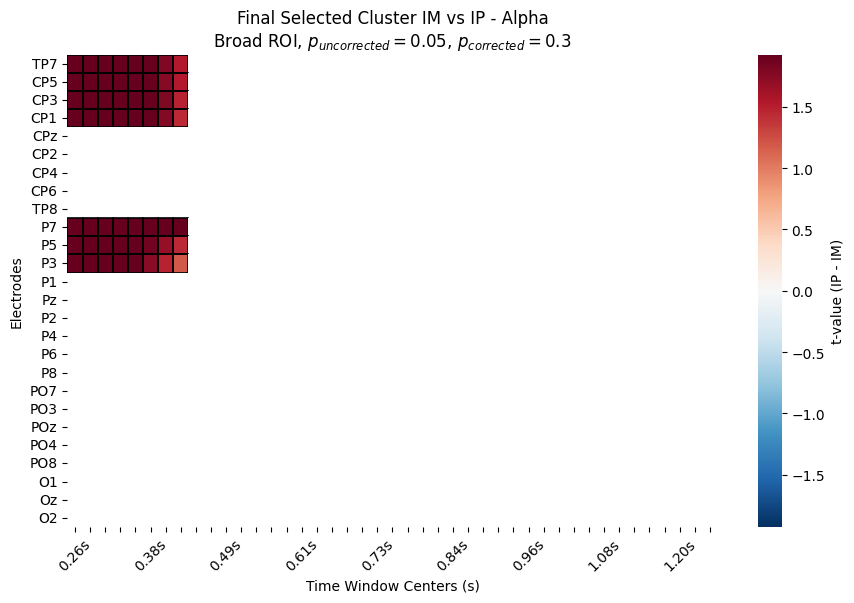

Final masked heatmap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_heatmap_im_vs_ip_alpha_broad.png


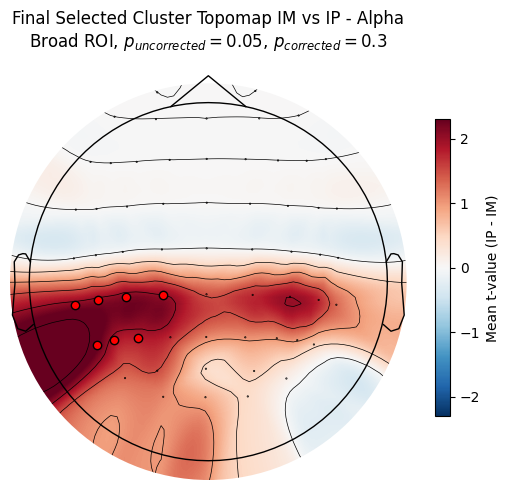

Final masked topomap saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/final_masked_topomap_im_vs_ip_alpha_broad.png


In [20]:
# MANUALLY SPECIFY CHOSEN THRESHOLDS FOR EXPORT TO EEGNET HERE!
CHOSEN_CLUSTERS = {
    "c_vs_ip": {
        "alpha": {
            "roi_mode": "none",
            "p_uncorrected": 0.001,
            "cluster_idx": 0,
            "fallback_res": c_alpha_res,
            "cache": c_alpha_cache,
        },
        "theta": {
            "roi_mode": "narrow",
            "p_uncorrected": 0.01,
            "cluster_idx": 0,
            "fallback_res": c_theta_res,
            "cache": c_theta_cache,
        },
    },
    "im_vs_ip": {
        "alpha": {
            "roi_mode": "broad",
            "p_uncorrected": 0.05,
            "cluster_idx": 0,
            "fallback_res": im_alpha_res,
            "cache": im_alpha_cache,
        },
        "theta": {
            "roi_mode": "narrow",
            "p_uncorrected": 0.05,
            "cluster_idx": 0,
            "fallback_res": im_theta_res,
            "cache": im_theta_cache,
        },
    },
}


def select_and_export_chosen_clusters():
    export_definitions = {
        "c_vs_ip": {
            "theta": {"channels": [], "tmin": None, "tmax": None},
            "alpha": {"channels": [], "tmin": None, "tmax": None},
        },
        "im_vs_ip": {
            "theta": {"channels": [], "tmin": None, "tmax": None},
            "alpha": {"channels": [], "tmin": None, "tmax": None},
        },
    }

    for task in ["c_vs_ip", "im_vs_ip"]:
        for band in ["theta", "alpha"]:
            config = CHOSEN_CLUSTERS[task][band]
            roi_mode = config["roi_mode"]
            p_uncorr = config["p_uncorrected"]
            c_idx = config["cluster_idx"]
            res_list = config["fallback_res"]

            if p_uncorr is not None and c_idx is not None:
                # Find matching cluster in results list
                match = [
                    c
                    for c in res_list
                    if c["roi_mode"] == roi_mode and c["p_uncorrected"] == p_uncorr and c["cluster_idx"] == c_idx
                ]
                if match:
                    export_definitions[task][band] = {
                        "channels": match[0]["channels"],
                        "tmin": match[0]["tmin"],
                        "tmax": match[0]["tmax"],
                    }
                    print(
                        f"Exported {task.upper()} - {band.upper()} (from ROI={roi_mode}, p_uncorr={p_uncorr}, idx={c_idx})"
                    )
                    continue

            # Fallback check: if anything survived at p_corrected <= 0.05, export first one automatically
            strict_sig = [c for c in res_list if c["p_corrected"] <= 0.05]
            if strict_sig:
                export_definitions[task][band] = {
                    "channels": strict_sig[0]["channels"],
                    "tmin": strict_sig[0]["tmin"],
                    "tmax": strict_sig[0]["tmax"],
                }
                print(
                    f"Exported strict significant {task.upper()} - {band.upper()} (ROI={strict_sig[0]['roi_mode']}, p_uncorr={strict_sig[0]['p_uncorrected']})"
                )
            else:
                print(f"No cluster exported for {task.upper()} - {band.upper()} (will use EEGNet defaults)")

    out_json_dir = paths.analysis_root / "clustering"
    out_json_dir.mkdir(parents=True, exist_ok=True)
    out_json_path = out_json_dir / "cluster_definitions.json"
    with open(out_json_path, "w") as f:
        json.dump(export_definitions, f, indent=4)
    print(f"\nSaved chosen cluster definitions to: {out_json_path}")
    print(json.dumps(export_definitions, indent=4))


select_and_export_chosen_clusters()


def plot_final_masked_cluster(task_name, band_name, config, paths):
    """
    Plot the chosen cluster with solid white masking for non-cluster regions
    and t-values shown for the entire duration of the cluster's channels.
    """
    roi_mode = config["roi_mode"]
    p_uncorr = config["p_uncorrected"]
    c_idx = config["cluster_idx"]
    res_list = config["fallback_res"]
    diff_maps_cache = config["cache"]

    cluster = None
    if p_uncorr is not None and c_idx is not None:
        match = [
            c
            for c in res_list
            if c["roi_mode"] == roi_mode and c["p_uncorrected"] == p_uncorr and c["cluster_idx"] == c_idx
        ]
        if match:
            cluster = match[0]

    if cluster is None:
        strict_sig = [c for c in res_list if c["p_corrected"] <= 0.05]
        if strict_sig:
            cluster = strict_sig[0]
            roi_mode = cluster["roi_mode"]

    if cluster is None:
        print(f"No significant cluster to plot for {task_name.upper()} - {band_name.upper()}.")
        return

    # Unpack 5 elements
    X_diff, times, ch_names_to_use, info_to_use, full_info = diff_maps_cache[roi_mode]

    t_vals, _ = ttest_1samp(X_diff, popmean=0.0, axis=0)
    t_vals = t_vals.T

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names_to_use)}
    present_order = [ch for ch in CHANNEL_ORDER if ch in ch_to_idx]
    ordered_idx = [ch_to_idx[ch] for ch in present_order]
    t_vals_ordered = t_vals[ordered_idx, :]

    # Linear function: y = m*x + n where x is len(present_order), m=0.14, n=2.5
    fig_height = len(present_order) * 0.14 + 2.5
    fig, ax = plt.subplots(figsize=(9, fig_height))
    vmax = float(np.percentile(np.abs(t_vals_ordered), 95))
    if vmax == 0:
        vmax = 1.0

    xticklabels = [f"{t:.2f}s" if idx % 5 == 0 else "" for idx, t in enumerate(times)]

    sns.heatmap(
        t_vals_ordered,
        ax=ax,
        cmap="RdBu_r",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=xticklabels,
        yticklabels=present_order,
        cbar_kws={"label": f"t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})"},
    )

    ch_in_cluster = set(cluster["channels"])
    tmin_val, tmax_val = cluster["tmin"], cluster["tmax"]

    cluster_box_mask = np.zeros((len(present_order), len(times)), dtype=bool)
    for i, ch in enumerate(present_order):
        if ch in ch_in_cluster:
            for j, t in enumerate(times):
                if tmin_val <= t <= tmax_val:
                    cluster_box_mask[i, j] = True

    for i in range(t_vals_ordered.shape[0]):
        for j in range(t_vals_ordered.shape[1]):
            if cluster_box_mask[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=1.2))
            else:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=True, color="white", linewidth=0))

    # LaTeX formatting for p_uncorrected and p_corrected and omit NONE ROI
    roi_label = f"{roi_mode.capitalize()} ROI, " if roi_mode.lower() in ["broad", "narrow"] else ""
    ax.set_title(
        f"Final Selected Cluster {task_name.split('_')[0].upper()} vs {task_name.split('_')[-1].upper()} - {band_name.capitalize()}\n{roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$"
    )
    ax.set_xlabel("Time Window Centers (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    heatmap_path = paths.figures_dir / f"final_masked_heatmap_{task_name}_{band_name}_{roi_mode}.png"
    plt.savefig(heatmap_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Final masked heatmap saved to: {heatmap_path}")

    # Topomap
    topo_path = paths.figures_dir / f"final_masked_topomap_{task_name}_{band_name}_{roi_mode}.png"
    fig, ax = plt.subplots(figsize=(6, 5))
    active_times = list(set(cluster["mask"][0]))
    t_avg = np.mean(t_vals[:, active_times], axis=1)
    t_avg_full = np.zeros(len(full_info.ch_names))
    mask_full = np.zeros(len(full_info.ch_names), dtype=bool)
    for ch_idx, ch_name in enumerate(ch_names_to_use):
        full_idx = full_info.ch_names.index(ch_name)
        t_avg_full[full_idx] = t_avg[ch_idx]
        if ch_name in cluster["channels"]:
            mask_full[full_idx] = True
    t_max = max(abs(t_avg_full.min()), abs(t_avg_full.max()))
    if t_max == 0:
        t_max = 1.0
    im, _ = mne.viz.plot_topomap(
        t_avg_full,
        full_info,
        axes=ax,
        mask=mask_full,
        mask_params=dict(marker="o", markerfacecolor="red", markersize=6, markeredgecolor="k"),
        cmap="RdBu_r",
        vlim=(-t_max, t_max),
        show=False,
    )
    cbar = fig.colorbar(im, ax=ax, orientation="vertical", shrink=0.7)
    cbar.set_label(f"Mean t-value ({'IP - C' if task_name == 'c_vs_ip' else 'IP - IM'})")
    ax.set_title(
        f"Final Selected Cluster Topomap {task_name.split('_')[0].upper()} vs {task_name.split('_')[-1].upper()} - {band_name.capitalize()}\n{roi_label}$p_{{uncorrected}} = {cluster['p_uncorrected']}$, $p_{{corrected}} = {cluster['p_corrected']}$"
    )
    plt.tight_layout()
    plt.savefig(topo_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Final masked topomap saved to: {topo_path}")


print("\nGenerating final masked plots for the selected 4 clusters...")
for task in ["c_vs_ip", "im_vs_ip"]:
    for band in ["theta", "alpha"]:
        plot_final_masked_cluster(task, band, CHOSEN_CLUSTERS[task][band], paths)

## 4. Chosen-Threshold Topomap Grid

This grid summarizes the selected clusters from the first clustering section at fixed time points. Each row is one task-band pair from `CHOSEN_CLUSTERS`; each column is the requested time point. The map colors show cohort-level t-values at the closest available STFT window center, while red markers indicate electrodes that belong to the selected cluster at that same window.


[C_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_c_vs_ip_sfreq128.joblib...
[C_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_c_vs_ip_sfreq128.joblib...
[IM_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_im_vs_ip_sfreq128.joblib...
[IM_VS_IP] Loading cached dataset from /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/cache/raw_epochs_dataset_im_vs_ip_sfreq128.joblib...


/tmp/ipykernel_16800/4278465451.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


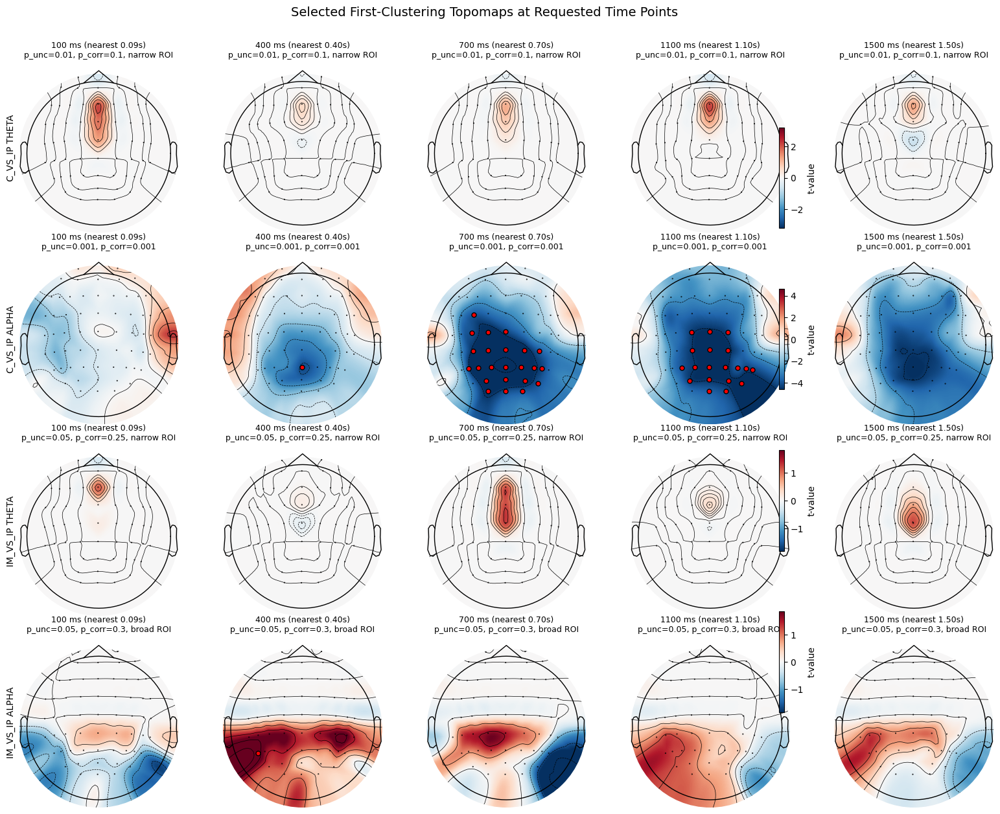

Chosen-threshold topomap grid saved to: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/clustering/figures/chosen_threshold_topomap_grid.png


In [21]:
def _find_selected_cluster(config):
    """Return the cluster selected in CHOSEN_CLUSTERS, with strict-significance fallback."""
    roi_mode = config["roi_mode"]
    p_uncorr = config["p_uncorrected"]
    c_idx = config["cluster_idx"]
    res_list = config["fallback_res"]

    if p_uncorr is not None and c_idx is not None:
        match = [
            c
            for c in res_list
            if c["roi_mode"] == roi_mode and c["p_uncorrected"] == p_uncorr and c["cluster_idx"] == c_idx
        ]
        if match:
            return match[0], roi_mode

    strict_sig = [c for c in res_list if c["p_corrected"] <= 0.05]
    if strict_sig:
        return strict_sig[0], strict_sig[0]["roi_mode"]
    return None, roi_mode


def plot_chosen_threshold_topomap_grid(
    chosen_clusters,
    paths,
    target_times_ms=(100, 400, 700, 1100, 1500),
    max_time_delta=0.04,
):
    """
    Plot selected first-clustering topomaps at requested times.
    The topomap values are recomputed on 0.0-1.5 s so the requested time points are available.
    Red markers are shown only when the selected cohort cluster is active at the nearest
    original first-clustering time window.
    silently showing a distant time point.
    """
    rows = [(task, band) for task in ["c_vs_ip", "im_vs_ip"] for band in ["theta", "alpha"]]
    target_times = np.array(target_times_ms, dtype=float) / 1000.0

    fig, axes = plt.subplots(
        nrows=len(rows),
        ncols=len(target_times),
        figsize=(3.2 * len(target_times), 3.1 * len(rows)),
        squeeze=False,
    )

    for row_idx, (task, band) in enumerate(rows):
        config = chosen_clusters[task][band]
        cluster, roi_mode = _find_selected_cluster(config)
        label = f"{task.upper()} {band.upper()}"

        if cluster is None:
            for ax in axes[row_idx]:
                ax.axis("off")
                ax.set_title(f"{label}\nNo selected cluster")
            continue

        _, cluster_times, _, _, _ = config["cache"][roi_mode]
        freqs_range = (4, 7) if band == "theta" else (8, 12)
        roi_channels = THETA_ROIS[roi_mode] if band == "theta" else ALPHA_ROIS[roi_mode]

        X_plot, plot_times, ch_names_to_use, _, full_info = compute_stft_difference_maps(
            task,
            band,
            freqs_range,
            paths,
            roi_channels=roi_channels,
            active_window=(0.0, 1.5),
        )
        t_vals, _ = ttest_1samp(X_plot, popmean=0.0, axis=0)
        t_vals = np.nan_to_num(t_vals, nan=0.0)

        vmax = float(np.nanpercentile(np.abs(t_vals), 95))
        if vmax == 0:
            vmax = 1.0

        time_mask, ch_mask = cluster["mask"]
        active_by_time = {int(t_idx): set() for t_idx in np.unique(time_mask)}
        for t_idx, ch_idx in zip(time_mask, ch_mask):
            active_by_time[int(t_idx)].add(int(ch_idx))

        last_im = None
        for col_idx, target_t in enumerate(target_times):
            ax = axes[row_idx, col_idx]
            nearest_idx = int(np.argmin(np.abs(plot_times - target_t)))
            nearest_t = float(plot_times[nearest_idx])
            nearest_cluster_idx = int(np.argmin(np.abs(cluster_times - target_t)))
            cluster_delta = abs(float(cluster_times[nearest_cluster_idx]) - target_t)

            topo = np.zeros(len(full_info.ch_names))
            mask = np.zeros(len(full_info.ch_names), dtype=bool)
            for local_ch_idx, ch_name in enumerate(ch_names_to_use):
                full_idx = full_info.ch_names.index(ch_name)
                topo[full_idx] = t_vals[nearest_idx, local_ch_idx]
                if cluster_delta <= max_time_delta and local_ch_idx in active_by_time.get(nearest_cluster_idx, set()):
                    mask[full_idx] = True
            last_im, _ = mne.viz.plot_topomap(
                topo,
                full_info,
                axes=ax,
                mask=mask,
                mask_params=dict(marker="o", markerfacecolor="red", markersize=5, markeredgecolor="k"),
                cmap="RdBu_r",
                vlim=(-vmax, vmax),
                show=False,
            )

            roi_label = f", {roi_mode} ROI" if roi_mode != "none" else ""
            threshold_label = f"p_unc={cluster['p_uncorrected']}, p_corr={cluster['p_corrected']}"
            ax.set_title(
                f"{int(target_t * 1000)} ms (nearest {nearest_t:.2f}s)\n{threshold_label}{roi_label}", fontsize=9
            )
            if col_idx == 0:
                ax.set_ylabel(label, fontsize=10)

        if last_im is not None:
            cbar = fig.colorbar(last_im, ax=axes[row_idx, :], orientation="vertical", shrink=0.75, pad=0.01)
            cbar.set_label("t-value")

    fig.suptitle("Selected First-Clustering Topomaps at Requested Time Points", y=1.01, fontsize=14)
    plt.tight_layout()
    out_path = paths.figures_dir / "chosen_threshold_topomap_grid.png"
    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Chosen-threshold topomap grid saved to: {out_path}")


plot_chosen_threshold_topomap_grid(CHOSEN_CLUSTERS, paths)

## 5. ROI Timecourse Plots with 1D Cluster-based Permutation Significance (Five Analysis Configurations)

To validate the neural correlates of conflict and reconcile the difference in statistical results, we implement five configurations of time-frequency analyses:

### Version 1: Exact Paper Replication
- **Subjects**: All 47 subjects loaded from the processed cache (uses all trials per subject, without ML class-balancing undersampling, maximizing SNR).
- **Time Window**: Cropped to the paper's exact window (`-740` to `1500` ms) to prevent boundary artifacts.
- **ROIs**: Fixed standard paper ROIs (narrow frontal `["Fz", "FCz", "Cz"]` for Theta; narrow parieto-occipital for Alpha).

### Version 2: Data-Driven Clustering Improvement
- **ROIs**: Instead of assuming a fixed ROI, we average power only over the *specific electrodes that were identified as part of the significant spatiotemporal cluster* from our grid search. This isolates the spatial pattern of interest and boosts statistical sensitivity.

### Version 3: Global Timecourses (All Electrodes, Theta/Alpha)
- **ROIs**: Averaged across ALL 64 electrodes and all N=47 subjects, presenting a global, unbiased view of the Theta (5-7 Hz) and Alpha (8-12 Hz) dynamics.

### Version 4: Global Broadband Timecourses (All Electrodes, 1-40 Hz)
- **ROIs**: Averaged across ALL 64 electrodes and all N=47 subjects over the full broadband spectrum (1-40 Hz) to monitor overall cognitive control and conflict dynamics.

### Version 5: Global Time-Frequency Spectrograms
- **Analysis**: Shows the Time-Frequency Representation (TFR) power difference (Incongruent Pure - Congruent, and Incongruent Pure - Incongruent Mixed) across all electrodes and N=47 subjects from 1 to 40 Hz to map the complete spectral signature of rivalry conflict.


In [2]:
def load_subject_conditions(fif_path):
    """Helper to load a subject epo file, convert units to standard Volts, and split by condition."""
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    for ch in ep.info["chs"]:
        if ch["unit"] == 0:
            ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ch["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE
    ep._data *= 1e-6

    ep.event_id = {f"event_{code}": code for code in np.unique(ep.events[:, 2])}
    conds = {}
    cond_codes = {"Congruent": [1, 2], "Incongruent_Pure": [3, 4, 5, 6], "Incongruent_Mixed": [7, 8]}
    for name, codes in cond_codes.items():
        valid_names = [f"event_{code}" for code in codes if f"event_{code}" in ep.event_id]
        if valid_names:
            conds[name] = ep[valid_names]
        else:
            conds[name] = None
    return conds


def extract_stft_power_timecourses(fif_files, cond_names, band_range, picks=None):
    """Extracts STFT power curves sequentially trial-by-trial for memory efficiency."""
    c0_all = []
    c1_all = []
    times_cropped = None

    for idx_f, f_path in enumerate(fif_files):
        try:
            conds = load_subject_conditions(f_path)
            subject_curves = []

            for name in cond_names:
                ep_cond = conds[name]
                if ep_cond is None:
                    continue
                X = ep_cond.get_data()
                sfreq = ep_cond.info["sfreq"]

                nperseg = int(round(0.5 * sfreq))
                hop = int(round(0.02 * sfreq))
                noverlap = max(0, nperseg - hop)
                nfft = max(nperseg, int(round(sfreq)))

                # Metadata from trial 0
                x_dummy = X[0:1]
                f, t_stft, _ = stft(
                    x_dummy,
                    fs=sfreq,
                    window="hann",
                    nperseg=nperseg,
                    noverlap=noverlap,
                    nfft=nfft,
                    boundary="even",
                    padded=True,
                    axis=-1,
                )
                times_stft = ep_cond.tmin + t_stft

                # Electrode index selection
                if picks is not None:
                    ch_idx = [ep_cond.ch_names.index(ch) for ch in picks if ch in ep_cond.ch_names]
                else:
                    ch_idx = list(range(X.shape[1]))  # all channels

                # Loop trial-by-trial to save memory
                accum = np.zeros((len(f), len(times_stft)))
                for tr in range(len(X)):
                    _, _, z_tr = stft(
                        X[tr],
                        fs=sfreq,
                        window="hann",
                        nperseg=nperseg,
                        noverlap=noverlap,
                        nfft=nfft,
                        boundary="even",
                        padded=True,
                        axis=-1,
                    )
                    accum += np.abs(z_tr[ch_idx]).mean(axis=0) ** 2
                power_avg = accum / len(X)

                # Frequency selection
                f_mask = (f >= band_range[0]) & (f <= band_range[1])
                band_power = power_avg[f_mask, :].mean(axis=0)

                # Baseline correction in dB
                bmask = (times_stft >= -0.74) & (times_stft <= -0.24)
                b = band_power[bmask].mean()
                band_db = 10 * np.log10((band_power + 1e-20) / (b + 1e-20))
                subject_curves.append(band_db)

                if times_cropped is None:
                    t_mask = (times_stft >= -0.74) & (times_stft <= 1.50)
                    times_cropped = times_stft[t_mask]

            if len(subject_curves) == 2:
                # Crop to -0.74 to 1.50 s
                t_mask = (times_stft >= -0.74) & (times_stft <= 1.50)
                c0_all.append(subject_curves[0][t_mask])
                c1_all.append(subject_curves[1][t_mask])
        except Exception as e:
            print(f"Error processing {f_path.stem}: {e}")

    return np.array(c0_all), np.array(c1_all), times_cropped


def extract_custom_roi_power_timecourses(dataset, chosen_defs, task_name, band_name, band_range):
    """Extracts power timecourses over custom ROIs dynamically loaded from json."""
    X_raw = dataset.X
    y = dataset.y
    subjects = dataset.subjects
    ch_names = list(dataset.channel_names)
    sfreq = dataset.sfreq

    cluster_def = chosen_defs.get(task_name, {}).get(band_name)
    roi_channels = cluster_def["channels"]
    picks_idx = [ch_names.index(ch) for ch in roi_channels if ch in ch_names]

    nperseg = int(round(0.5 * sfreq))
    hop = int(round(0.02 * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    # STFT parameters
    x_dummy = X_raw[0:1]
    f, t_stft, _ = stft(
        x_dummy,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="even",
        padded=True,
        axis=-1,
    )
    times_stft = -0.75 + t_stft

    t_mask = (times_stft >= -0.74) & (times_stft <= 1.50)
    times_cropped = times_stft[t_mask]
    bmask = (times_stft >= -0.74) & (times_stft <= -0.24)
    f_mask = (f >= band_range[0]) & (f <= band_range[1])

    sub_cond0 = []
    sub_cond1 = []

    subject_ids = np.unique(subjects)
    for subj_id in subject_ids:
        sub_mask = subjects == subj_id
        X_sub = X_raw[sub_mask]
        y_sub = y[sub_mask]
        X_c0 = X_sub[y_sub == 0]
        X_c1 = X_sub[y_sub == 1]

        if len(X_c0) == 0 or len(X_c1) == 0:
            continue

        accum0 = np.zeros((len(picks_idx), len(f), len(times_stft)))
        for tr in range(len(X_c0)):
            _, _, z0_tr = stft(
                X_c0[tr],
                fs=sfreq,
                window="hann",
                nperseg=nperseg,
                noverlap=noverlap,
                nfft=nfft,
                boundary="even",
                padded=True,
                axis=-1,
            )
            accum0 += np.abs(z0_tr[picks_idx]) ** 2
        p0 = accum0 / len(X_c0)
        b0 = p0[..., bmask].mean(axis=-1, keepdims=True)
        p_db0 = 10 * np.log10((p0 + 1e-20) / (b0 + 1e-20))
        mean_db0 = p_db0[:, f_mask, :].mean(axis=(0, 1))

        accum1 = np.zeros((len(picks_idx), len(f), len(times_stft)))
        for tr in range(len(X_c1)):
            _, _, z1_tr = stft(
                X_c1[tr],
                fs=sfreq,
                window="hann",
                nperseg=nperseg,
                noverlap=noverlap,
                nfft=nfft,
                boundary="even",
                padded=True,
                axis=-1,
            )
            accum1 += np.abs(z1_tr[picks_idx]) ** 2
        p1 = accum1 / len(X_c1)
        b1 = p1[..., bmask].mean(axis=-1, keepdims=True)
        p_db1 = 10 * np.log10((p1 + 1e-20) / (b1 + 1e-20))
        mean_db1 = p_db1[:, f_mask, :].mean(axis=(0, 1))

        sub_cond0.append(mean_db0[t_mask])
        sub_cond1.append(mean_db1[t_mask])

    return np.array(sub_cond0), np.array(sub_cond1), times_cropped


def compute_1d_permutation_and_plot(
    times_cropped, mat0, mat1, label0, label1, color0, color1, tail, title, fig_name, paths
):
    """Calculates baseline correction, 1D cluster-based permutation test, and draws formatted plots."""
    baseline_mask = (times_cropped >= -0.74) & (times_cropped <= -0.24)
    mat0_bc = mat0 - mat0[:, baseline_mask].mean(axis=1, keepdims=True)
    mat1_bc = mat1 - mat1[:, baseline_mask].mean(axis=1, keepdims=True)

    X_diff = mat1_bc - mat0_bc
    df = len(X_diff) - 1
    if tail == 1:
        threshold = t.ppf(1 - 0.05, df)
    elif tail == -1:
        threshold = t.ppf(0.05, df)
    else:
        threshold = None

    t_obs, clusters, cluster_p_values, H0 = mne.stats.permutation_cluster_1samp_test(
        X_diff, n_permutations=10000, tail=tail, threshold=threshold, n_jobs=-1, verbose=False
    )

    fig, ax = plt.subplots(figsize=(7.5, 5))
    mean0, sem0 = mat0_bc.mean(axis=0), mat0_bc.std(axis=0) / np.sqrt(len(mat0_bc))
    mean1, sem1 = mat1_bc.mean(axis=0), mat1_bc.std(axis=0) / np.sqrt(len(mat1_bc))

    times_ms = times_cropped * 1000
    plot_mask = (times_ms >= -700) & (times_ms <= 1400)
    times_plot = times_ms[plot_mask]

    ax.plot(times_plot, mean1[plot_mask], label=label1, color=color1, linewidth=2)
    ax.fill_between(
        times_plot, mean1[plot_mask] - sem1[plot_mask], mean1[plot_mask] + sem1[plot_mask], color=color1, alpha=0.15
    )
    ax.plot(times_plot, mean0[plot_mask], label=label0, color=color0, linewidth=2)
    ax.fill_between(
        times_plot, mean0[plot_mask] - sem0[plot_mask], mean0[plot_mask] + sem0[plot_mask], color=color0, alpha=0.15
    )

    y_min, y_max = ax.get_ylim()

    has_sig = False
    for idx_cl, cl in enumerate(clusters):
        p_val = cluster_p_values[idx_cl]
        if p_val < 0.05:
            sig_idx = cl[0] if isinstance(cl, tuple) else cl
            sig_times_ms = times_ms[sig_idx]

            in_plot = (sig_times_ms >= times_plot.min()) & (sig_times_ms <= times_plot.max())
            if np.any(in_plot):
                has_sig = True
                sig_times_plot = sig_times_ms[in_plot]
                sig_idx_plot = sig_idx[in_plot]

                max_sem0 = np.max(mean0[sig_idx_plot] + sem0[sig_idx_plot])
                max_sem1 = np.max(mean1[sig_idx_plot] + sem1[sig_idx_plot])
                y_sig = max(max_sem0, max_sem1) + 0.05 * (y_max - y_min)

                ax.hlines(y=y_sig, xmin=sig_times_plot.min(), xmax=sig_times_plot.max(), color="black", linewidth=2)
                ax.text(
                    sig_times_plot.mean(),
                    y_sig + 0.01 * (y_max - y_min),
                    "*",
                    ha="center",
                    va="bottom",
                    fontsize=14,
                    fontweight="bold",
                )
                print(
                    f"[{fig_name.upper()}] Sig window: {sig_times_plot.min():.1f}ms to {sig_times_plot.max():.1f}ms (p = {p_val:.4f})"
                )

    if not has_sig:
        print(
            f"[{fig_name.upper()}] No sig clusters found (min p = {cluster_p_values.min() if len(cluster_p_values) > 0 else 1.0:.4f})"
        )

    ax.set_xlim(-700, 1400)
    ax.set_xticks([-500, 0, 500, 1000])
    ax.set_xticklabels(["-500", "0", "500", "1000"])

    y_min, y_max = ax.get_ylim()
    yticks = np.arange(np.ceil(y_min * 2) / 2, np.floor(y_max * 2) / 2 + 0.1, 0.5)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f"{int(y)}" if y == int(y) else f"{y:.1f}" for y in yticks])

    ax.set_xlabel("Time (ms)", fontsize=11)
    ax.set_ylabel("Power (dB)", fontsize=11)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    plt.tight_layout()

    out_path = paths.figures_dir / f"{fig_name}.png"
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_timecourses_v1_replication(paths):
    """Version 1: Exact Paper Replication using narrow ROIs & cached data."""
    cache_file = paths.analysis_root / "cache_processament_subjectes.pkl"
    if not cache_file.exists():
        print(f"Cache file not found at: {cache_file}.")
        return
    with open(cache_file, "rb") as f:
        cache_data = pickle.load(f)
    all_theta = cache_data["all_theta"]
    all_alpha = cache_data["all_alpha"]
    times = cache_data["times_ga"]

    for d in [all_theta, all_alpha]:
        if "Incongruent_Pur" in d:
            d["Incongruent_Pure"] = d.pop("Incongruent_Pur")
        if "Incongruent_Mixt" in d:
            d["Incongruent_Mixed"] = d.pop("Incongruent_Mixt")

    print("\n=================== VERSION 1: EXACT PAPER REPLICATIONS ===================")
    compute_1d_permutation_and_plot(
        times,
        np.array(all_theta["Congruent"]),
        np.array(all_theta["Incongruent_Pure"]),
        "Congruent",
        "Incongruent Pure",
        "#377eb8",
        "#e41a1c",
        1,
        "Fronto-Medial Theta (5-7 Hz) | C vs IP\nReplication ROI",
        "timecourse_v1_rep_c_vs_ip_theta",
        paths,
    )
    compute_1d_permutation_and_plot(
        times,
        np.array(all_alpha["Congruent"]),
        np.array(all_alpha["Incongruent_Pure"]),
        "Congruent",
        "Incongruent Pure",
        "#377eb8",
        "#e41a1c",
        -1,
        "Parieto-Occipital Alpha (8-12 Hz) | C vs IP\nReplication ROI",
        "timecourse_v1_rep_c_vs_ip_alpha",
        paths,
    )
    compute_1d_permutation_and_plot(
        times,
        np.array(all_theta["Incongruent_Mixed"]),
        np.array(all_theta["Incongruent_Pure"]),
        "Incongruent Mixed",
        "Incongruent Pure",
        "#4daf4a",
        "#e41a1c",
        0,
        "Fronto-Medial Theta (5-7 Hz) | IM vs IP\nReplication ROI",
        "timecourse_v1_rep_im_vs_ip_theta",
        paths,
    )
    compute_1d_permutation_and_plot(
        times,
        np.array(all_alpha["Incongruent_Mixed"]),
        np.array(all_alpha["Incongruent_Pure"]),
        "Incongruent Mixed",
        "Incongruent Pure",
        "#4daf4a",
        "#e41a1c",
        0,
        "Parieto-Occipital Alpha (8-12 Hz) | IM vs IP\nReplication ROI",
        "timecourse_v1_rep_im_vs_ip_alpha",
        paths,
    )


def plot_timecourses_v2_clustering_improved(paths):
    """Version 2: Data-Driven Clustering-Informed timecourses over grid-search ROIs."""
    print("\n=================== VERSION 2: DATA-DRIVEN CLUSTER-INFORMED timecourses ===================")
    out_json_path = paths.analysis_root / "clustering" / "cluster_definitions.json"
    if not out_json_path.exists():
        print("Cluster definitions JSON not found.")
        return
    with open(out_json_path, "r") as f:
        chosen_defs = json.load(f)

    for task_name, tail_theta, tail_alpha in [("c_vs_ip", 1, -1), ("im_vs_ip", 0, 0)]:
        dataset = load_task_dataset_cached(task_name, paths)
        label0 = "Congruent" if task_name == "c_vs_ip" else "Incongruent Mixed"
        color0 = "#377eb8" if task_name == "c_vs_ip" else "#4daf4a"

        for band_name, band_range, tail in [("theta", (5.0, 7.0), tail_theta), ("alpha", (8.0, 12.0), tail_alpha)]:
            mat0, mat1, times = extract_custom_roi_power_timecourses(
                dataset, chosen_defs, task_name, band_name, band_range
            )
            compute_1d_permutation_and_plot(
                times,
                mat0,
                mat1,
                label0,
                "Incongruent Pure",
                color0,
                "#e41a1c",
                tail,
                f"{band_name.capitalize()} Power | {task_name.upper()}\nData-Driven Custom Spatial ROI",
                f"timecourse_v2_custom_{task_name}_{band_name}",
                paths,
            )


def plot_timecourses_v3_global(paths):
    """Version 3: Global Timecourses (All Electrodes, Theta/Alpha) across N=47 subjects."""
    print("\n=================== VERSION 3: GLOBAL TIME-RESOLVED POWERS (ALL ELECTRODES) ===================")
    fif_files = sorted(paths.data_dir.glob("*.fif"))
    if not fif_files:
        return

    # Theta
    mat0, mat1, times = extract_stft_power_timecourses(fif_files, ("Congruent", "Incongruent_Pure"), (5.0, 7.0))
    compute_1d_permutation_and_plot(
        times,
        mat0,
        mat1,
        "Congruent",
        "Incongruent Pure",
        "#377eb8",
        "#e41a1c",
        1,
        "Global Theta Power (5-7 Hz) | C vs IP\nAll 64 Electrodes",
        "timecourse_v3_global_theta",
        paths,
    )

    # Alpha
    mat0, mat1, times = extract_stft_power_timecourses(fif_files, ("Congruent", "Incongruent_Pure"), (8.0, 12.0))
    compute_1d_permutation_and_plot(
        times,
        mat0,
        mat1,
        "Congruent",
        "Incongruent Pure",
        "#377eb8",
        "#e41a1c",
        -1,
        "Global Alpha Power (8-12 Hz) | C vs IP\nAll 64 Electrodes",
        "timecourse_v3_global_alpha",
        paths,
    )


def plot_timecourses_v4_broadband(paths):
    """Version 4: Global Broadband Timecourses (All Electrodes, 1-40 Hz) for both C vs IP and IM vs IP."""
    print("\n=================== VERSION 4: GLOBAL BROADBAND POWERS (1-40 HZ, ALL ELECTRODES) ===================")
    fif_files = sorted(paths.data_dir.glob("*.fif"))
    if not fif_files:
        return

    # C vs IP Broadband
    mat0, mat1, times = extract_stft_power_timecourses(fif_files, ("Congruent", "Incongruent_Pure"), (1.0, 40.0))
    compute_1d_permutation_and_plot(
        times,
        mat0,
        mat1,
        "Congruent",
        "Incongruent Pure",
        "#377eb8",
        "#e41a1c",
        0,
        "Global Broadband Power (1-40 Hz) | C vs IP\nAll 64 Electrodes",
        "timecourse_v4_broadband_c_vs_ip",
        paths,
    )

    # IM vs IP Broadband
    mat0, mat1, times = extract_stft_power_timecourses(
        fif_files, ("Incongruent_Mixed", "Incongruent_Pure"), (1.0, 40.0)
    )
    compute_1d_permutation_and_plot(
        times,
        mat0,
        mat1,
        "Incongruent Mixed",
        "Incongruent Pure",
        "#4daf4a",
        "#e41a1c",
        0,
        "Global Broadband Power (1-40 Hz) | IM vs IP\nAll 64 Electrodes",
        "timecourse_v4_broadband_im_vs_ip",
        paths,
    )


def plot_global_tfr_spectrogram(task_name, cond_names, paths):
    """Version 5: Computes and plots the grand-average Time-Frequency Representation (TFR) spectrogram (1-40 Hz)."""
    print(f"\n=================== GLOBAL TFR SPECTROGRAM (1-40 HZ) | {task_name.upper()} ===================")
    fif_files = sorted(paths.data_dir.glob("*.fif"))
    if not fif_files:
        return

    tfr_cond0_list = []
    tfr_cond1_list = []
    times_tfr = None
    freqs_tfr = None

    print(f"Computing TFR spectrogram across all electrodes for {len(fif_files)} subjects...")
    for idx_f, f_path in enumerate(fif_files):
        try:
            conds = load_subject_conditions(f_path)
            subject_tfrs = {}
            for name in cond_names:
                ep_cond = conds[name]
                if ep_cond is not None:
                    X = ep_cond.get_data()
                    sfreq = ep_cond.info["sfreq"]
                    nperseg = int(round(0.5 * sfreq))
                    hop = int(round(0.02 * sfreq))
                    noverlap = max(0, nperseg - hop)
                    nfft = 500

                    x_dummy = X[0:1]
                    f, t_stft, _ = stft(
                        x_dummy,
                        fs=sfreq,
                        window="hann",
                        nperseg=nperseg,
                        noverlap=noverlap,
                        nfft=nfft,
                        boundary="even",
                        padded=True,
                        axis=-1,
                    )
                    times_stft = ep_cond.tmin + t_stft

                    accum = np.zeros((len(f), len(times_stft)))
                    for tr in range(len(X)):
                        _, _, z_tr = stft(
                            X[tr],
                            fs=sfreq,
                            window="hann",
                            nperseg=nperseg,
                            noverlap=noverlap,
                            nfft=nfft,
                            boundary="even",
                            padded=True,
                            axis=-1,
                        )
                        accum += np.abs(z_tr).mean(axis=0) ** 2
                    power_avg = accum / len(X)

                    f_mask = (f >= 1.0) & (f <= 40.0)
                    if freqs_tfr is None:
                        freqs_tfr = f[f_mask]
                    power_sel = power_avg[f_mask, :]

                    bmask = (times_stft >= -0.74) & (times_stft <= -0.24)
                    b = power_sel[:, bmask].mean(axis=1, keepdims=True)
                    power_db = 10 * np.log10((power_sel + 1e-20) / (b + 1e-20))

                    t_mask = (times_stft >= -0.74) & (times_stft <= 1.50)
                    if times_tfr is None:
                        times_tfr = times_stft[t_mask]
                    subject_tfrs[name] = power_db[:, t_mask]
                else:
                    subject_tfrs[name] = None
            if subject_tfrs[cond_names[0]] is not None and subject_tfrs[cond_names[1]] is not None:
                tfr_cond0_list.append(subject_tfrs[cond_names[0]])
                tfr_cond1_list.append(subject_tfrs[cond_names[1]])
        except Exception as e:
            print(f"Error processing {f_path.stem}: {e}")

    if not tfr_cond0_list:
        return
    tfr_cond0 = np.mean(tfr_cond0_list, axis=0)
    tfr_cond1 = np.mean(tfr_cond1_list, axis=0)
    tfr_diff = tfr_cond1 - tfr_cond0

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    times_tfr_ms = times_tfr * 1000
    plot_mask = (times_tfr_ms >= -700) & (times_tfr_ms <= 1400)
    times_plot = times_tfr_ms[plot_mask]
    tfr_plot = tfr_diff[:, plot_mask]

    im = ax.pcolormesh(times_plot, freqs_tfr, tfr_plot, cmap="RdBu_r", shading="gouraud", vmin=-0.6, vmax=0.6)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)

    ax.set_xlim(-700, 1400)
    ax.set_xticks([-500, 0, 500, 1000])
    ax.set_xticklabels(["-500", "0", "500", "1000"])
    ax.set_yticks([1, 5, 10, 15, 20, 25, 30, 35, 40])
    ax.set_yticklabels(["1", "5", "10", "15", "20", "25", "30", "35", "40"])
    ax.set_xlabel("Time (ms)", fontsize=11)
    ax.set_ylabel("Frequency (Hz)", fontsize=11)
    ax.set_title(
        f"Global Spectrogram | {task_name.upper()} Difference (cond1 - cond0)\nAll Electrodes & N=47 Subjects (1-40 Hz)",
        fontsize=11,
        fontweight="bold",
    )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Power Difference (dB)", fontsize=10)
    cbar.set_ticks([-0.5, 0.0, 0.5])
    cbar.set_ticklabels(["-0.5", "0", "0.5"])
    plt.tight_layout()

    out_path = paths.figures_dir / f"global_spectrogram_diff_{task_name}.png"
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()


# Execute Refactored Analysis Configurations (Versions 1-5)
plot_timecourses_v1_replication(paths)
plot_timecourses_v2_clustering_improved(paths)
plot_timecourses_v3_global(paths)
plot_timecourses_v4_broadband(paths)
plot_global_tfr_spectrogram("c_vs_ip", ["Congruent", "Incongruent_Pure"], paths)
plot_global_tfr_spectrogram("im_vs_ip", ["Incongruent_Mixed", "Incongruent_Pure"], paths)

NameError: name 'paths' is not defined

## Subject-Cohort Cluster Divergence

This section compares each subject's strongest spatiotemporal effect footprint with the selected whole-cohort cluster for each task and frequency band. It does not generate plots; it prints and saves a compact table of divergence metrics.


In [ ]:
def _cluster_mask_array(cluster, shape):
    """Convert an MNE cluster tuple stored in the result dict into a boolean time x channel mask."""
    mask = np.zeros(shape, dtype=bool)
    time_mask, ch_mask = cluster["mask"]
    mask[np.asarray(time_mask, dtype=int), np.asarray(ch_mask, dtype=int)] = True
    return mask


def _subject_footprint(subject_map, cohort_mask, min_points=1):
    """
    Build an individual subject footprint with the same number of points as the cohort cluster.

    The footprint keeps the strongest signed subject effects, where the sign is taken from the
    subject's average effect inside the cohort cluster. Matching the footprint size to the cohort
    cluster makes the overlap metrics focus on location rather than trivial cluster-size inflation.
    """
    n_points = max(int(cohort_mask.sum()), min_points)
    signed_direction = np.sign(np.nanmean(subject_map[cohort_mask]))
    if signed_direction == 0:
        signed_direction = np.sign(np.nanmean(subject_map)) or 1.0

    signed_strength = signed_direction * subject_map
    flat = np.nan_to_num(signed_strength.ravel(), nan=-np.inf)
    n_points = min(n_points, flat.size)
    selected = np.argpartition(flat, -n_points)[-n_points:]
    footprint = np.zeros(flat.size, dtype=bool)
    footprint[selected] = True
    return footprint.reshape(subject_map.shape), signed_direction


def compute_subject_cohort_cluster_divergence(chosen_clusters, paths):
    """
    Compare individual subject footprints with selected cohort clusters.

    Main divergence metric: Jaccard divergence = 1 - intersection / union.
    Supporting metric: Dice divergence = 1 - 2 * intersection / (subject_size + cohort_size).
    Values near 0 mean subject and cohort footprints overlap strongly; values near 1 mean they
    occupy different spatiotemporal locations. The reported mean/std summarize between-subject
    variability, which is the cluster analogue of a standard deviation.
    """
    summary_rows = []
    subject_rows = []

    for task in ["c_vs_ip", "im_vs_ip"]:
        for band in ["theta", "alpha"]:
            config = chosen_clusters[task][band]
            cluster, roi_mode = _find_selected_cluster(config)
            if cluster is None:
                summary_rows.append(
                    {
                        "task": task,
                        "band": band,
                        "roi_mode": roi_mode,
                        "p_uncorrected": np.nan,
                        "p_corrected": np.nan,
                        "n_subjects": 0,
                        "cohort_cluster_points": 0,
                        "mean_jaccard_divergence": np.nan,
                        "std_jaccard_divergence": np.nan,
                        "mean_dice_divergence": np.nan,
                        "std_dice_divergence": np.nan,
                        "mean_centroid_time_shift_ms": np.nan,
                        "std_centroid_time_shift_ms": np.nan,
                    }
                )
                continue

            X_diff, times, ch_names_to_use, info_to_use, full_info = config["cache"][roi_mode]
            cohort_mask = _cluster_mask_array(cluster, X_diff.shape[1:])
            cohort_points = int(cohort_mask.sum())
            if cohort_points == 0:
                continue

            cohort_t_idx, cohort_ch_idx = np.where(cohort_mask)
            cohort_centroid_t = float(np.average(times[cohort_t_idx]))
            cohort_centroid_ch = float(np.average(cohort_ch_idx))

            jaccard_divergences = []
            dice_divergences = []
            time_shifts_ms = []
            channel_shifts = []
            signed_directions = []

            for subj_idx, subject_map in enumerate(X_diff):
                footprint, signed_direction = _subject_footprint(subject_map, cohort_mask)
                intersection = int(np.logical_and(footprint, cohort_mask).sum())
                union = int(np.logical_or(footprint, cohort_mask).sum())
                subject_points = int(footprint.sum())

                jaccard_similarity = intersection / union if union else np.nan
                dice_similarity = (
                    (2 * intersection) / (subject_points + cohort_points)
                    if (subject_points + cohort_points)
                    else np.nan
                )
                jaccard_div = 1 - jaccard_similarity
                dice_div = 1 - dice_similarity

                subj_t_idx, subj_ch_idx = np.where(footprint)
                subj_centroid_t = float(np.average(times[subj_t_idx]))
                subj_centroid_ch = float(np.average(subj_ch_idx))
                time_shift_ms = (subj_centroid_t - cohort_centroid_t) * 1000.0
                channel_shift = subj_centroid_ch - cohort_centroid_ch

                jaccard_divergences.append(jaccard_div)
                dice_divergences.append(dice_div)
                time_shifts_ms.append(time_shift_ms)
                channel_shifts.append(channel_shift)
                signed_directions.append(signed_direction)

                subject_rows.append(
                    {
                        "task": task,
                        "band": band,
                        "roi_mode": roi_mode,
                        "subject_index": subj_idx,
                        "p_uncorrected": cluster["p_uncorrected"],
                        "p_corrected": cluster["p_corrected"],
                        "cohort_cluster_points": cohort_points,
                        "subject_footprint_points": subject_points,
                        "jaccard_divergence": jaccard_div,
                        "dice_divergence": dice_div,
                        "centroid_time_shift_ms": time_shift_ms,
                        "centroid_channel_index_shift": channel_shift,
                        "signed_direction": signed_direction,
                    }
                )

            summary_rows.append(
                {
                    "task": task,
                    "band": band,
                    "roi_mode": roi_mode,
                    "p_uncorrected": cluster["p_uncorrected"],
                    "p_corrected": cluster["p_corrected"],
                    "n_subjects": len(jaccard_divergences),
                    "cohort_cluster_points": cohort_points,
                    "mean_jaccard_divergence": float(np.nanmean(jaccard_divergences)),
                    "std_jaccard_divergence": float(np.nanstd(jaccard_divergences, ddof=1)),
                    "mean_dice_divergence": float(np.nanmean(dice_divergences)),
                    "std_dice_divergence": float(np.nanstd(dice_divergences, ddof=1)),
                    "mean_centroid_time_shift_ms": float(np.nanmean(time_shifts_ms)),
                    "std_centroid_time_shift_ms": float(np.nanstd(time_shifts_ms, ddof=1)),
                    "mean_centroid_channel_index_shift": float(np.nanmean(channel_shifts)),
                    "std_centroid_channel_index_shift": float(np.nanstd(channel_shifts, ddof=1)),
                    "same_direction_fraction": float(np.mean(np.array(signed_directions) > 0)),
                }
            )

    summary_df = pd.DataFrame(summary_rows)
    subject_df = pd.DataFrame(subject_rows)

    out_dir = paths.analysis_root / "clustering"
    out_dir.mkdir(parents=True, exist_ok=True)
    summary_path = out_dir / "subject_cohort_cluster_divergence_summary.csv"
    subject_path = out_dir / "subject_cohort_cluster_divergence_by_subject.csv"
    summary_df.to_csv(summary_path, index=False)
    subject_df.to_csv(subject_path, index=False)

    print("Subject-cohort cluster divergence summary:")
    display_cols = [
        "task",
        "band",
        "roi_mode",
        "p_uncorrected",
        "p_corrected",
        "n_subjects",
        "cohort_cluster_points",
        "mean_jaccard_divergence",
        "std_jaccard_divergence",
        "mean_dice_divergence",
        "std_dice_divergence",
        "mean_centroid_time_shift_ms",
        "std_centroid_time_shift_ms",
    ]
    display(summary_df[display_cols])
    print(f"Saved summary metrics to: {summary_path}")
    print(f"Saved per-subject metrics to: {subject_path}")
    return summary_df, subject_df


cluster_divergence_summary, cluster_divergence_by_subject = compute_subject_cohort_cluster_divergence(
    CHOSEN_CLUSTERS,
    paths,
)

NameError: name 'CHOSEN_CLUSTERS' is not defined